In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import tensorflow as tf
for gpu_device in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu_device, True)
    except RuntimeError:
        pass  # TensorFlow may already be initialized in an interactive kernel.
from tensorflow import keras
from tensorflow.keras.models import load_model, Model
import autokeras as ak
import pandas as pd
from typing import Optional, Literal
import ast
import gc
import os
import re
from PIL import Image
from visualize_utils import get_best_run_id, extract_model_path, load_autokeras_model

In [50]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
})

supxlabel_fontsize = 20
supylabel_fontsize = 20

In [51]:
def preprocess_image(file_path: str) -> tf.Tensor:
    image = tf.io.read_file(file_path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])
    image = tf.cast(image, tf.float32)
    image = image / 255.0
    return image

In [52]:
def analyze_feature_distribution(features, labels, class_names=None):
    """
    特徴量の分布を分析
    """
    print("\n=== Feature Analysis ===")
    print(f"Feature dimensions: {features.shape[1]}")
    print(f"Number of samples: {features.shape[0]}")
    print(f"Number of classes: {len(np.unique(labels))}")
    
    # クラス別統計
    unique_labels = np.unique(labels)
    for label in unique_labels:
        mask = labels == label
        count = np.sum(mask)
        class_name = class_names[int(label)] if class_names else f'Class {int(label)}'
        print(f"{class_name}: {count} samples ({count/len(labels)*100:.1f}%)")

In [ ]:
from pathlib import Path

PAPER_RESULTS_PATH = Path('./paper_evaluation_results.csv')
paper_results = pd.read_csv(PAPER_RESULTS_PATH)

# Public CSV invariants. One row corresponds to one final paper model artifact.
expected_paper_model_counts = {
    'ChemAutoVision': 42,
    'ResNet18': 42,
    'D-MPNN': 42,
    'ImageMol': 14,
    'Fingerprint-based (ECFP6)': 42,
    'Fingerprint-based (ECFP6 + descriptors)': 42,
}
if len(paper_results) != 224:
    raise ValueError(f'Expected 224 paper evaluation rows, found {len(paper_results)}')
if paper_results['model_id'].isna().any() or paper_results['model_id'].duplicated().any():
    raise ValueError('model_id must be present and globally unique')
actual_paper_model_counts = paper_results.groupby('paper_model_name').size().to_dict()
if actual_paper_model_counts != expected_paper_model_counts:
    raise ValueError(f'Unexpected paper model counts: {actual_paper_model_counts}')
if 'model_path' in paper_results.columns:
    raise ValueError('The public CSV must not contain environment-dependent model_path values')

# Compatibility view for legacy plotting cells. The public CSV remains normalized;
# legacy names are created only in memory and use final test metrics.
def build_legacy_results_view(results):
    legacy = results.copy()
    legacy['Run ID'] = legacy['model_id']
    legacy['Status'] = 'FINISHED'
    legacy['model_name'] = legacy['model_family'].map({
        'ChemAutoVision': 'autokeras',
        'ResNet18': 'resnet18',
        'D-MPNN': 'chemprops',
        'ImageMol': 'ImageMol',
        'Fingerprint-based model': 'HyperoptEstimator',
    })
    legacy['data_split'] = legacy['split_type']
    legacy['dataset_split_strategy'] = legacy['split_type']
    legacy['dataset_split_seed'] = legacy['split_seed']
    legacy['ak_seed'] = legacy['training_seed']
    legacy['seed'] = legacy['training_seed']
    legacy['max_trials'] = 100
    legacy['max_evals'] = 100
    legacy['execute_data_aug'] = legacy['data_augmentation'].eq('enabled')
    legacy['class_weight'] = pd.Series(None, index=legacy.index, dtype='object')
    has_recorded_class_weight = (
        legacy['task_type'].eq('classification')
        & ~legacy['model_family'].isin(['ImageMol', 'Fingerprint-based model'])
    )
    legacy.loc[has_recorded_class_weight, 'class_weight'] = 'recorded'
    legacy['weighted_balanced'] = legacy['model_family'].eq('ImageMol')
    legacy['explanatory_val'] = np.select(
        [
            legacy['paper_model_name'].eq('Fingerprint-based (ECFP6)'),
            legacy['paper_model_name'].eq('Fingerprint-based (ECFP6 + descriptors)'),
        ],
        ['MFPS', 'MFPS/Discriptor'],
        default='',
    )
    legacy['exclude_descriptors'] = legacy['paper_model_name'].eq('Fingerprint-based (ECFP6)')
    legacy['model_path'] = legacy['model_id']
    for metric in ('accuracy', 'roc_auc', 'precision', 'recall', 'f1', 'mcc', 'rmse', 'mse', 'mae', 'r2'):
        legacy[metric] = legacy[f'test_{metric}']
    legacy['acc'] = legacy['test_accuracy']
    return legacy

legacy_results = build_legacy_results_view(paper_results)
df_cls = legacy_results.loc[legacy_results['task_type'].eq('classification')].copy()
df_reg = legacy_results.loc[legacy_results['task_type'].eq('regression')].copy()
df_reg_ak = df_reg.loc[df_reg['model_name'].eq('autokeras')].copy()
display(paper_results.groupby(['task_type', 'model_family', 'paper_model_name']).size().rename('runs'))

# AutoKeras architecture comparison across selected evaluation runs

Architecture extraction functions are defined here. The actual ChemAutoVision runs are taken later from MLflow entries marked `selected_for_test=true`, so the displayed architectures match the models selected by `evaluate.py`.

In [7]:
from pathlib import Path
from IPython.display import display, Markdown

# 論文に掲載するモデルの選択条件。固定したい場合は整数を指定する。
ARCH_BATCH_SIZE = None  # None: seedごとに全batch sizeから評価指標が最良のrunを選択
ARCH_REQUIRE_DATA_AUG = True
ARCH_SELECTION = {
    "classification": {"max_trials": 100, "metric": "roc_auc", "direction": "max"},
    "regression": {"max_trials": 100, "metric": "rmse", "direction": "min"},
}
ARCH_TARGETS = {
    "classification": ["BBBP", "P-gp", "CYP3A4", "hERG"],
    "regression": ["FreeSolv", "ESOL", "Lipo"],
}
TARGET_DISPLAY_NAME = {"Dalaney": "ESOL"}
ARCH_COMPONENTS = [
    "Input", "Preprocessing", "Data Augmentation", "CNN Architecture",
    "Post-CNN layers", "Fully Connected", "Activation",
]

def _blank_to_nan(series):
    return series.replace(r"^\s*(?:None|null|nan|NaN)?\s*$", np.nan, regex=True)

def _add_normalized_data_split(df):
    runs = df.copy()
    split = _blank_to_nan(runs["data_split"]).fillna("random")
    is_imagemol = runs["model_name"].eq("ImageMol")
    if "dataset_split_strategy" in runs.columns:
        imagemol_split = _blank_to_nan(runs["dataset_split_strategy"]).fillna("random")
        split = split.where(~is_imagemol, imagemol_split)
    runs["data_split_normalized"] = split.astype(str).str.strip().str.lower()
    return runs

class_weight = _blank_to_nan(df_cls["class_weight"])
weighted_balanced = (
    df_cls["weighted_balanced"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)
is_hyperopt = df_cls["model_name"].eq("HyperoptEstimator")
is_imagemol = df_cls["model_name"].eq("ImageMol")
eligible = (
    is_hyperopt
    | (is_imagemol & weighted_balanced)
    | (~is_hyperopt & ~is_imagemol & class_weight.notna())
)
df_cls_selection = _add_normalized_data_split(df_cls.loc[eligible].copy())
df_reg_selection = _add_normalized_data_split(df_reg)
df_cls_imagemol_random = df_cls_selection[
    df_cls_selection["model_name"].eq("ImageMol")
    & df_cls_selection["data_split_normalized"].eq("random")
]
df_reg_imagemol_random = df_reg_selection[
    df_reg_selection["model_name"].eq("ImageMol")
    & df_reg_selection["data_split_normalized"].eq("random")
]

def prepare_architecture_runs(df, task_type):
    """比較条件を揃え、target × split × seedごとに最良runを1件選ぶ。"""
    config = ARCH_SELECTION[task_type]
    runs = df.loc[df["model_name"].eq("autokeras")].copy()

    # 新形式はseed、旧形式はak_seedを使用する。
    seed = pd.to_numeric(_blank_to_nan(runs["seed"]), errors="coerce")
    ak_seed = pd.to_numeric(_blank_to_nan(runs["ak_seed"]), errors="coerce")
    runs["compare_seed"] = seed.fillna(ak_seed)

    # ImageMolはdataset_split_strategy、それ以外はdata_splitから分割を判定する。
    runs = _add_normalized_data_split(runs)
    allowed_splits = {"random", "balanced_scaffold"}
    unknown_splits = sorted(set(runs["data_split_normalized"]) - allowed_splits)
    if unknown_splits:
        raise ValueError(f"Unknown data split values: {unknown_splits}")

    # CSVには由来の異なるsplit seed列があるため、優先順位を付けて統合する。
    split_seed = pd.Series(np.nan, index=runs.index, dtype=float)
    for column in ("split_seed", "split_seed.1", "dataset_split_seed"):
        if column in runs.columns:
            candidate = pd.to_numeric(_blank_to_nan(runs[column]), errors="coerce")
            split_seed = split_seed.fillna(candidate)
    runs["split_seed"] = split_seed
    scaffold = runs[runs["data_split_normalized"].eq("balanced_scaffold")]
    if scaffold["split_seed"].isna().any():
        raise ValueError("balanced_scaffold run contains a missing split_seed.")
    scaffold_seeds = scaffold["split_seed"].dropna().unique()
    if len(scaffold_seeds) > 1:
        raise ValueError(f"Multiple scaffold split_seed values found: {sorted(scaffold_seeds)}")

    runs["target_display"] = runs["target"].replace(TARGET_DISPLAY_NAME)
    runs["max_trials_num"] = pd.to_numeric(runs["max_trials"], errors="coerce")
    runs["batch_size_num"] = pd.to_numeric(runs["batch_size"], errors="coerce")
    runs["metric_value"] = pd.to_numeric(
        runs[config["metric"]].astype(str).str.strip("'"), errors="coerce"
    )
    runs = runs[
        runs["target_display"].isin(ARCH_TARGETS[task_type])
        & runs["compare_seed"].notna()
        & runs["metric_value"].notna()
        & runs["max_trials_num"].eq(config["max_trials"])
    ].copy()
    if ARCH_REQUIRE_DATA_AUG:
        runs = runs[runs["execute_data_aug"].astype(str).str.lower().eq("true")]
    if ARCH_BATCH_SIZE is not None:
        runs = runs[runs["batch_size_num"].eq(ARCH_BATCH_SIZE)]

    runs["split_seed_group"] = runs["split_seed"].fillna(-1)
    group_cols = ["data_split_normalized", "split_seed_group", "target_display", "compare_seed"]
    runs["candidate_runs"] = runs.groupby(group_cols)["Run ID"].transform("size")
    chooser = runs.groupby(group_cols)["metric_value"]
    best_index = chooser.idxmax() if config["direction"] == "max" else chooser.idxmin()
    selected = runs.loc[best_index].copy()
    selected["task_type"] = task_type
    selected["selection_metric"] = config["metric"]
    return selected.sort_values(group_cols).reset_index(drop=True)

def resolve_notebook_model_path(raw_path):
    raw = str(raw_path).strip()
    path = Path(raw)
    candidates = [path]
    if raw.startswith("../models/"):
        candidates.append(Path("../../models") / path.name)
    if raw.startswith("./logs/"):
        candidates.append(Path("../../logs") / Path(raw).relative_to("logs"))
    model_root = Path("../../models")
    candidates.append(model_root / path.name)
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    # Public results store model_id instead of an environment-dependent path.
    if path.parent == Path('.') and not path.suffix and model_root.exists():
        matches = [
            candidate for candidate in model_root.rglob('*')
            if (candidate.is_file() and candidate.stem == raw)
            or (candidate.is_dir() and candidate.name == raw)
        ]
        if len(matches) == 1:
            return matches[0].resolve()
        if len(matches) > 1:
            raise ValueError(f'Multiple local model artifacts match model_id={raw!r}: {matches}')
    return candidates[-1].resolve()


In [8]:
def _layer_label(layer):
    return f"{layer.__class__.__name__} {getattr(layer, 'name', '')}".lower()

def _walk_layers(model):
    seen = set()
    def visit(container):
        for layer in getattr(container, "layers", []):
            if id(layer) in seen:
                continue
            seen.add(id(layer))
            yield layer
            if hasattr(layer, "layers"):
                yield from visit(layer)
    return list(visit(model))

def _unique_join(values):
    unique = []
    for value in values:
        if value and value not in unique:
            unique.append(value)
    return ", ".join(unique) if unique else "-"

def _format_input_shape(model):
    shape = model.input_shape
    if isinstance(shape, list):
        shape = shape[0]
    dims = [str(dim) for dim in tuple(shape)[1:]]
    return f"InputLayer ({' × '.join(dims)})"

def _detect_resnet_from_layer_names(layers):
    stage_max = {}
    for layer in layers:
        match = re.search(r"conv([2-5])_block(\d+)_", getattr(layer, "name", ""))
        if match:
            stage = int(match.group(1))
            stage_max[stage] = max(stage_max.get(stage, 0), int(match.group(2)))
    blocks = tuple(stage_max.get(stage, 0) for stage in range(2, 6))
    return {(3, 4, 6, 3): "ResNet50", (3, 4, 23, 3): "ResNet101", (3, 8, 36, 3): "ResNet152"}.get(blocks)

def _format_vanilla_cnn(top_layers):
    """Top-level convolution/pooling layers are summarized without losing their order."""
    cnn_layer_types = {
        "Conv1D", "Conv2D", "Conv3D",
        "SeparableConv1D", "SeparableConv2D",
        "MaxPooling1D", "MaxPooling2D", "MaxPooling3D",
        "AveragePooling1D", "AveragePooling2D", "AveragePooling3D",
    }
    sequence = [
        layer.__class__.__name__ for layer in top_layers
        if layer.__class__.__name__ in cnn_layer_types
    ]
    if not any("Conv" in name for name in sequence):
        return None
    compact = []
    for name in sequence:
        if compact and compact[-1][0] == name:
            compact[-1][1] += 1
        else:
            compact.append([name, 1])
    layer_text = ", ".join(
        f"{name} × {count}" if count > 1 else name
        for name, count in compact
    )
    return f"Vanilla CNN ({layer_text})"

def _detect_backbone(layers, top_layers):
    labels = " | ".join(_layer_label(layer).replace("_", "") for layer in layers)
    aliases = [
        ("resnet152v2", "ResNet152V2"), ("resnet101v2", "ResNet101V2"),
        ("resnet50v2", "ResNet50V2"), ("resnet152", "ResNet152"),
        ("resnet101", "ResNet101"), ("resnet50", "ResNet50"),
        ("xception", "Xception"), ("densenet201", "DenseNet201"),
        ("densenet169", "DenseNet169"), ("densenet121", "DenseNet121"),
        ("efficientnetb7", "EfficientNetB7"), ("efficientnetb6", "EfficientNetB6"),
        ("efficientnetb5", "EfficientNetB5"), ("efficientnetb4", "EfficientNetB4"),
        ("efficientnetb3", "EfficientNetB3"), ("efficientnetb2", "EfficientNetB2"),
        ("efficientnetb1", "EfficientNetB1"), ("efficientnetb0", "EfficientNetB0"),
        ("vgg19", "VGG19"), ("vgg16", "VGG16"),
    ]
    for token, display_name in aliases:
        if token in labels:
            return display_name
    inferred_resnet = _detect_resnet_from_layer_names(layers)
    if inferred_resnet:
        return inferred_resnet
    layer_names = [getattr(layer, "name", "").lower() for layer in layers]
    if any("block14_sepconv" in name for name in layer_names):
        return "Xception"
    vanilla_cnn = _format_vanilla_cnn(top_layers)
    if vanilla_cnn:
        return vanilla_cnn
    nested = [layer for layer in layers if hasattr(layer, "layers") and len(layer.layers) > 20]
    return _unique_join([getattr(layer, "name", layer.__class__.__name__) for layer in nested])

def _activation_name(value):
    if isinstance(value, str):
        return value.capitalize()
    if isinstance(value, dict):
        name = value.get("config", value.get("class_name", ""))
        if isinstance(name, str):
            return name.capitalize()
    return str(value)

def extract_paper_architecture(model):
    """Kerasモデルを論文表と同じ7項目に要約する。"""
    top_layers = list(model.layers)
    all_layers = _walk_layers(model)
    preprocessing_types = {"CastToFloat32", "Rescaling", "Normalization"}
    preprocessing = [layer.__class__.__name__ for layer in top_layers if layer.__class__.__name__ in preprocessing_types]
    augmentation = [layer.__class__.__name__ for layer in all_layers if layer.__class__.__name__.startswith("Random")]
    post_cnn_types = {
        "GlobalAveragePooling1D", "GlobalAveragePooling2D",
        "GlobalMaxPooling1D", "GlobalMaxPooling2D", "Flatten", "Dropout",
    }
    post_cnn_layers = []
    for layer in top_layers:
        class_name = layer.__class__.__name__
        if class_name not in post_cnn_types:
            continue
        if class_name == "Dropout":
            post_cnn_layers.append(f"Dropout (rate={layer.get_config().get('rate')})")
        else:
            post_cnn_layers.append(class_name)
    dense_layers = [layer for layer in top_layers if layer.__class__.__name__ == "Dense"]
    dense = [f"Dense (units={layer.get_config().get('units')})" for layer in dense_layers]
    activations = []
    for layer in reversed(top_layers):
        config = layer.get_config()
        if layer.__class__.__name__ == "Activation":
            activations.append(_activation_name(config.get("activation")))
            break
        if layer.__class__.__name__ == "Dense" and config.get("activation"):
            activations.append(_activation_name(config["activation"]))
            break
    return {
        "Input": _format_input_shape(model),
        "Preprocessing": _unique_join(preprocessing),
        "Data Augmentation": _unique_join(augmentation),
        "CNN Architecture": _detect_backbone(all_layers, top_layers),
        "Post-CNN layers": _unique_join(post_cnn_layers),
        "Fully Connected": _unique_join(dense),
        "Activation": _unique_join(activations),
    }

def collect_paper_architectures(selected_runs):
    records = []
    for _, run in selected_runs.iterrows():
        model_path = resolve_notebook_model_path(run["model_path"])
        record = {
            "task_type": run["task_type"],
            "data_split": run["data_split_normalized"],
            "split_seed": None if run["split_seed_group"] == -1 else int(run["split_seed_group"]),
            "target": run["target_display"],
            "seed": int(run["compare_seed"]),
            "Run ID": run["Run ID"],
            "batch_size": int(run["batch_size_num"]),
            "metric": run["selection_metric"],
            "metric_value": run["metric_value"],
            "model_path": str(model_path),
            "model_exists": model_path.exists(),
        }
        if not model_path.exists():
            missing_message = f"Model file missing: {model_path}"
            record.update({component: missing_message for component in ARCH_COMPONENTS})
            records.append(record)
            continue
        model = None
        try:
            model = load_model(model_path, custom_objects=ak.CUSTOM_OBJECTS, compile=False)
            record.update(extract_paper_architecture(model))
        except Exception as error:
            record.update({component: f"Load error: {type(error).__name__}" for component in ARCH_COMPONENTS})
            record["load_error"] = str(error)
        finally:
            del model
            gc.collect()
            tf.keras.backend.clear_session()
        records.append(record)
    return pd.DataFrame(records)

def _highlight_seed_differences(row):
    valid = [
        value for value in row
        if not str(value).startswith(("Model file missing:", "Load error:"))
    ]
    reference = valid[0] if valid else None
    return [
        "background-color: #fff2cc" if reference is not None and value != reference else ""
        for value in row
    ]

def display_architecture_tables(records, data_split):
    subset = records[records["data_split"].eq(data_split)]
    display(Markdown(f"## {data_split.replace('_', ' ').title()}"))
    if subset.empty:
        display(Markdown("No matching AutoKeras runs were found."))
        return
    for task_type in ("classification", "regression"):
        task_runs = subset[subset["task_type"].eq(task_type)]
        if task_runs.empty:
            continue
        display(Markdown(f"### {task_type.title()}"))
        for target in ARCH_TARGETS[task_type]:
            target_runs = task_runs[task_runs["target"].eq(target)].sort_values("seed")
            if target_runs.empty:
                continue
            split_note = ""
            if data_split == "balanced_scaffold":
                split_note = f" (split_seed={int(target_runs['split_seed'].iloc[0])})"
            display(Markdown(f"#### {target}{split_note}"))
            table = target_runs.set_index("seed")[ARCH_COMPONENTS].T
            table.columns = [f"seed={int(seed)}" for seed in table.columns]
            display(table.style.apply(_highlight_seed_differences, axis=1))


In [9]:
%%script python3 -c "import sys; sys.stdin.read()"
selected_reg_arch_runs = prepare_architecture_runs(df_reg_selection, "regression")
selected_arch_runs = pd.concat([selected_cls_arch_runs, selected_reg_arch_runs], ignore_index=True)

# どのrunが比較表に採用されたかを先に確認する。
selected_run_summary = selected_arch_runs[[
    "task_type", "data_split_normalized", "split_seed", "target_display",
    "compare_seed", "batch_size_num", "selection_metric", "metric_value",
    "candidate_runs", "Run ID", "model_path",
]].copy()
selected_run_summary["model_exists"] = selected_run_summary["model_path"].apply(
    lambda path: resolve_notebook_model_path(path).exists()
)
display(selected_run_summary)

architecture_records = collect_paper_architectures(selected_arch_runs)
display_architecture_tables(architecture_records, "random")
display_architecture_tables(architecture_records, "balanced_scaffold")


In [10]:
df_cls_ak = df_cls_selection[(df_cls_selection["ak_seed"] == 42) & (df_cls_selection["max_trials"] == 100)]
df_reg_ak = df_reg[(df_reg["ak_seed"] == 42) & (df_reg["max_trials"] == 100)]

In [11]:
ak_bbbp_run_id = get_best_run_id(df_cls_ak, "BBBP", "roc_auc", "max", "autokeras", is_daug=True)
imgmol_bbbp_run_id = get_best_run_id(df_cls_imagemol_random, "BBBP", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

ak_pgp_run_id = get_best_run_id(df_cls_ak, "P-gp", "roc_auc", "max", "autokeras", is_daug=True)
imgmol_pgp_run_id = get_best_run_id(df_cls_imagemol_random, "P-gp", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

ak_cyp_run_id = get_best_run_id(df_cls_ak, "CYP3A4", "roc_auc", "max", "autokeras", is_daug=True)
imgmol_cyp_run_id = get_best_run_id(df_cls_imagemol_random, "CYP3A4", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

ak_herg_run_id = get_best_run_id(df_cls_ak, "hERG", "roc_auc", "max", "autokeras", is_daug=True)
imgmol_herg_run_id = get_best_run_id(df_cls_imagemol_random, "hERG", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

model_name: autokeras
✅ 最適なRun ID: b27a1cc084bb4e86a9f33f8085f81e8e
   model_name: autokeras
   target: BBBP
   roc_auc: 0.8860412637008381
model_name: ImageMol
✅ 最適なRun ID: df3aeb990f484bc5b29e13e9f862a78f
   model_name: ImageMol
   target: BBBP
   roc_auc: 0.9234723117701842
model_name: autokeras
✅ 最適なRun ID: 09f1665b9ff34511872d0f2e4c1594db
   model_name: autokeras
   target: P-gp
   roc_auc: 0.8402621305075292
model_name: ImageMol
✅ 最適なRun ID: b87f22fa40a842f6a8ffae9b459f2e15
   model_name: ImageMol
   target: P-gp
   roc_auc: 0.8570998326826548
model_name: autokeras
✅ 最適なRun ID: 09b63db7ea4d4a17b274075787db53cb
   model_name: autokeras
   target: CYP3A4
   roc_auc: 0.8571937069398211
model_name: ImageMol
✅ 最適なRun ID: 72273f97066f424c9ee23914e5eec58d
   model_name: ImageMol
   target: CYP3A4
   roc_auc: 0.8854444012816916
model_name: autokeras
✅ 最適なRun ID: e8033a8fd47d4192b24bdad6bf8678f7
   model_name: autokeras
   target: hERG
   roc_auc: 0.8146133561462614
model_name: ImageMol
✅

/chemAutoVision/src/notebooks/visualize_utils.py:105: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["model_name"] = df["model_name"].replace(["None", "nan", "NaN"], None)
/chemAutoVision/src/notebooks/visualize_utils.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df[metric] = filtered_df[metric].astype(str).str.strip("'")
/chemAutoVision/src/notebooks/visualize_utils.py:178: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_inde

In [12]:
bbbp_ak_model_path = extract_model_path(cls_results_path, ak_bbbp_run_id)
pgp_ak_model_path = extract_model_path(cls_results_path, ak_pgp_run_id)
herg_ak_model_path = extract_model_path(cls_results_path, ak_herg_run_id)
cyp_ak_model_path = extract_model_path(cls_results_path, ak_cyp_run_id)

bbbp_imgmol_model_path = extract_model_path(cls_results_path, imgmol_bbbp_run_id)
pgp_imgmol_model_path = extract_model_path(cls_results_path, imgmol_pgp_run_id)
herg_imgmol_model_path = extract_model_path(cls_results_path, imgmol_herg_run_id)
cyp_imgmol_model_path = extract_model_path(cls_results_path, imgmol_cyp_run_id)

bbbp_data_path = "../../data/BBBP_img.pkl"
pgp_data_path = "../../data/P-gp_img.pkl"
herg_data_path = "../../data/hERG_img.pkl"
cyp_data_path = "../../data/CYP3A4_img.pkl"


In [13]:
IMG_SIZE = (256, 256, 3)

In [14]:
# 回帰モデル
ak_freesolv_run_id = get_best_run_id(df_reg_ak, "FreeSolv", "r2", "max", "autokeras", is_daug=True)
ak_esol_run_id = get_best_run_id(df_reg_ak, "ESOL", "r2", "max", "autokeras", is_daug=True)
ak_lipo_run_id = get_best_run_id(df_reg_ak, "Lipo", "r2", "max", "autokeras", is_daug=True)

freesolv_ak_model_path = extract_model_path(reg_results_path, ak_freesolv_run_id)
esol_ak_model_path = extract_model_path(reg_results_path, ak_esol_run_id)
lipo_ak_model_path = extract_model_path(reg_results_path, ak_lipo_run_id)

model_name: autokeras
✅ 最適なRun ID: ffbfed5cdfab4ceeb81623aadb0f1ea3
   model_name: autokeras
   target: FreeSolv
   r2: 0.8800897212803409
model_name: autokeras
✅ 最適なRun ID: 7f14129b17cc4e469c7cd57abbf0766a
   model_name: autokeras
   target: ESOL
   r2: 0.8649024296884741
model_name: autokeras
✅ 最適なRun ID: 1f69eae575b4485283db71df7226d801
   model_name: autokeras
   target: Lipo
   r2: 0.6289607545924005


/chemAutoVision/src/notebooks/visualize_utils.py:105: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["model_name"] = df["model_name"].replace(["None", "nan", "NaN"], None)
/chemAutoVision/src/notebooks/visualize_utils.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df[metric] = filtered_df[metric].astype(str).str.strip("'")
/chemAutoVision/src/notebooks/visualize_utils.py:178: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_inde

In [15]:
# 分類モデル
# autokeras
bbbp_original_model_ak = load_autokeras_model(bbbp_ak_model_path)
pgp_original_model_ak = load_autokeras_model(pgp_ak_model_path)
herg_original_model_ak = load_autokeras_model(herg_ak_model_path)
cyp_original_model_ak = load_autokeras_model(cyp_ak_model_path)

Loading AutoKeras model from ../../models/BBBP_classify_autokeras_20260309135922.h5...


2026-10-07 11:03:40.010585: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-07 11:03:40.010652: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-07 11:03:40.010666: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-07 11:03:40.235929: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-07 11:03:40.235982: I tensorflow/compile


=== Model Structure Analysis ===
Number of inputs: 1
Input shapes: [TensorShape([None, 256, 256, 3])]
Input names: ['input_1']

=== Layer Connections ===
Layer 0: input_1 (InputLayer)
  Input shape: [(None, 256, 256, 3)]
  Output shape: [(None, 256, 256, 3)]
Layer 1: cast_to_float32 (CastToFloat32)
  Input shape: (None, 256, 256, 3)
  Output shape: (None, 256, 256, 3)
Layer 2: random_translation (RandomTranslation)
  Input shape: (None, 256, 256, 3)
  Output shape: (None, 256, 256, 3)
Layer 3: random_rotation (RandomRotation)
  Input shape: (None, 256, 256, 3)
  Output shape: (None, 256, 256, 3)
Layer 4: resnet50 (Functional)
  Input spec: [InputSpec(shape=(None, None, None, 3), ndim=4)]
  Input shape: (None, None, None, 3)
  Output shape: (None, None, None, 2048)
Layer 5: global_average_pooling2d (GlobalAveragePooling2D)
  Input spec: InputSpec(ndim=4)
  Input shape: (None, 8, 8, 2048)
  Output shape: (None, 2048)
Layer 6: dense (Dense)
  Input spec: InputSpec(min_ndim=2, axes={-1: 2

# Legacy regression performance visualization (disabled)

The final manuscript performance figures and tables are generated from MLflow in the later `Final test performance from evaluation runs` section.

In [16]:
def plot_actual_predicted(df, ax=None, title='Actual vs Predicted', min_val=None, max_val=None):
    """
    実際値と予測値の散布図を描画する関数
    
    Parameters:
    df: DataFrame - 'y_test'と'y_preds'列を含むデータフレーム
    ax: matplotlib.axes.Axes - サブプロット用のaxesオブジェクト（Noneの場合は新しい図を作成）
    title: str - グラフのタイトル
    min_val: float - 軸の最小値（Noneの場合は自動計算）
    max_val: float - 軸の最大値（Noneの場合は自動計算）
    
    Returns:
    ax: matplotlib.axes.Axes - axesオブジェクト
    """
    # axが指定されていない場合は新しい図を作成
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    
    
    # 散布図の作成
    if 'y_true' in df.columns:
        actual_col = 'y_true'
    elif 'y_test' in df.columns:
        actual_col = 'y_test'
    else:
        raise Error("actual column is not exist in df")
    ax.scatter(df[actual_col], df['y_preds'], color='blue', s=5, alpha=0.6)
    
    # min_val, max_valが指定されていない場合は自動計算
    if min_val is None:
        min_val = min(df[actual_col].min(), df['y_preds'].min())
    if max_val is None:
        max_val = max(df[actual_col].max(), df['y_preds'].max())
    
    # y = x ライン（理想的な予測）を追加
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    
    # グラフの設定
    ax.set_title(title)
    # ax.set_xlabel('Actual Values')
    # ax.set_ylabel('Predicted Values')
    ax.grid(True, alpha=0.3)
    
    # 軸の範囲を設定
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)

    ticks = np.arange(int(min_val), int(max_val)+1, 1)  # 1刻みで設定
    ax.tick_params(axis='x')
    ax.tick_params(axis='y')
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    
    return ax

In [17]:
def get_row_with_id(df, run_id):
    return df[df["Run ID"]==run_id]

In [18]:
def extract_metric_score(result_df, metric):
    if not result_df.empty and metric in result_df.columns:
        return result_df[metric].iloc[0]
    else:
        raise ValueError(f"{metric} column is not exist")

In [19]:
def create_result_df(
    results_csv_path: str, 
    model_name: str, 
    run_id: str,
    target: str
):

    df_results = pd.read_csv(results_csv_path)
    result_row = df_results[df_results["Run ID"]==run_id]
    result_csv_path = result_row.result_csv_path.iloc[0]
    if model_name == "ImageMol" and target == "ESOL":
        result_csv_path = result_csv_path.replace("Dalaney_regression_ImageMol_", "ESOL_regression_ImageMol_")
    print(result_csv_path)
    if model_name == "autokeras" or model_name == "cnn":
        print(f"result_csv_path: {result_csv_path}")
        df_result = pd.read_csv(result_csv_path.replace("../results", "../../results"))
    elif model_name == "ImageMol":
        print(f"result_csv_path: {result_csv_path}")
        df_result = pd.read_csv(result_csv_path.replace("./results", "../../results"))
    elif model_name == "chemprops":
        y_preds = pd.read_csv(result_row.result_csv_path.iloc[0].replace("././graph_hyperopt", "../graph_hyperopt"))[target]
        y_true = pd.read_csv(f"../../data/test_{target}_img.csv")[target]
        df_result = pd.DataFrame({
                    'y_true': y_true,
                    'y_preds': y_preds
                })
    elif model_name == "HyperoptEstimator":
        df_result = pd.read_csv(result_row.result_csv_path.iloc[0].replace("./results", "../../results"))
        
    return df_result


In [20]:
%%script python3 -c "import sys; sys.stdin.read()"
ak_freesolv_run_id = get_best_run_id(df_reg_ak, "FreeSolv", "rmse", "min", "autokeras", is_daug=True)
resnet_nodaug_freesolv_run_id = get_best_run_id(df_reg_ak, "FreeSolv", "rmse", "min", "resnet18", is_daug=False)
resnet_daug_freesolv_run_id = get_best_run_id(df_reg_ak, "FreeSolv", "rmse", "min", "resnet18", is_daug=True)
imgmol_freesolv_run_id = get_best_run_id(df_reg_imagemol_random, "freesolv", "rmse", "min", "ImageMol")

ak_lipo_run_id = get_best_run_id(df_reg_ak, "Lipo", "rmse", "min", "autokeras", is_daug=True)
resnet_nodaug_lipo_run_id = get_best_run_id(df_reg_ak, "Lipo", "rmse", "min", "resnet18", is_daug=False)
resnet_daug_lipo_run_id = get_best_run_id(df_reg_ak, "Lipo", "rmse", "min", "resnet18", is_daug=True)
imgmol_lipo_run_id = get_best_run_id(df_reg_imagemol_random, "Lipo", "rmse", "min", "ImageMol")

ak_esol_run_id = get_best_run_id(df_reg_ak, "ESOL", "rmse", "min", "autokeras", is_daug=True) 
resnet_nodaug_esol_run_id = get_best_run_id(df_reg_ak, "ESOL", "rmse", "min", "resnet18", is_daug=False)
resnet_daug_esol_run_id = get_best_run_id(df_reg_ak, "ESOL", "rmse", "min", "resnet18", is_daug=True)
imgmol_esol_run_id = get_best_run_id(df_reg_imagemol_random, "ESOL", "rmse", "min", "ImageMol")

In [21]:
%%script python3 -c "import sys; sys.stdin.read()"
df_freesolv_ak_results = create_result_df(reg_results_path, "autokeras", ak_freesolv_run_id, "FreeSolv")
df_freesolv_resnet_nodaug_results = create_result_df(reg_results_path, "autokeras", resnet_nodaug_freesolv_run_id, "FreeSolv")
df_freesolv_resnet_daug_results = create_result_df(reg_results_path, "autokeras", resnet_daug_freesolv_run_id, "FreeSolv")
df_freesolv_imgmol_results = create_result_df(reg_results_path, "ImageMol", imgmol_freesolv_run_id, "freesolv")

df_lipo_ak_results = create_result_df(reg_results_path, "autokeras", ak_lipo_run_id, "Lipo")
df_lipo_resnet_nodaug_results = create_result_df(reg_results_path, "autokeras", resnet_nodaug_lipo_run_id, "Lipo")
df_lipo_resnet_daug_results = create_result_df(reg_results_path, "autokeras", resnet_daug_lipo_run_id, "Lipo")
df_lipo_imgmol_results = create_result_df(reg_results_path, "ImageMol", imgmol_lipo_run_id, "Lipo")

df_esol_ak_results = create_result_df(reg_results_path, "autokeras", ak_esol_run_id, "ESOL")
df_esol_resnet_nodaug_results = create_result_df(reg_results_path, "autokeras", resnet_nodaug_esol_run_id, "ESOL")
df_esol_resnet_daug_results = create_result_df(reg_results_path, "autokeras", resnet_daug_esol_run_id, "ESOL")
df_esol_imgmol_results = create_result_df(reg_results_path, "ImageMol", imgmol_esol_run_id, "ESOL")

In [22]:
%%script python3 -c "import sys; sys.stdin.read()"
resnet_daug_freesolv_run_id

In [23]:
%%script python3 -c "import sys; sys.stdin.read()"
datasets = ['FreeSolv', 'ESOL', 'Lipo']
models = ['ResNet18(w/o Aug)', 'ResNet18(w/ Aug)', 'ImageMol', 'ChemAutoVision']
model_display_names = [ 
    'ResNet18(w/o Aug)',
    'ResNet18(w/ Aug)',
    'ImageMol', 
    'ChemAutoVision',
]

In [24]:
%%script python3 -c "import sys; sys.stdin.read()"
datasets = {
        "FreeSolv": {
            "ResNet18(w/o Aug)": df_freesolv_resnet_nodaug_results,
            "ResNet18(w/ Aug)": df_freesolv_resnet_daug_results,
            "ImageMol": df_freesolv_imgmol_results,
            "ChemAutoVision": df_freesolv_ak_results,
        },
        "ESOL": {
            "ResNet18(w/o Aug)": df_esol_resnet_nodaug_results,
            "ResNet18(w/ Aug)": df_esol_resnet_daug_results,
            "ImageMol": df_esol_imgmol_results,
            "ChemAutoVision": df_esol_ak_results,
        },
        "Lipo": {
            "ResNet18(w/o Aug)": df_lipo_resnet_nodaug_results,
            "ResNet18(w/ Aug)": df_lipo_resnet_daug_results,
            "ImageMol": df_lipo_imgmol_results,
            "ChemAutoVision": df_lipo_ak_results,
        }
    }


In [25]:
%%script python3 -c "import sys; sys.stdin.read()"
fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for i, dataset_name in enumerate(datasets.keys()):
    df_ak = datasets[dataset_name]["ChemAutoVision"]
    range_max = max(df_ak["y_test"].max(), df_ak["y_preds"].max())+0.5
    range_min = min(df_ak["y_test"].min(), df_ak["y_preds"].min())-0.5
    
    for j, model_key in enumerate(models):
        ax = axes[i, j]
        
        # データの取得
        if dataset_name in datasets and model_key in datasets[dataset_name]:
            df = datasets[dataset_name][model_key]
            
            if df is not None and not df.empty:
                # 散布図を描画
                display_name = model_display_names[j]  # 表示用の名前を使用
                plot_actual_predicted(
                    df, 
                    ax=ax, 
                    title=f'{display_name}' if i == 0 else '',  # 最上段のみタイトル表示
                    min_val=range_min, 
                    max_val=range_max
                )
                if i == 0:
                    ax.set_title(display_name)
                
            else:
                # データが空の場合
                ax.text(0.5, 0.5, 'Empty Data', ha='center', va='center', transform=ax.transAxes)
                display_name = model_display_names[j]
                ax.set_title(f'{display_name}' if i == 0 else '')
                    
        else:
            # データがない場合は空のプロットを表示
            ax.text(0.5, 0.5, 'No Data', ha='center', va='center', transform=ax.transAxes)
            display_name = model_display_names[j]
            ax.set_title(f'{display_name}' if i == 0 else '')
        
        if j == 0:
            ax.set_ylabel(f'{dataset_name}')
        else:
            ax.set_ylabel(None)

        ax.tick_params(axis='both')

fig.supxlabel('Actual', fontsize=supxlabel_fontsize, fontweight='bold')
fig.supylabel('Predicted', fontsize=supylabel_fontsize, fontweight='bold', x=-0.0001)
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()


# Metricsを棒グラフで描画

## regression

In [26]:
%%script python3 -c "import sys; sys.stdin.read()"
ak_freesolv_result = get_row_with_id(df_reg_ak, ak_freesolv_run_id)
resnet_nodaug_freesolv_result = get_row_with_id(df_reg_ak, resnet_nodaug_freesolv_run_id)
resnet_daug_freesolv_result = get_row_with_id(df_reg_ak, resnet_daug_freesolv_run_id)
imagemol_freesolv_result = get_row_with_id(df_reg, imgmol_freesolv_run_id)

ak_lipo_result = get_row_with_id(df_reg_ak, ak_lipo_run_id)
resnet_nodaug_lipo_result = get_row_with_id(df_reg_ak, resnet_nodaug_lipo_run_id)
resnet_daug_lipo_result = get_row_with_id(df_reg_ak, resnet_daug_lipo_run_id)
imagemol_lipo_result = get_row_with_id(df_reg, imgmol_lipo_run_id)

ak_esol_result = get_row_with_id(df_reg_ak, ak_esol_run_id)
resnet_nodaug_esol_result = get_row_with_id(df_reg_ak, resnet_nodaug_esol_run_id)
resnet_daug_esol_result = get_row_with_id(df_reg_ak, resnet_daug_esol_run_id)
imagemol_esol_result = get_row_with_id(df_reg, imgmol_esol_run_id)


In [27]:
%%script python3 -c "import sys; sys.stdin.read()"
data = {
    'FreeSolv': [
        extract_metric_score(resnet_nodaug_freesolv_result, "r2"),
        extract_metric_score(resnet_daug_freesolv_result, "r2"),
        extract_metric_score(imagemol_freesolv_result, "r2"),
        extract_metric_score(ak_freesolv_result, "r2"),
    ],
    'ESOL': [
        extract_metric_score(resnet_nodaug_esol_result, "r2"),
        extract_metric_score(resnet_daug_esol_result, "r2"),
        extract_metric_score(imagemol_esol_result, "r2"),
        extract_metric_score(ak_esol_result, "r2"),
    ],
    'Lipo': [
        extract_metric_score(resnet_nodaug_lipo_result, "r2"),
        extract_metric_score(resnet_daug_lipo_result, "r2"),
        extract_metric_score(imagemol_lipo_result, "r2"),
        extract_metric_score(ak_lipo_result, "r2"),
    ]
}

models = ['ResNet18(w/o Aug)', 'ResNet18(w/ Aug)', 'ImageMol','ChemAutoVision']
colors = ['#9E9E9E', '#4D4D4D', '#4C72B0', '#E24A33']

In [28]:
%%script python3 -c "import sys; sys.stdin.read()"
# グラフの設定
fig, ax = plt.subplots(figsize=(12, 8))

# バーの幅と位置
datasets = list(data.keys())
x = np.arange(len(datasets))
width = 0.15
ax.set_ylim(0.25, 1.0)

ymin, ymax = ax.get_ylim()


# 各モデルのバーを描画
for i, model in enumerate(models):
    values = [data[dataset][i] for dataset in datasets]
    
    for j, value in enumerate(values):
        xpos = x[j] + i * width - 2 * width
        value = float(value)

        bar = ax.bar(
            xpos, value, width,
            label=model if j == 0 else "",
            color=colors[i],
            edgecolor='black',
            linewidth=0.5,
            alpha=0.8
        )

        y_text = max(value + 0.01, ymin + 0.01)

        ax.text(
            xpos,
            y_text,
            f'{value:.3f}',
            ha='center',
            va='bottom',
        )

# グラフの装飾
ax.set_ylabel('R²')
ax.set_xticks(x - width / 2)
ax.set_xticklabels(datasets)

# Y軸の範囲設定（画像に合わせて調整）
ax.set_yticks(np.arange(0.3, 1.001, 0.1))
ax.tick_params(axis='y')

ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)

# 凡例の設定
ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)

# グリッドの追加
ax.grid(True, axis='y', alpha=0.3, linestyle='-', linewidth=0.5)
ax.set_axisbelow(True)

# レイアウト調整
plt.tight_layout()
plt.show()

In [29]:
%%script python3 -c "import sys; sys.stdin.read()"
import seed_metric_plots

importlib.reload(seed_metric_plots)
from seed_metric_plots import (
    build_performance_metric_table,
    plot_metric_by_split,
    select_autokeras_seed_runs,
    select_dmpnn_seed_runs,
    select_hpsklearn_seed_runs,
    select_imagemol_point_runs,
    select_model_seed_runs,
    summarize_seed_runs,
)

PERFORMANCE_SEEDS = (10, 42, 99)
REGRESSION_TARGETS = ('FreeSolv', 'ESOL', 'Lipo')

rmse_seed_runs = select_autokeras_seed_runs(
    df_reg,
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    scaffold_split_seed=42,
)
rmse_seed_summary = summarize_seed_runs(
    rmse_seed_runs, targets=REGRESSION_TARGETS, seeds=PERFORMANCE_SEEDS
)

resnet_aug_rmse_seed_runs = select_model_seed_runs(
    df_reg,
    model_name='resnet18',
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    scaffold_split_seed=42,
)
resnet_aug_rmse_summary = summarize_seed_runs(
    resnet_aug_rmse_seed_runs, targets=REGRESSION_TARGETS, seeds=PERFORMANCE_SEEDS
)

hpsklearn_ecfp6_rmse_seed_runs = select_hpsklearn_seed_runs(
    df_reg,
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
    seeds=PERFORMANCE_SEEDS,
    max_evals=100,
    scaffold_split_seed=42,
    explanatory_val='MFPS',
    exclude_descriptors=True,
)
hpsklearn_ecfp6_rmse_summary = summarize_seed_runs(
    hpsklearn_ecfp6_rmse_seed_runs, targets=REGRESSION_TARGETS, seeds=PERFORMANCE_SEEDS
)

hpsklearn_descriptor_rmse_seed_runs = select_hpsklearn_seed_runs(
    df_reg,
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
    seeds=PERFORMANCE_SEEDS,
    max_evals=100,
    scaffold_split_seed=42,
    explanatory_val='MFPS/Discriptor',
    exclude_descriptors=False,
)
hpsklearn_descriptor_rmse_summary = summarize_seed_runs(
    hpsklearn_descriptor_rmse_seed_runs, targets=REGRESSION_TARGETS, seeds=PERFORMANCE_SEEDS
)

dmpnn_rmse_seed_runs = select_dmpnn_seed_runs(
    df_reg,
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
    seeds=PERFORMANCE_SEEDS,
    scaffold_split_seed=42,
)
dmpnn_rmse_summary = summarize_seed_runs(
    dmpnn_rmse_seed_runs,
    targets=REGRESSION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
    require_complete=False,
)

imagemol_rmse_point_runs = select_imagemol_point_runs(
    df_reg_selection,
    targets=REGRESSION_TARGETS,
    metric='rmse',
    direction='min',
)

rmse_summary_for_display = pd.concat([
    rmse_seed_summary.assign(model='ChemAutoVision'),
    resnet_aug_rmse_summary.assign(model='ResNet18(w/ Aug)'),
    hpsklearn_ecfp6_rmse_summary.assign(model='Fingerprint-based (ECFP6)'),
    hpsklearn_descriptor_rmse_summary.assign(model='Fingerprint-based (ECFP6 + descriptors)'),
    dmpnn_rmse_summary.assign(model='D-MPNN'),
], ignore_index=True)
display(rmse_summary_for_display.drop(columns='seed_values'))

rmse_point_estimates_by_split = {
    split_name: {
        'ImageMol': (
            imagemol_rmse_point_runs[
                imagemol_rmse_point_runs['data_split_normalized'].eq(split_name)
            ].set_index('target_display')['metric_value'].to_dict()
        )
    }
    for split_name in ('random', 'balanced_scaffold')
}

In [30]:
%%script python3 -c "import sys; sys.stdin.read()"
PAPER_PERFORMANCE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

rmse_figure, rmse_axes = plot_metric_by_split(
    {
        'ResNet18(w/ Aug)': resnet_aug_rmse_summary,
        'Fingerprint-based (ECFP6)': hpsklearn_ecfp6_rmse_summary,
        'Fingerprint-based (ECFP6 + descriptors)': hpsklearn_descriptor_rmse_summary,
        'D-MPNN': dmpnn_rmse_summary,
        'ChemAutoVision': rmse_seed_summary,
    },
    metric_label='RMSE',
    targets=REGRESSION_TARGETS,
    point_estimates_by_split=rmse_point_estimates_by_split,
    y_limits=(0.0, 1.4),
    scaffold_split_seed=42,
)
rmse_output_path = PAPER_PERFORMANCE_FIGURE_DIR / 'rmse_by_split.png'
rmse_figure.savefig(rmse_output_path, dpi=300, bbox_inches='tight')
print(f'Saved: {rmse_output_path}')

## classification

In [31]:
ak_bbbp_run_id = get_best_run_id(df_cls_ak, "BBBP", "roc_auc", "max", "autokeras", is_daug=True)
resnet_no_daug_bbbp_run_id = get_best_run_id(df_cls_ak, "BBBP", "roc_auc", "max", "resnet18", is_daug=False)
resnet_daug_bbbp_run_id = get_best_run_id(df_cls_ak, "BBBP", "roc_auc", "max", "resnet18", is_daug=True)
imgmol_bbbp_run_id = get_best_run_id(df_cls_imagemol_random, "BBBP", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)


ak_pgp_run_id = get_best_run_id(df_cls_ak, "P-gp", "roc_auc", "max", "autokeras", is_daug=True)
resnet_no_daug_pgp_run_id = get_best_run_id(df_cls_ak, "P-gp", "roc_auc", "max", "resnet18", is_daug=False)
resnet_daug_pgp_run_id = get_best_run_id(df_cls_ak, "P-gp", "roc_auc", "max", "resnet18", is_daug=True)
imgmol_pgp_run_id = get_best_run_id(df_cls_imagemol_random, "P-gp", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

ak_cyp_run_id = get_best_run_id(df_cls_ak, "CYP3A4", "roc_auc", "max", "autokeras", is_daug=True)
resnet_no_daug_cyp_run_id = get_best_run_id(df_cls_ak, "CYP3A4", "roc_auc", "max", "resnet18", is_daug=False)
resnet_daug_cyp_run_id = get_best_run_id(df_cls_ak, "CYP3A4", "roc_auc", "max", "resnet18", is_daug=True)
imgmol_cyp_run_id = get_best_run_id(df_cls_imagemol_random, "CYP3A4", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)

ak_herg_run_id = get_best_run_id(df_cls_ak, "hERG", "roc_auc", "max", "autokeras", is_daug=True)
resnet_no_daug_herg_run_id = get_best_run_id(df_cls_ak, "hERG", "roc_auc", "max", "resnet18", is_daug=False)
resnet_daug_herg_run_id = get_best_run_id(df_cls_ak, "hERG", "roc_auc", "max", "resnet18", is_daug=True)
imgmol_herg_run_id = get_best_run_id(df_cls_imagemol_random, "hERG", "roc_auc", "max", "ImageMol", is_weighted_balanced=True)


model_name: autokeras
✅ 最適なRun ID: b27a1cc084bb4e86a9f33f8085f81e8e
   model_name: autokeras
   target: BBBP
   roc_auc: 0.8860412637008381
model_name: resnet18
✅ 最適なRun ID: 7d3fb7faa6214b1b980d9e2e7a62feb4
   model_name: resnet18
   target: BBBP
   roc_auc: 0.8520846765527617
model_name: resnet18
✅ 最適なRun ID: 97a7c67451044aafa8792c1f17d108a7
   model_name: resnet18
   target: BBBP
   roc_auc: 0.8666809943405689
model_name: ImageMol
✅ 最適なRun ID: df3aeb990f484bc5b29e13e9f862a78f
   model_name: ImageMol
   target: BBBP
   roc_auc: 0.9234723117701842
model_name: autokeras
✅ 最適なRun ID: 09f1665b9ff34511872d0f2e4c1594db
   model_name: autokeras
   target: P-gp
   roc_auc: 0.8402621305075292
model_name: resnet18
✅ 最適なRun ID: e18fb39e8e7144faa6ef21386b780b35
   model_name: resnet18
   target: P-gp
   roc_auc: 0.7091187953151145
model_name: resnet18
✅ 最適なRun ID: 17602121f1924b1194947a6ffd98dd05
   model_name: resnet18
   target: P-gp
   roc_auc: 0.7810708310094813
model_name: ImageMol
✅ 最適なRun 

/chemAutoVision/src/notebooks/visualize_utils.py:105: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["model_name"] = df["model_name"].replace(["None", "nan", "NaN"], None)
/chemAutoVision/src/notebooks/visualize_utils.py:176: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df[metric] = filtered_df[metric].astype(str).str.strip("'")
/chemAutoVision/src/notebooks/visualize_utils.py:178: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_inde

In [32]:
ak_bbbp_result = get_row_with_id(df_cls, ak_bbbp_run_id)
resnet_no_daug_bbbp_result = get_row_with_id(df_cls, resnet_no_daug_bbbp_run_id)
resnet_daug_bbbp_result = get_row_with_id(df_cls, resnet_daug_bbbp_run_id)
imagemol_bbbp_result = get_row_with_id(df_cls, imgmol_bbbp_run_id)

ak_pgp_result = get_row_with_id(df_cls, ak_pgp_run_id)
resnet_no_daug_pgp_result = get_row_with_id(df_cls, resnet_no_daug_pgp_run_id)
resnet_daug_pgp_result = get_row_with_id(df_cls, resnet_daug_pgp_run_id)
imagemol_pgp_result = get_row_with_id(df_cls, imgmol_pgp_run_id)

ak_cyp_result = get_row_with_id(df_cls, ak_cyp_run_id)
resnet_no_daug_cyp_result = get_row_with_id(df_cls, resnet_no_daug_cyp_run_id)
resnet_daug_cyp_result = get_row_with_id(df_cls, resnet_daug_cyp_run_id)
imagemol_cyp_result = get_row_with_id(df_cls, imgmol_cyp_run_id)

ak_herg_result = get_row_with_id(df_cls, ak_herg_run_id)
resnet_no_daug_herg_result = get_row_with_id(df_cls, resnet_no_daug_herg_run_id)
resnet_daug_herg_result = get_row_with_id(df_cls, resnet_daug_herg_run_id)
imagemol_herg_result = get_row_with_id(df_cls, imgmol_herg_run_id)

In [33]:
imagemol_herg_result.model_path.iloc[0]

'./logs/finetune/hERG_valid_best_l5e4_b64.pth'

In [34]:
%%script python3 -c "import sys; sys.stdin.read()"

roc_auc_seed_runs = select_autokeras_seed_runs(
    df_cls_selection,
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    scaffold_split_seed=42,
)
roc_auc_seed_summary = summarize_seed_runs(
    roc_auc_seed_runs, targets=CLASSIFICATION_TARGETS, seeds=PERFORMANCE_SEEDS
)

resnet_aug_roc_auc_seed_runs = select_model_seed_runs(
    df_cls_selection,
    model_name='resnet18',
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    scaffold_split_seed=42,
)
resnet_aug_roc_auc_summary = summarize_seed_runs(
    resnet_aug_roc_auc_seed_runs,
    targets=CLASSIFICATION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
)

hpsklearn_ecfp6_roc_auc_seed_runs = select_hpsklearn_seed_runs(
    df_cls_selection,
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
    seeds=PERFORMANCE_SEEDS,
    max_evals=100,
    scaffold_split_seed=42,
    explanatory_val='MFPS',
    exclude_descriptors=True,
)
hpsklearn_ecfp6_roc_auc_summary = summarize_seed_runs(
    hpsklearn_ecfp6_roc_auc_seed_runs,
    targets=CLASSIFICATION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
)

hpsklearn_descriptor_roc_auc_seed_runs = select_hpsklearn_seed_runs(
    df_cls_selection,
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
    seeds=PERFORMANCE_SEEDS,
    max_evals=100,
    scaffold_split_seed=42,
    explanatory_val='MFPS/Discriptor',
    exclude_descriptors=False,
)
hpsklearn_descriptor_roc_auc_summary = summarize_seed_runs(
    hpsklearn_descriptor_roc_auc_seed_runs,
    targets=CLASSIFICATION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
)

dmpnn_roc_auc_seed_runs = select_dmpnn_seed_runs(
    df_cls,
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
    seeds=PERFORMANCE_SEEDS,
    scaffold_split_seed=42,
    require_class_weight=True,
)
dmpnn_roc_auc_summary = summarize_seed_runs(
    dmpnn_roc_auc_seed_runs,
    targets=CLASSIFICATION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
    require_complete=False,
)

imagemol_roc_auc_point_runs = select_imagemol_point_runs(
    df_cls_selection,
    targets=CLASSIFICATION_TARGETS,
    metric='roc_auc',
    direction='max',
)

roc_auc_summary_for_display = pd.concat([
    roc_auc_seed_summary.assign(model='ChemAutoVision'),
    resnet_aug_roc_auc_summary.assign(model='ResNet18(w/ Aug)'),
    hpsklearn_ecfp6_roc_auc_summary.assign(model='Fingerprint-based (ECFP6)'),
    hpsklearn_descriptor_roc_auc_summary.assign(model='Fingerprint-based (ECFP6 + descriptors)'),
    dmpnn_roc_auc_summary.assign(model='D-MPNN'),
], ignore_index=True)
display(roc_auc_summary_for_display.drop(columns='seed_values'))

roc_auc_point_estimates_by_split = {
    split_name: {
        'ImageMol': (
            imagemol_roc_auc_point_runs[
                imagemol_roc_auc_point_runs['data_split_normalized'].eq(split_name)
            ].set_index('target_display')['metric_value'].to_dict()
        )
    }
    for split_name in ('random', 'balanced_scaffold')
}

In [35]:
%%script python3 -c "import sys; sys.stdin.read()"
    {
        'ResNet18(w/ Aug)': resnet_aug_roc_auc_summary,
        'Fingerprint-based (ECFP6)': hpsklearn_ecfp6_roc_auc_summary,
        'Fingerprint-based (ECFP6 + descriptors)': hpsklearn_descriptor_roc_auc_summary,
        'D-MPNN': dmpnn_roc_auc_summary,
        'ChemAutoVision': roc_auc_seed_summary,
    },
    metric_label='ROC-AUC',
    targets=CLASSIFICATION_TARGETS,
    point_estimates_by_split=roc_auc_point_estimates_by_split,
    y_limits=(0.5, 1.0),
    scaffold_split_seed=42,
)
roc_auc_output_path = PAPER_PERFORMANCE_FIGURE_DIR / 'roc_auc_by_split.png'
roc_auc_figure.savefig(roc_auc_output_path, dpi=300, bbox_inches='tight')
print(f'Saved: {roc_auc_output_path}')

## Legacy performance aggregation (disabled)

The following legacy cells are retained for reference but do not execute. The final-test section below replaces them with MLflow evaluation metrics plus the latest HyperoptEstimator CSV runs.

In [36]:
%%script python3 -c "import sys; sys.stdin.read()"
import importlib
import seed_metric_plots

importlib.reload(seed_metric_plots)
build_performance_metric_table = seed_metric_plots.build_performance_metric_table
select_paper_performance_runs = seed_metric_plots.select_paper_performance_runs

# Build tables from the version-controlled public evaluation results.
table_df_cls = df_cls.copy()
table_df_reg = df_reg.copy()
paper_run_sets = select_paper_performance_runs(
    table_df_cls,
    table_df_reg,
    classification_targets=CLASSIFICATION_TARGETS,
    regression_targets=REGRESSION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    max_evals=100,
    scaffold_split_seed=42,
    maximum_imagemol_batch_size=64,
)

PAPER_METRIC_TABLE_DIR = Path('../../results/paper_tables')
PAPER_METRIC_TABLE_DIR.mkdir(parents=True, exist_ok=True)
PERFORMANCE_MODEL_ORDER = (
    'ResNet18(w/ Aug)', 'ImageMol', 'Fingerprint-based (ECFP6)',
    'Fingerprint-based (ECFP6 + descriptors)', 'D-MPNN', 'ChemAutoVision',
)
CLASSIFICATION_METRICS = {
    'acc': 'Acc',
    'f1': 'F1',
    'mcc': 'MCC',
    'precision': 'Prec',
    'recall': 'Rec',
    'roc_auc': 'AUC',
}
CLASSIFICATION_DIRECTIONS = {metric: 'max' for metric in CLASSIFICATION_METRICS}
REGRESSION_METRICS = {
    'mae': 'MAE',
    'mse': 'MSE',
    'r2': r'$R^2$',
    'rmse': 'RMSE',
}
REGRESSION_DIRECTIONS = {
    'mae': 'min', 'mse': 'min', 'r2': 'max', 'rmse': 'min'
}

SPLIT_DISPLAY_NAMES = {
    'random': 'Random',
    'balanced_scaffold': 'Balanced Scaffold',
}

def combine_split_tables(split_tables):
    combined_parts = []
    for dataset in split_tables['random']['Dataset'].drop_duplicates():
        for split_name, split_display in SPLIT_DISPLAY_NAMES.items():
            split_rows = split_tables[split_name].loc[
                split_tables[split_name]['Dataset'].eq(dataset)
            ].copy()
            split_rows.insert(1, 'Data split', split_display)
            combined_parts.append(split_rows)
    return pd.concat(combined_parts, ignore_index=True)

def write_performance_latex(table, *, task_name, output_path):
    caption = (
        f'Performance metrics of {task_name} models under Random and '
        'Balanced Scaffold data splits.'
    )
    label = f'tab:{task_name}_performance'.replace(' ', '_').lower()
    metric_columns = list(table.columns[3:])
    tabcolsep_count = 2 * len(table.columns)
    metric_width = (
        rf'\dimexpr(\textwidth-7.0cm-{tabcolsep_count}\tabcolsep)'
        rf'/{len(metric_columns)}\relax'
    )
    metric_column = f'>{{\\centering\\arraybackslash}}p{{{metric_width}}}'
    column_format = 'p{1.1cm}p{2.1cm}p{3.8cm}' + metric_column * len(metric_columns)
    header = (
        'Dataset & Data split & Model & '
        + ' & '.join(f'{{{column}}}' for column in metric_columns)
        + r' \\'
    )
    table_lines = [
        f'\\begin{{longtable}}{{{column_format}}}',
        f'\\caption{{{caption}}}\\label{{{label}}} ' + r' \\',
        r'\toprule',
        header,
        r'\midrule',
        r'\endfirsthead',
        f'\\multicolumn{{{len(table.columns)}}}{{c}}{{\\tablename\\ \\thetable{{}} -- continued from previous page}} ' + r' \\',
        r'\toprule',
        header,
        r'\midrule',
        r'\endhead',
        f'\\midrule \\multicolumn{{{len(table.columns)}}}{{r}}{{Continued on next page}} ' + r' \\',
        r'\endfoot',
        r'\bottomrule',
        r'\endlastfoot',
    ]
    previous_dataset = None
    previous_split = None
    for _, row in table.iterrows():
        dataset = str(row['Dataset'])
        data_split = str(row['Data split'])
        if previous_dataset is not None and dataset != previous_dataset:
            table_lines.extend([r'\addlinespace[1pt]', r'\midrule'])
        elif previous_split is not None and data_split != previous_split:
            table_lines.append(r'\addlinespace[1pt]')
        dataset_cell = dataset if dataset != previous_dataset else ''
        split_cell = data_split if dataset != previous_dataset or data_split != previous_split else ''
        if split_cell == 'Balanced Scaffold':
            split_cell = r'\makecell[tl]{Balanced\\Scaffold}'
        row_values = [dataset_cell, split_cell, str(row['Model'])]
        row_values.extend(str(row[column]) for column in metric_columns)
        table_lines.append(' & '.join(row_values) + r' \\')
        previous_dataset = dataset
        previous_split = data_split
    table_lines.append(r'\end{longtable}')
    longtable = '\n'.join(table_lines) + '\n'
    note = (
        'Except for ImageMol, values are mean $\\pm$ sample SD over seeds 10, 42, and 99. '
        'ImageMol values are single-run point estimates because ImageMol does not '
        'perform AutoML hyperparameter optimization. The best mean or point estimate '
        'for each dataset, data split, and metric is shown in bold.'
    )
    latex = (
        '% Requires \\usepackage{array}, \\usepackage{booktabs}, '
        '\\usepackage{longtable}, and \\usepackage{makecell} in the document preamble.\n'
        '\\onecolumn\n'
        '\\begingroup\n'
        '\\small\n'
        '\\renewcommand{\\arraystretch}{1.0}\n'
        '\\setlength{\\tabcolsep}{2pt}\n'
        '\\setlength{\\LTleft}{0pt}\n'
        '\\setlength{\\LTright}{0pt}\n'
        + longtable
        + '\\begin{minipage}{\\textwidth}\n'
        + '\\footnotesize\n'
        + note + '\n'
        + '\\end{minipage}\n'
        + '\\endgroup\n'
        + '\\twocolumn\n'
    )
    output_path.write_text(latex, encoding='utf-8')
    return latex

def suppress_repeated_group_names(table):
    presentation = table.copy()
    repeated_dataset = presentation['Dataset'].eq(presentation['Dataset'].shift())
    repeated_split = repeated_dataset & presentation['Data split'].eq(
        presentation['Data split'].shift()
    )
    presentation.loc[repeated_dataset, 'Dataset'] = ''
    presentation.loc[repeated_split, 'Data split'] = ''
    return presentation

table_specs = {
    'classification': {
        'targets': CLASSIFICATION_TARGETS,
        'metrics': CLASSIFICATION_METRICS,
        'directions': CLASSIFICATION_DIRECTIONS,
        'repeated_runs': paper_run_sets['classification']['repeated_runs'],
        'point_runs': paper_run_sets['classification']['point_runs'],
    },
    'regression': {
        'targets': REGRESSION_TARGETS,
        'metrics': REGRESSION_METRICS,
        'directions': REGRESSION_DIRECTIONS,
        'repeated_runs': paper_run_sets['regression']['repeated_runs'],
        'point_runs': paper_run_sets['regression']['point_runs'],
    },
}

performance_metric_tables = {}
performance_metric_audits = {}
performance_metric_latex = {}
for task_name, spec in table_specs.items():
    split_display_tables = {}
    split_latex_tables = {}
    for split_name in ('random', 'balanced_scaffold'):
        display_table, latex_table, audit_table = build_performance_metric_table(
            spec['repeated_runs'],
            point_runs=spec['point_runs'],
            split_name=split_name,
            targets=spec['targets'],
            metrics=spec['metrics'],
            directions=spec['directions'],
            model_order=PERFORMANCE_MODEL_ORDER,
            expected_seeds=PERFORMANCE_SEEDS,
            decimals=3,
        )
        split_display_tables[split_name] = display_table
        split_latex_tables[split_name] = latex_table
        performance_metric_audits[(task_name, split_name)] = audit_table

    combined_display_table = combine_split_tables(split_display_tables)
    combined_latex_table = combine_split_tables(split_latex_tables)
    performance_metric_tables[task_name] = combined_display_table
    csv_path = PAPER_METRIC_TABLE_DIR / f'{task_name}_performance.csv'
    tex_path = PAPER_METRIC_TABLE_DIR / f'{task_name}_performance.tex'
    combined_display_table.to_csv(csv_path, index=False)
    performance_metric_latex[task_name] = write_performance_latex(
        combined_latex_table,
        task_name=task_name,
        output_path=tex_path,
    )
    display(Markdown('### ' + task_name.title()))
    display(suppress_repeated_group_names(combined_display_table))
    print(f'CSV: {csv_path}')
    print(f'LaTeX: {tex_path}')

## Final test performance from evaluation runs

ChemAutoVision, ResNet18, D-MPNN, and ImageMol are loaded from the shared MLflow evaluation experiments written by `evaluate.py test`. The two HyperoptEstimator variants are loaded from the historical result CSVs; when the same experiment condition was rerun, the row with the latest `Start Time` is used. Seeded models report the mean $\pm$ sample SD over training seeds 10, 42, and 99; ImageMol is a single-run point estimate.

,task_type,target,split_type,candidate_runs,selected_runs
0,classification,BBBP,balanced_scaffold,16,1
1,classification,BBBP,random,16,1
2,classification,CYP3A4,balanced_scaffold,16,1
3,classification,CYP3A4,random,16,1
4,classification,P-gp,balanced_scaffold,16,1
5,classification,P-gp,random,16,1
6,classification,hERG,balanced_scaffold,16,1
7,classification,hERG,random,16,1
8,regression,ESOL,balanced_scaffold,8,1
9,regression,ESOL,random,8,1


source             task_type       model_type                             
hyperopt_csv       classification  Fingerprint-based (ECFP6 + descriptors)    24
                                   Fingerprint-based (ECFP6)                  24
                   regression      Fingerprint-based (ECFP6 + descriptors)    18
                                   Fingerprint-based (ECFP6)                  18
mlflow_evaluation  classification  ChemAutoVision                             24
                                   D-MPNN                                     24
                                   ImageMol                                    8
                                   ResNet18                                   24
                   regression      ChemAutoVision                             18
                                   D-MPNN                                     18
                                   ImageMol                                    6
                                  

,task_type,model_type,target,split_type,split_seed,metric,n_seeds,mean,std,training_seeds,source_run_ids
0,classification,ChemAutoVision,BBBP,balanced_scaffold,42.0,test_roc_auc,3,0.857786,0.012189,"(10, 42, 99)","(0d7c008688c5442dbd4e4e8c6c5bf514, 77eae954e51..."
1,classification,ChemAutoVision,BBBP,balanced_scaffold,42.0,test_accuracy,3,0.810374,0.059134,"(10, 42, 99)","(0d7c008688c5442dbd4e4e8c6c5bf514, 77eae954e51..."
2,classification,ChemAutoVision,BBBP,balanced_scaffold,42.0,test_precision,3,0.922686,0.007211,"(10, 42, 99)","(0d7c008688c5442dbd4e4e8c6c5bf514, 77eae954e51..."
3,classification,ChemAutoVision,BBBP,balanced_scaffold,42.0,test_recall,3,0.831197,0.076945,"(10, 42, 99)","(0d7c008688c5442dbd4e4e8c6c5bf514, 77eae954e51..."
4,classification,ChemAutoVision,BBBP,balanced_scaffold,42.0,test_f1,3,0.873389,0.045366,"(10, 42, 99)","(0d7c008688c5442dbd4e4e8c6c5bf514, 77eae954e51..."
...,...,...,...,...,...,...,...,...,...,...,...
427,regression,ResNet18,Lipo,balanced_scaffold,42.0,test_r2,3,0.147360,0.138457,"(10, 42, 99)","(894d0124f62f48939913bdaacf2ff746, 1217aece754..."
428,regression,ResNet18,Lipo,random,NaN,test_rmse,3,0.778188,0.033735,"(10, 42, 99)","(2e99f02ff2234ee2af9cbb2e47f9af31, b3000c1d1b3..."
429,regression,ResNet18,Lipo,random,NaN,test_mse,3,0.606336,0.052368,"(10, 42, 99)","(2e99f02ff2234ee2af9cbb2e47f9af31, b3000c1d1b3..."
430,regression,ResNet18,Lipo,random,NaN,test_mae,3,0.606882,0.026386,"(10, 42, 99)","(2e99f02ff2234ee2af9cbb2e47f9af31, b3000c1d1b3..."


## Selected ChemAutoVision architectures

,task_type,data_split_normalized,split_seed,target_display,compare_seed,batch_size_num,learning_rate,selection_metric,metric_value,Run ID,model_path,model_exists,model_filename
49,classification,random,NaN,hERG,99.0,32.0,NaN,val_roc_auc,0.818881,600a4bcb7c864300962579324b90b45e,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_20260716135755.h5
51,classification,random,NaN,hERG,42.0,8.0,NaN,val_roc_auc,0.811378,98299c008a77493087caff13a0e65597,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_20260311033655.h5
52,classification,random,NaN,hERG,10.0,16.0,NaN,val_roc_auc,0.817798,6f512246917e49aeadb18092b10bdd10,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_20260725155832.h5
53,classification,balanced_scaffold,42.0,hERG,99.0,32.0,NaN,val_roc_auc,0.769495,5be1f18b95574242bdcf93a2025ff737,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_balanced_scaffold_s42_...
54,classification,balanced_scaffold,42.0,hERG,42.0,64.0,NaN,val_roc_auc,0.778148,a076a1ef45b841068e728b2b44d6e85e,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_balanced_scaffold_s42_...
55,classification,balanced_scaffold,42.0,hERG,10.0,64.0,NaN,val_roc_auc,0.768468,7d9ce6785aa4403688fc26eff8afb6b7,/chemAutoVision/models/hERG_classify_autokeras...,True,hERG_classify_autokeras_balanced_scaffold_s42_...
56,classification,random,NaN,P-gp,99.0,16.0,NaN,val_roc_auc,0.877196,3a2b5bd69056485d9575060c84c5f157,/chemAutoVision/models/P-gp_classify_autokeras...,True,P-gp_classify_autokeras_20260711202135.h5
57,classification,random,NaN,P-gp,42.0,32.0,NaN,val_roc_auc,0.881286,8ea837f2eb3f4ad98378b270c22f92d9,/chemAutoVision/models/P-gp_classify_autokeras...,True,P-gp_classify_autokeras_20260311180535.h5
58,classification,random,NaN,P-gp,10.0,8.0,NaN,val_roc_auc,0.872121,d5ef3cc65bb84ad1b73bedd213b3c73d,/chemAutoVision/models/P-gp_classify_autokeras...,True,P-gp_classify_autokeras_20260714043106.h5
60,classification,balanced_scaffold,42.0,P-gp,99.0,16.0,NaN,val_roc_auc,0.821380,aaac34995cb74dbaa3adbeb8cf20556a,/chemAutoVision/models/P-gp_classify_autokeras...,True,P-gp_classify_autokeras_balanced_scaffold_s42_...


...

,seed=10,seed=42,seed=99
Input,InputLayer (256 × 256 × 3),InputLayer (256 × 256 × 3),InputLayer (256 × 256 × 3)
Preprocessing,CastToFloat32,CastToFloat32,CastToFloat32
Data Augmentation,"RandomTranslation, RandomRotation","RandomTranslation, RandomRotation","RandomTranslation, RandomRotation"
CNN Architecture,ResNet152V2,Xception,ResNet101V2
Post-CNN layers,"Dropout (rate=0.25), Flatten","Dropout (rate=0.25), Flatten",Flatten
Fully Connected,Dense (units=1),Dense (units=1),Dense (units=1)
Activation,Linear,Linear,Linear


#### Lipo (split_seed=42)

,seed=10,seed=42,seed=99
Input,InputLayer (256 × 256 × 3),InputLayer (256 × 256 × 3),InputLayer (256 × 256 × 3)
Preprocessing,CastToFloat32,CastToFloat32,CastToFloat32
Data Augmentation,"RandomTranslation, RandomRotation",RandomRotation,"RandomTranslation, RandomRotation"
CNN Architecture,ResNet152,Xception,ResNet152
Post-CNN layers,Flatten,Flatten,"Dropout (rate=0.25), Flatten"
Fully Connected,Dense (units=1),Dense (units=1),Dense (units=1)
Activation,Linear,Linear,Linear


## ChemAutoVision architecture changes from current paper selection

,task_type,target,data_split,seed,component,old_value,new_value,old_run_id,new_run_id
8,classification,BBBP,balanced_scaffold,42,CNN Architecture,EfficientNetB7,ResNet101V2,5ffafd1ac0bf472b9694da77cd7aedec,77eae954e51146e6855292251915862b
9,classification,BBBP,balanced_scaffold,42,Data Augmentation,"RandomTranslation, RandomRotation",-,5ffafd1ac0bf472b9694da77cd7aedec,77eae954e51146e6855292251915862b
12,classification,BBBP,balanced_scaffold,42,Post-CNN layers,Flatten,GlobalMaxPooling2D,5ffafd1ac0bf472b9694da77cd7aedec,77eae954e51146e6855292251915862b
15,classification,BBBP,balanced_scaffold,99,CNN Architecture,ResNet101,ResNet50,054ec1490aca488eb277646841f69399,de4b3e31f0234ce3b92a9eb019d56b14
19,classification,BBBP,balanced_scaffold,99,Post-CNN layers,GlobalAveragePooling2D,GlobalMaxPooling2D,054ec1490aca488eb277646841f69399,de4b3e31f0234ce3b92a9eb019d56b14
36,classification,CYP3A4,balanced_scaffold,99,CNN Architecture,ResNet50,ResNet101,f507407679c3469cacfd3e83da60827b,cd993d7195424ac38452e6146eaa3091
40,classification,CYP3A4,balanced_scaffold,99,Post-CNN layers,GlobalMaxPooling2D,"GlobalAveragePooling2D, Dropout (rate=0.25)",f507407679c3469cacfd3e83da60827b,cd993d7195424ac38452e6146eaa3091
99,classification,BBBP,random,99,CNN Architecture,Xception,ResNet50V2,2f0c4ccb21a946bb9104911b8c803bc4,34fafcdda2fb4cd9bacf8a32d80a3315
100,classification,BBBP,random,99,Data Augmentation,RandomTranslation,"RandomTranslation, RandomRotation",2f0c4ccb21a946bb9104911b8c803bc4,34fafcdda2fb4cd9bacf8a32d80a3315
103,classification,BBBP,random,99,Post-CNN layers,Flatten,"Flatten, Dropout (rate=0.25)",2f0c4ccb21a946bb9104911b8c803bc4,34fafcdda2fb4cd9bacf8a32d80a3315


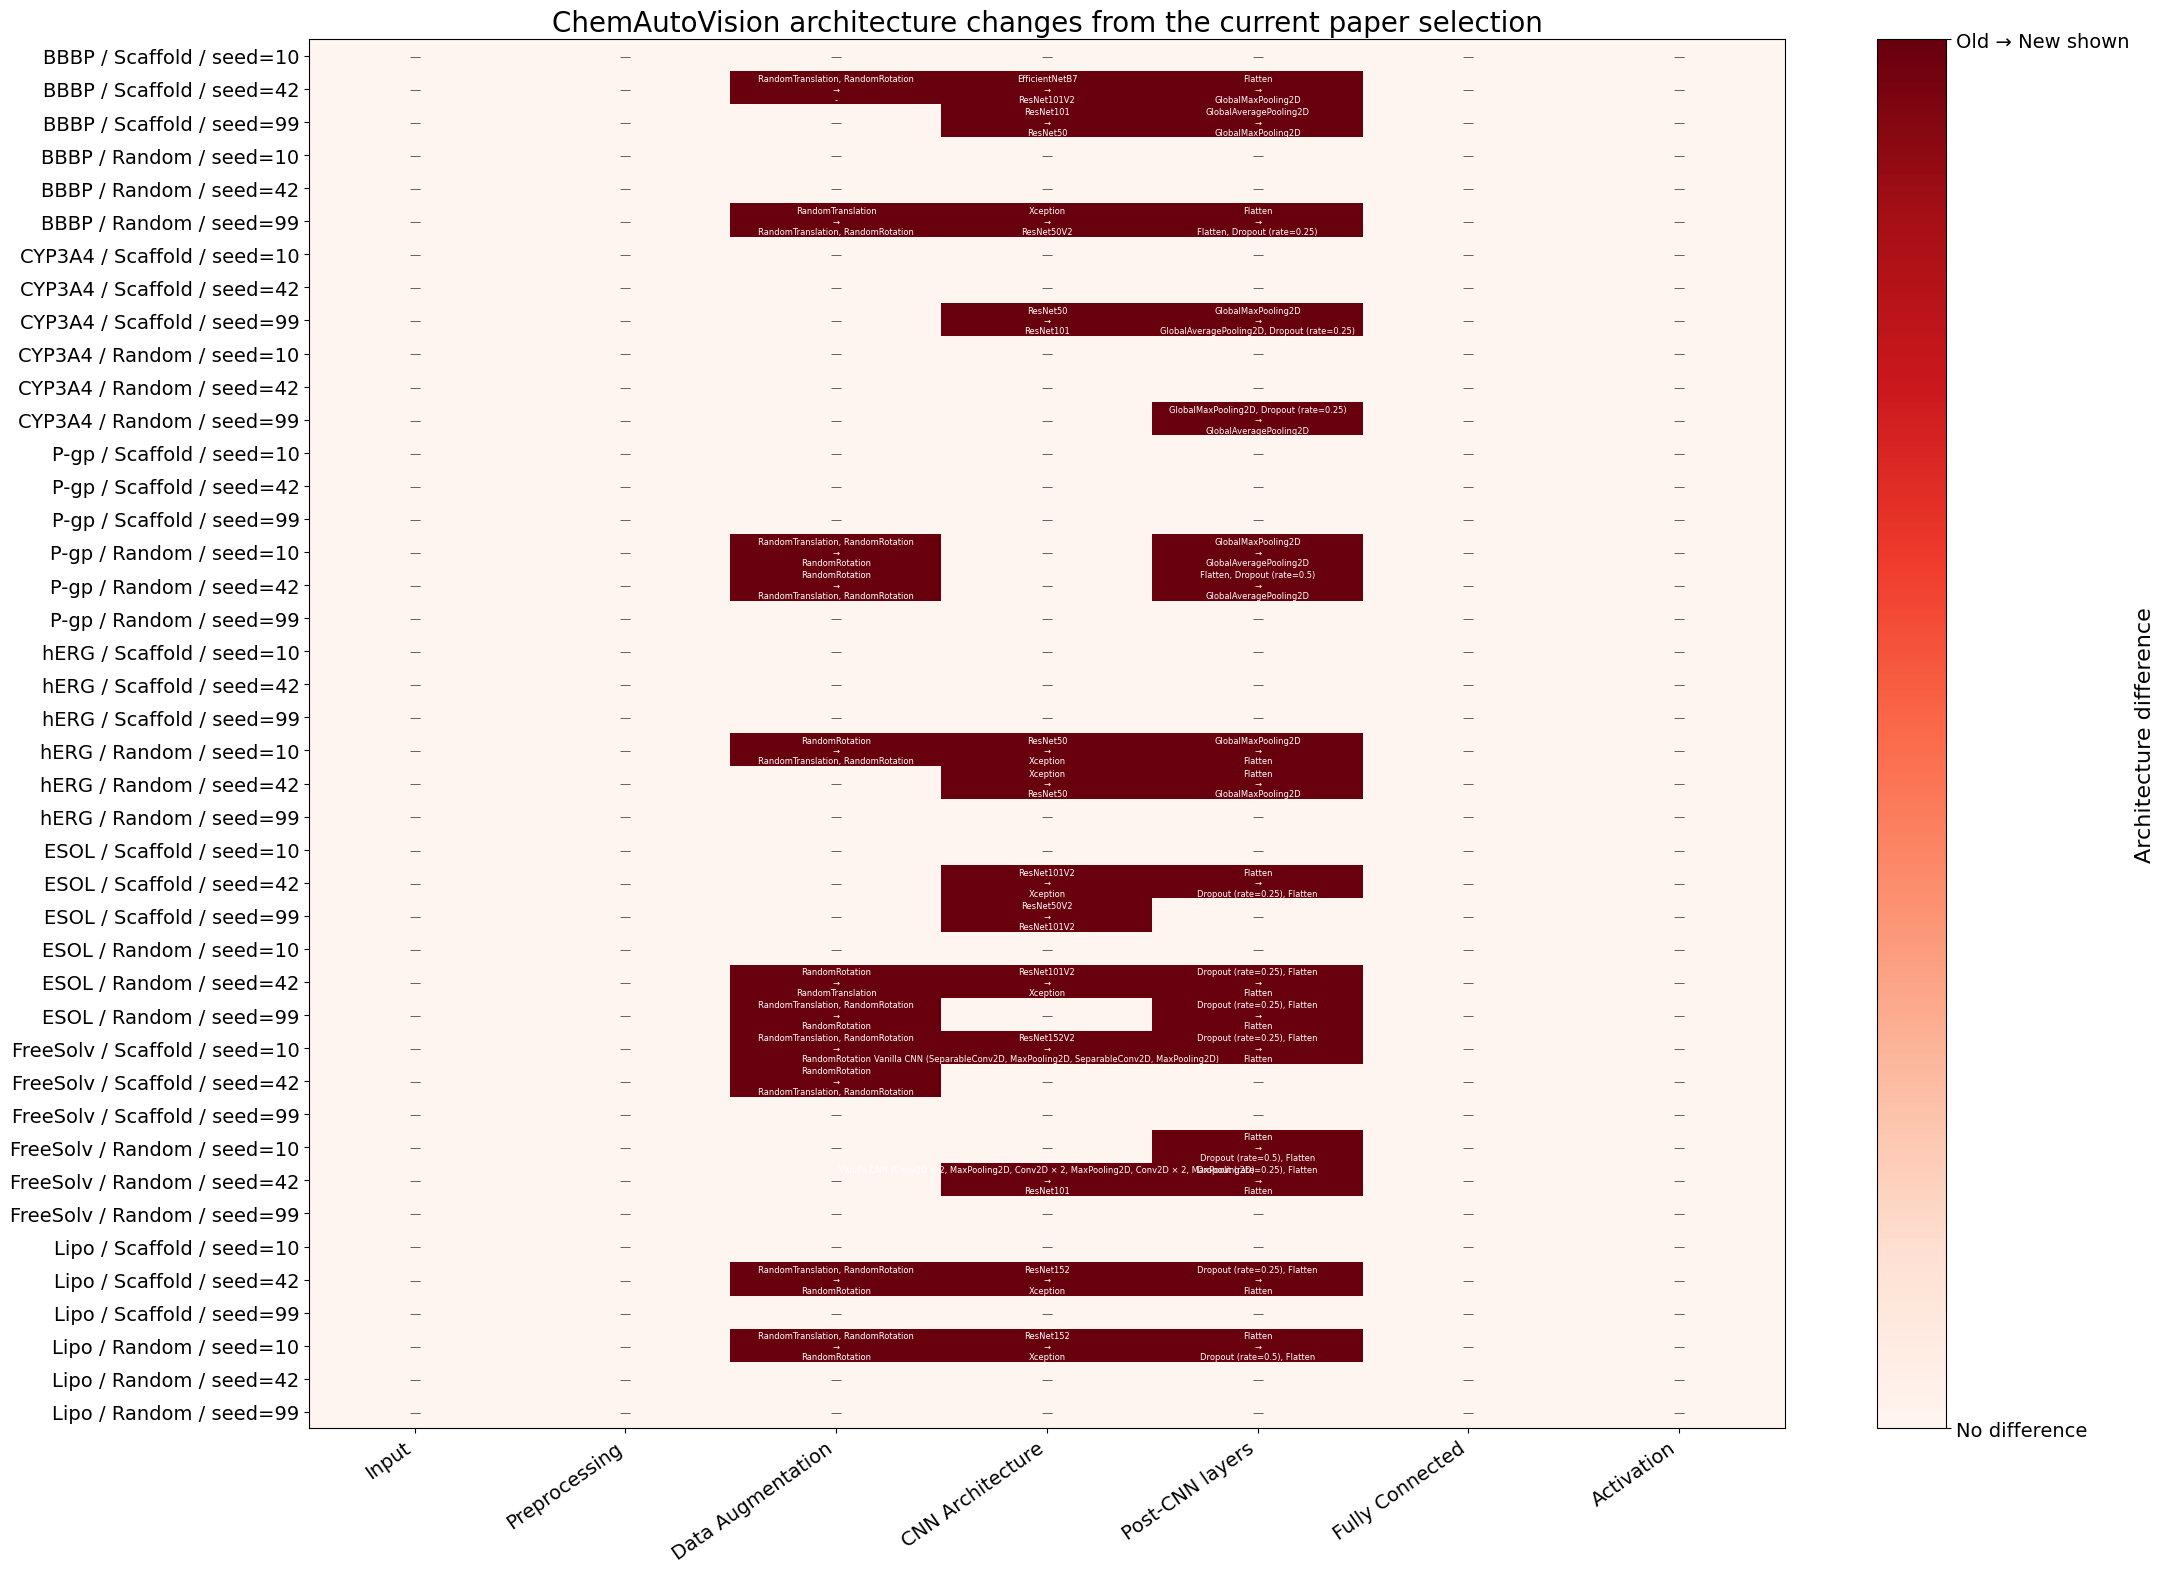

Architecture delta: ../../results/paper_tables/chem_autovision_architecture_delta.csv
Architecture impact summary: ../../results/paper_tables/chem_autovision_architecture_impact_summary.md


In [39]:
import importlib
from pathlib import Path
import evaluation_metric_report as evaluation_report

importlib.reload(evaluation_report)

PERFORMANCE_SEEDS = (10, 42, 99)
CLASSIFICATION_TARGETS = evaluation_report.CLASSIFICATION_TARGETS
REGRESSION_TARGETS = evaluation_report.REGRESSION_TARGETS
PERFORMANCE_MODEL_ORDER = evaluation_report.MODEL_ORDER
def build_evaluation_report_view(results):
    runs = pd.DataFrame(index=results.index, columns=evaluation_report.RUN_COLUMNS)
    runs['source'] = 'paper_evaluation_results.csv'
    runs['source_run_id'] = results['model_id']
    runs['model_type'] = results['paper_model_name']
    for column in (
        'task_type', 'target', 'split_type', 'split_seed', 'training_seed',
        'batch_size', 'learning_rate', 'data_augmentation',
        'selection_metric', 'selection_metric_value',
        'test_accuracy', 'test_roc_auc', 'test_precision', 'test_recall',
        'test_f1', 'test_mcc', 'test_rmse', 'test_mse', 'test_mae',
        'test_r2', 'test_inference_time_sec',
    ):
        runs[column] = results[column]
    # Local-only architecture cells resolve model artifacts by this readable ID.
    runs['model_path'] = results['model_id']
    return runs.reset_index(drop=True)

public_test_runs = build_evaluation_report_view(paper_results)
fingerprint_mask = paper_results['model_family'].eq('Fingerprint-based model')
mlflow_test_runs = public_test_runs.loc[~fingerprint_mask].reset_index(drop=True)
hyperopt_test_runs = public_test_runs.loc[fingerprint_mask].reset_index(drop=True)
imagemol_selected_inventory = (
    paper_results.loc[paper_results['model_family'].eq('ImageMol')]
    .groupby(['task_type', 'target', 'split_type'], dropna=False)
    .size().rename('selected_models').reset_index()
)
display(imagemol_selected_inventory)

all_test_runs = evaluation_report.combine_test_runs(
    mlflow_test_runs, hyperopt_test_runs
)
missing_test_runs = evaluation_report.validate_test_runs(
    all_test_runs,
    expected_seeds=PERFORMANCE_SEEDS,
    strict=True,
)
test_metric_summary = evaluation_report.summarize_test_metrics(all_test_runs)

display(all_test_runs.groupby(['source', 'task_type', 'model_type']).size().rename('runs'))
display(test_metric_summary)

# Recreate the architecture selection used by the current paper as the baseline.
legacy_cls_arch_runs = prepare_architecture_runs(df_cls_selection, 'classification')
legacy_reg_arch_runs = prepare_architecture_runs(df_reg_selection, 'regression')
legacy_arch_runs = pd.concat(
    [legacy_cls_arch_runs, legacy_reg_arch_runs], ignore_index=True
)
legacy_architecture_records = collect_paper_architectures(legacy_arch_runs)

# Architectures must follow the ChemAutoVision runs selected on validation data.
selected_arch_runs = mlflow_test_runs.loc[
    mlflow_test_runs['model_type'].eq('ChemAutoVision')
].copy()
selected_arch_runs['data_split_normalized'] = selected_arch_runs['split_type']
selected_arch_runs['split_seed_group'] = selected_arch_runs['split_seed'].fillna(-1)
selected_arch_runs['target_display'] = selected_arch_runs['target']
selected_arch_runs['compare_seed'] = selected_arch_runs['training_seed']
selected_arch_runs['Run ID'] = selected_arch_runs['source_run_id']
selected_arch_runs['batch_size_num'] = selected_arch_runs['batch_size']
selected_arch_runs['metric_value'] = selected_arch_runs['selection_metric_value']
selected_arch_runs['candidate_runs'] = 1
selected_run_summary = selected_arch_runs[[
    'task_type', 'data_split_normalized', 'split_seed', 'target_display',
    'compare_seed', 'batch_size_num', 'learning_rate',
    'selection_metric', 'metric_value',
    'Run ID', 'model_path',
]].copy()
selected_run_summary['model_exists'] = selected_run_summary['model_path'].apply(
    lambda path: resolve_notebook_model_path(path).exists()
)
selected_run_summary['model_filename'] = selected_run_summary['model_path'].apply(
    lambda path: resolve_notebook_model_path(path).name
)
ARCHITECTURE_TABLE_DIR = Path('../../results/paper_tables')
ARCHITECTURE_FIGURE_DIR = Path('../../results/paper_figures')
ARCHITECTURE_TABLE_DIR.mkdir(parents=True, exist_ok=True)
ARCHITECTURE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
selected_model_inventory = selected_run_summary.rename(columns={
    'data_split_normalized': 'split_type',
    'target_display': 'target',
    'compare_seed': 'training_seed',
    'batch_size_num': 'batch_size',
    'Run ID': 'evaluation_run_id',
})[[
    'task_type', 'target', 'split_type', 'split_seed', 'training_seed',
    'batch_size', 'learning_rate', 'evaluation_run_id', 'model_filename',
    'model_path', 'model_exists',
]].sort_values([
    'task_type', 'target', 'split_type', 'split_seed', 'training_seed',
], na_position='first').reset_index(drop=True)
missing_selected_models = selected_model_inventory.loc[
    ~selected_model_inventory['model_exists']
].copy()
selected_model_inventory.to_csv(
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_selected_model_inventory.csv',
    index=False,
)
missing_selected_models.to_csv(
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_missing_selected_models.csv',
    index=False,
)
display(Markdown('## Selected ChemAutoVision architectures'))
display(selected_run_summary)
display(Markdown(
    f'### Missing selected ChemAutoVision model files ({len(missing_selected_models)})'
))
display(missing_selected_models)
architecture_records = collect_paper_architectures(selected_arch_runs)
display_architecture_tables(architecture_records, 'random')
display_architecture_tables(architecture_records, 'balanced_scaffold')

architecture_records.to_csv(
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_selected_architectures.csv',
    index=False,
)
architecture_records.to_latex(
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_selected_architectures.tex',
    index=False, escape=True, longtable=True,
    caption='ChemAutoVision architectures selected by validation performance.',
    label='tab:chem_autovision_selected_architectures',
)
architecture_delta = evaluation_report.compare_architecture_records(
    legacy_architecture_records, architecture_records,
    components=ARCH_COMPONENTS,
)
architecture_delta_path = (
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_architecture_delta.csv'
)
architecture_delta.to_csv(architecture_delta_path, index=False)
changed_architecture = architecture_delta.loc[architecture_delta['changed']].copy()
display(Markdown('## ChemAutoVision architecture changes from current paper selection'))
display(changed_architecture[[
    'task_type', 'target', 'data_split', 'seed', 'component',
    'old_value', 'new_value', 'old_run_id', 'new_run_id',
]])
component_counts = changed_architecture['component'].value_counts()
changed_conditions = changed_architecture[[
    'task_type', 'target', 'data_split', 'seed'
]].drop_duplicates()
architecture_condition_status = architecture_delta.groupby([
    'task_type', 'target', 'data_split', 'seed'
])[['comparison_status']].agg(
    comparable=('comparison_status', lambda values: (values == 'comparable').all())
).reset_index()
comparable_architecture_conditions = int(
    architecture_condition_status['comparable'].sum()
)
unavailable_architecture_conditions = int(
    (~architecture_condition_status['comparable']).sum()
)
architecture_impact_lines = [
    '# ChemAutoVision architecture impact summary',
    '',
    f'- Selected conditions: {len(architecture_records)}',
    f'- Comparable conditions: {comparable_architecture_conditions}',
    f'- Conditions unavailable because a model file is missing: {unavailable_architecture_conditions}',
    f'- Comparable conditions with at least one changed component: {len(changed_conditions)}',
    '',
    '## Changed components',
    *[f'- {component}: {count}' for component, count in component_counts.items()],
    '',
    '## Conditions requiring architecture-description review',
]
architecture_impact_lines.extend(
    f"- {row.target} / {row.data_split} / seed={int(row.seed)}"
    for row in changed_conditions.itertuples()
)
architecture_impact_path = (
    ARCHITECTURE_TABLE_DIR / 'chem_autovision_architecture_impact_summary.md'
)
architecture_impact_path.write_text(
    '\n'.join(architecture_impact_lines) + '\n', encoding='utf-8'
)
architecture_delta_figure, architecture_delta_axis = (
    evaluation_report.plot_architecture_delta_heatmap(
        architecture_delta, components=ARCH_COMPONENTS
    )
)
for suffix in ('png', 'pdf'):
    architecture_figure_path = (
        ARCHITECTURE_FIGURE_DIR / f'chem_autovision_architecture_delta.{suffix}'
    )
    architecture_delta_figure.savefig(
        architecture_figure_path, dpi=300, bbox_inches='tight'
    )
display(architecture_delta_figure)
plt.close(architecture_delta_figure)
print(f'Architecture delta: {architecture_delta_path}')
print(f'Architecture impact summary: {architecture_impact_path}')

Saved: ../../results/paper_figures/test_roc_auc_by_split.png
Saved: ../../results/paper_figures/test_roc_auc_by_split.pdf


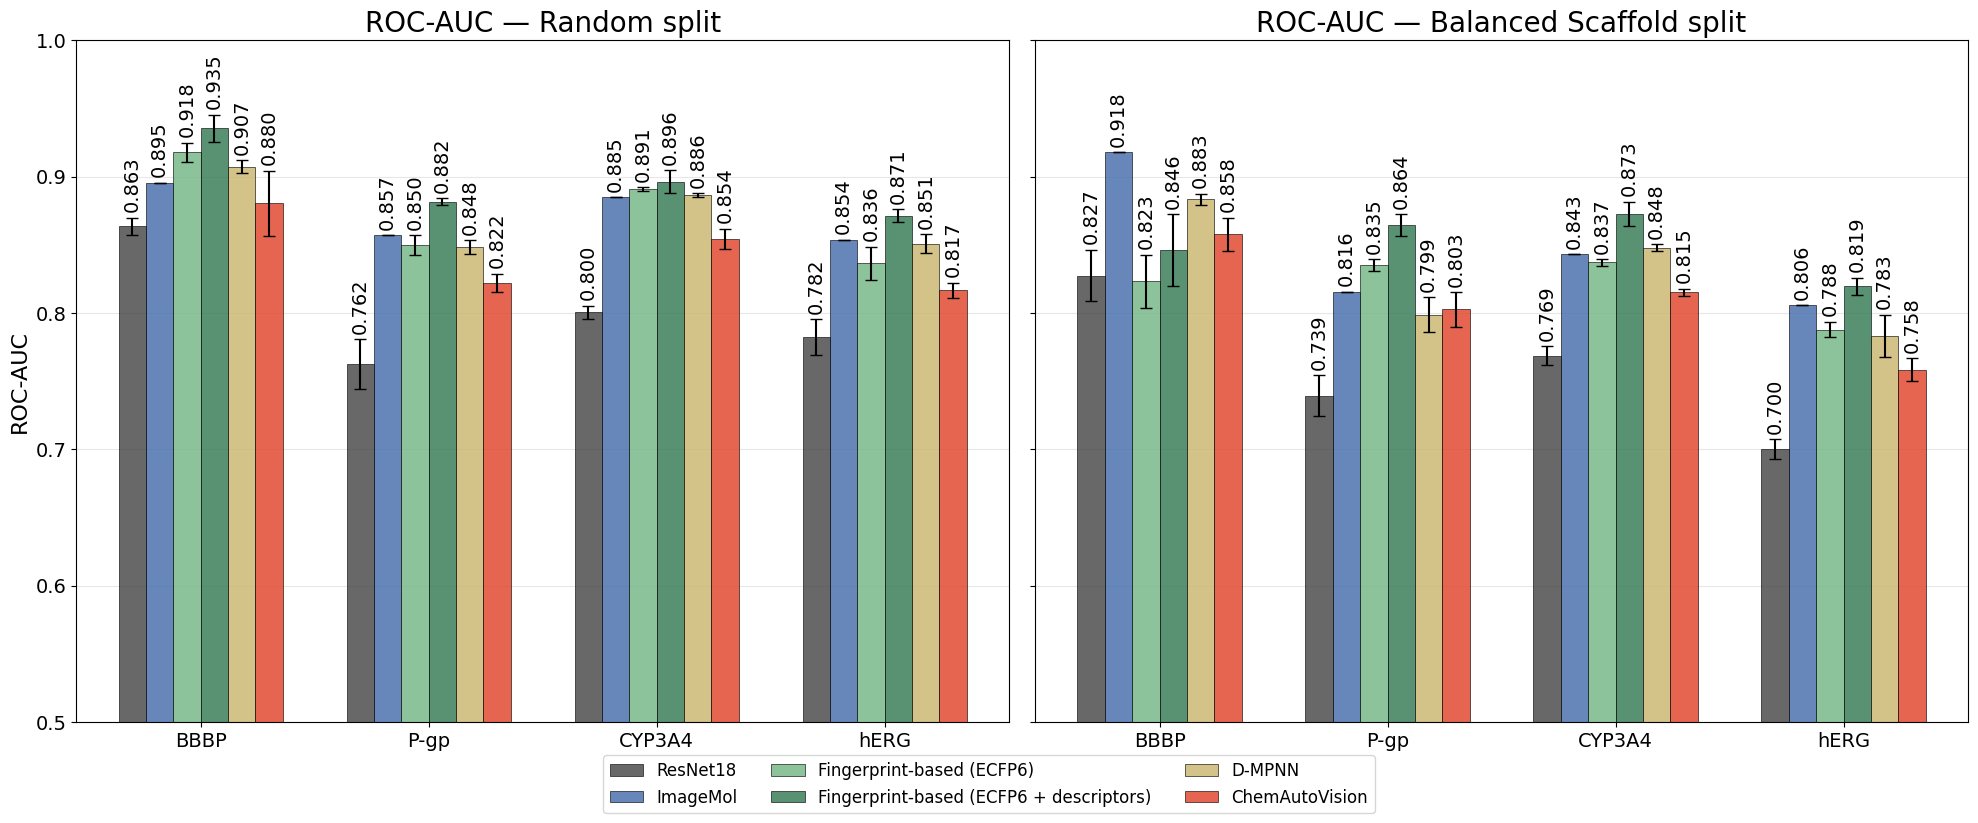

Saved: ../../results/paper_figures/test_rmse_by_split.png
Saved: ../../results/paper_figures/test_rmse_by_split.pdf


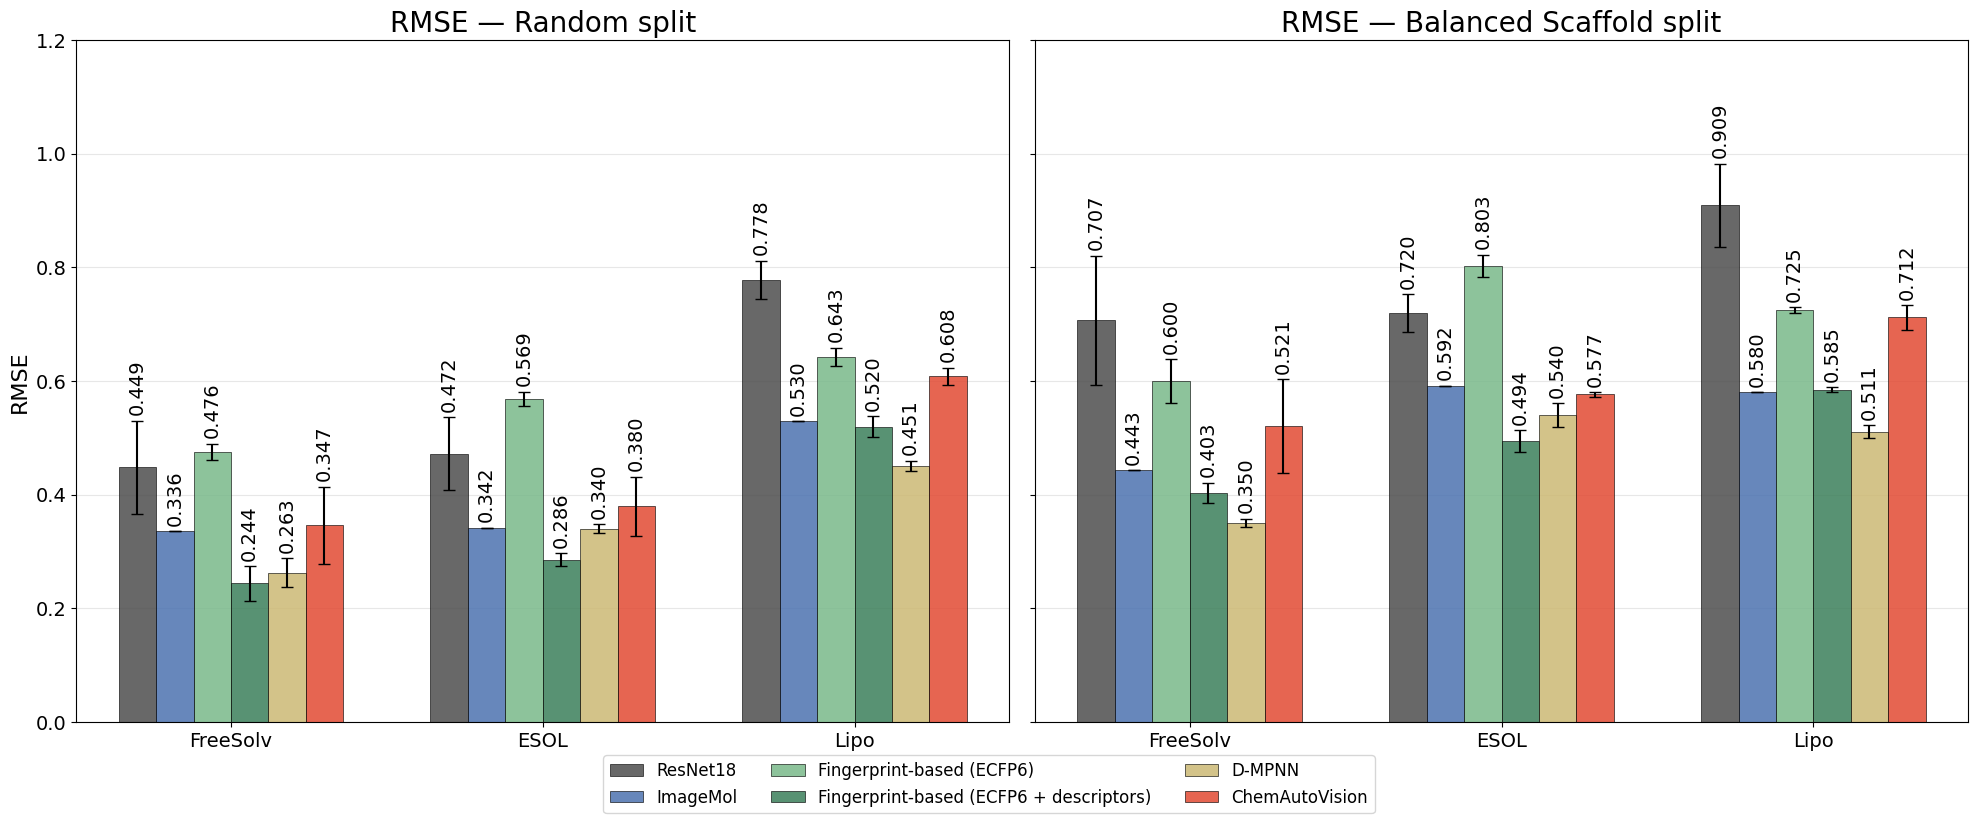

In [40]:
import evaluation_metric_report as evaluation_report
importlib.reload(evaluation_report)

PAPER_PERFORMANCE_FIGURE_DIR = Path('../../results/paper_figures')
PAPER_PERFORMANCE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_specs = {
    'test_roc_auc': {
        'targets': CLASSIFICATION_TARGETS,
        'stem': 'test_roc_auc_by_split',
        'y_limits': (0.5, 1.0),
    },
    'test_rmse': {
        'targets': REGRESSION_TARGETS,
        'stem': 'test_rmse_by_split',
        'y_limits': (0.0, 1.2),
    },
}
performance_figures = {}
for metric, spec in figure_specs.items():
    figure, axes = evaluation_report.plot_test_metric_by_split(
        test_metric_summary,
        metric=metric,
        targets=spec['targets'],
        model_order=PERFORMANCE_MODEL_ORDER,
        y_limits=spec['y_limits'],
    )
    performance_figures[metric] = (figure, axes)
    for suffix in ('png', 'pdf'):
        output_path = PAPER_PERFORMANCE_FIGURE_DIR / f"{spec['stem']}.{suffix}"
        figure.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f'Saved: {output_path}')
    display(figure)
    plt.close(figure)

## Conference-slide performance figures

Create separate ROC-AUC and RMSE figures from the same final-test summary while omitting `Fingerprint-based (ECFP6 + descriptors)`. The paper figures above remain unchanged.

Saved: ../../results/paper_figures/conference_slides/test_roc_auc_by_split_without_ecfp6_descriptors.png
Saved: ../../results/paper_figures/conference_slides/test_roc_auc_by_split_without_ecfp6_descriptors.pdf


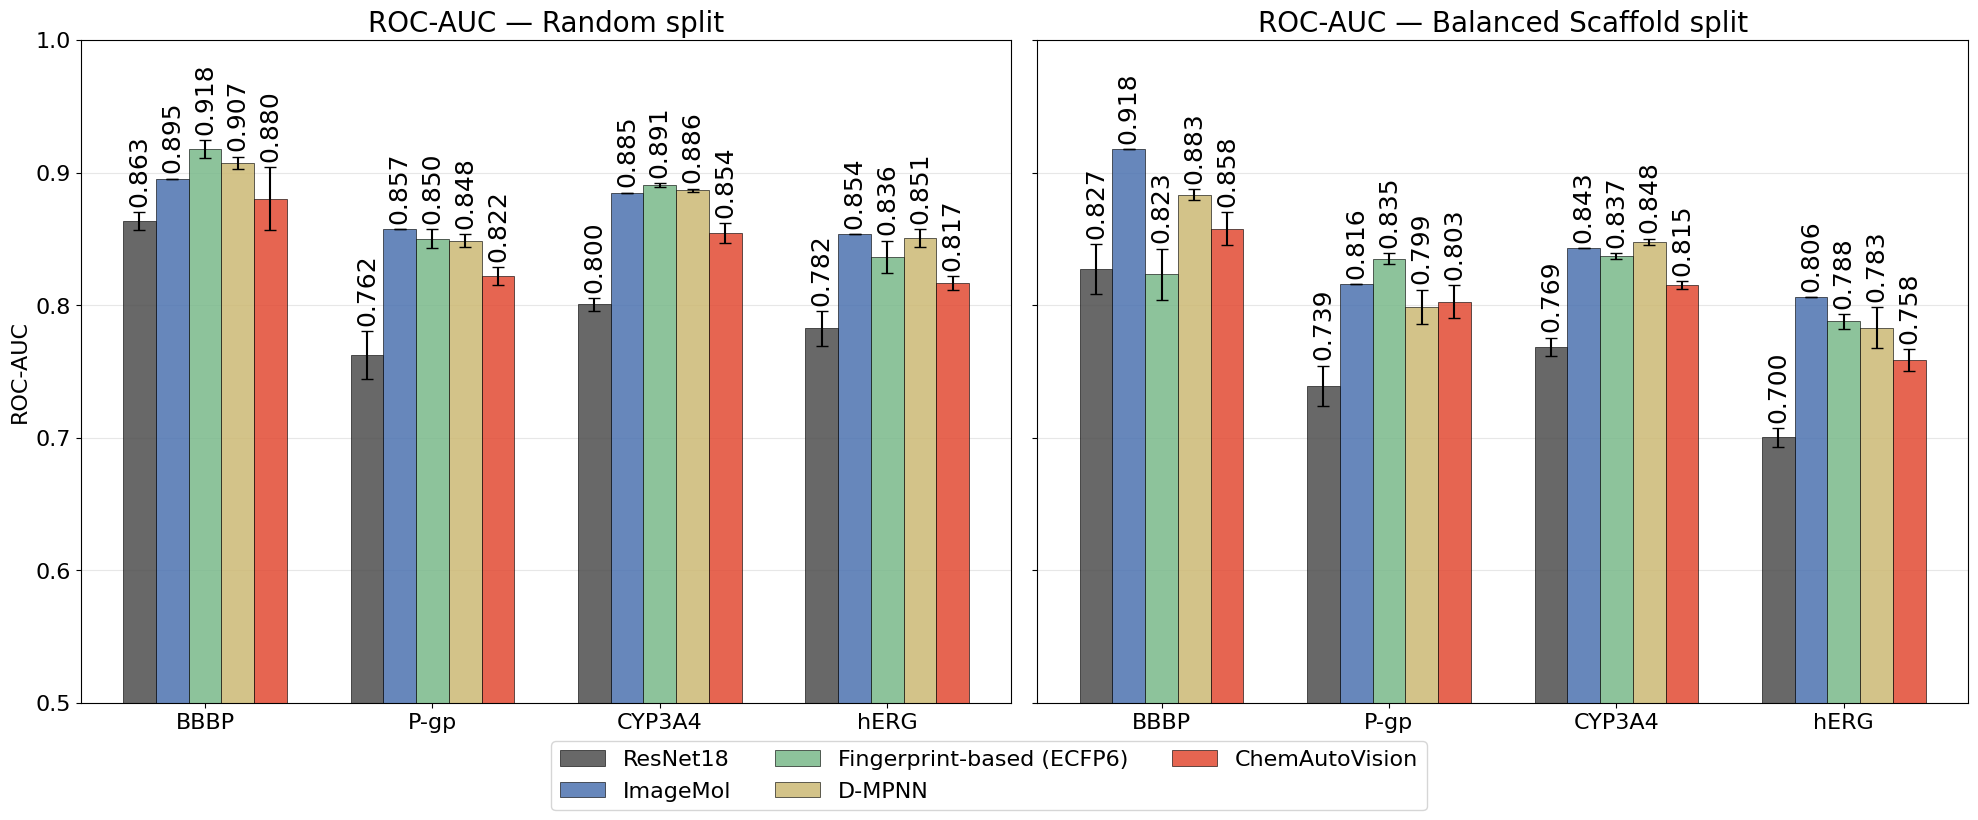

Saved: ../../results/paper_figures/conference_slides/test_rmse_by_split_without_ecfp6_descriptors.png
Saved: ../../results/paper_figures/conference_slides/test_rmse_by_split_without_ecfp6_descriptors.pdf


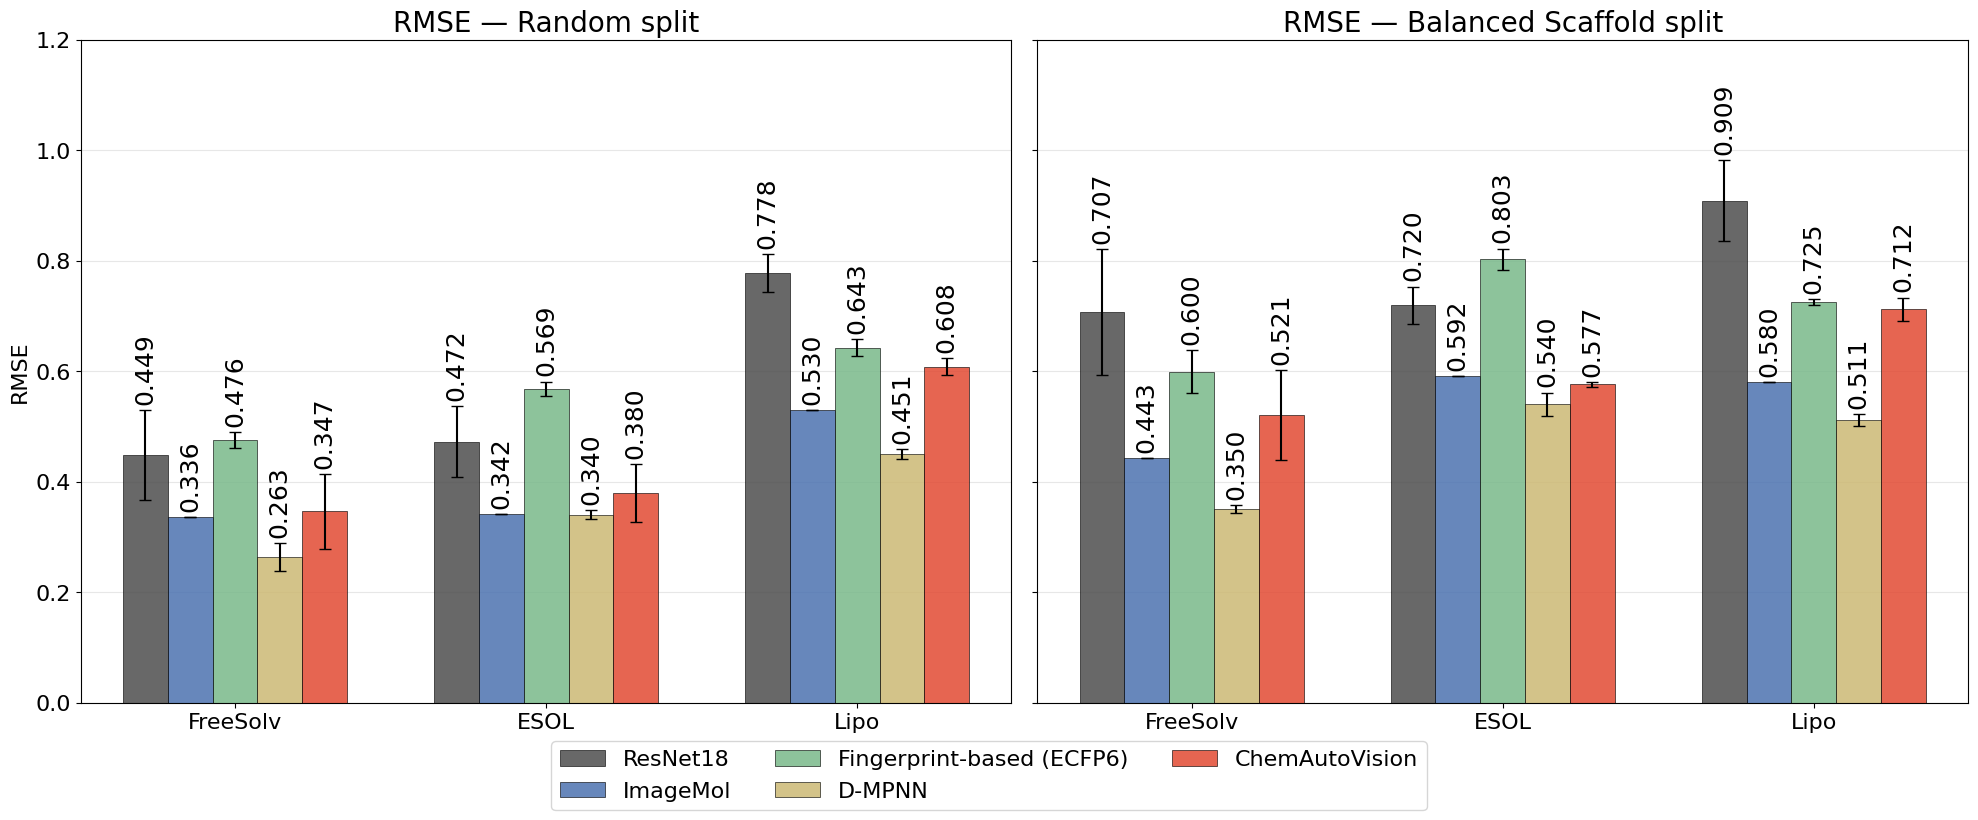

In [48]:
import importlib
from pathlib import Path
import evaluation_metric_report as evaluation_report
importlib.reload(evaluation_report)


CONFERENCE_FIGURE_DIR = PAPER_PERFORMANCE_FIGURE_DIR / 'conference_slides'
CONFERENCE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CONFERENCE_EXCLUDED_MODELS = {
    'Fingerprint-based (ECFP6 + descriptors)',
}
CONFERENCE_MODEL_ORDER = tuple(
    model
    for model in PERFORMANCE_MODEL_ORDER
    if model not in CONFERENCE_EXCLUDED_MODELS
)

conference_figure_specs = {
    'test_roc_auc': {
        'targets': CLASSIFICATION_TARGETS,
        'stem': 'test_roc_auc_by_split_without_ecfp6_descriptors',
        'y_limits': (0.5, 1.0),
    },
    'test_rmse': {
        'targets': REGRESSION_TARGETS,
        'stem': 'test_rmse_by_split_without_ecfp6_descriptors',
        'y_limits': (0.0, 1.2),
    },
}

conference_performance_figures = {}
for metric, spec in conference_figure_specs.items():
    figure, axes = evaluation_report.plot_test_metric_by_split(
        test_metric_summary,
        metric=metric,
        targets=spec['targets'],
        model_order=CONFERENCE_MODEL_ORDER,
        y_limits=spec['y_limits'],
    )
    conference_performance_figures[metric] = (figure, axes)
    for suffix in ('png', 'pdf'):
        output_path = CONFERENCE_FIGURE_DIR / f"{spec['stem']}.{suffix}"
        figure.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f'Saved: {output_path}')
    display(figure)
    plt.close(figure)

In [42]:
PAPER_METRIC_TABLE_DIR = Path('../../results/paper_tables')
PAPER_METRIC_TABLE_DIR.mkdir(parents=True, exist_ok=True)
test_metric_summary.to_csv(
    PAPER_METRIC_TABLE_DIR / 'test_metrics_audit.csv', index=False
)

table_specs = {
    'classification': CLASSIFICATION_TARGETS,
    'regression': REGRESSION_TARGETS,
}
performance_metric_tables = {}
for task_type, targets in table_specs.items():
    for split_type in evaluation_report.DEFAULT_SPLITS:
        display_table, latex_table = evaluation_report.build_metric_table(
            test_metric_summary,
            task_type=task_type,
            split_type=split_type,
            targets=targets,
            model_order=PERFORMANCE_MODEL_ORDER,
            include_mse=True,
            decimals=3,
        )
        key = (task_type, split_type)
        performance_metric_tables[key] = display_table
        stem = f'test_{task_type}_{split_type}'
        csv_path = PAPER_METRIC_TABLE_DIR / f'{stem}.csv'
        tex_path = PAPER_METRIC_TABLE_DIR / f'{stem}.tex'
        display_table.to_csv(csv_path, index=False)
        latex_table.to_latex(
            tex_path, index=False, escape=False, longtable=True,
            caption=f'Test performance for {task_type} models ({split_type}).',
            label=f'tab:{stem}',
        )
        display(Markdown(f'### {task_type.title()} — {split_type.replace("_", " " ).title()}'))
        display(display_table)
        print(f'CSV: {csv_path}')
        print(f'LaTeX: {tex_path}')

### Classification — Random

,Dataset,Model,ROC-AUC,Acc,Prec,Rec,F1,MCC
0,BBBP,ResNet18,0.863 ± 0.006,0.621 ± 0.316,0.905 ± 0.101,0.608 ± 0.516,0.596 ± 0.482,0.320 ± 0.234
1,BBBP,ImageMol,0.895,0.864,0.915,0.906,0.910,0.633
2,BBBP,Fingerprint-based (ECFP6),0.918 ± 0.007,0.883 ± 0.011,0.899 ± 0.012,0.954 ± 0.005,0.925 ± 0.006,0.664 ± 0.034
3,BBBP,Fingerprint-based (ECFP6 + descriptors),0.935 ± 0.010,0.902 ± 0.010,0.924 ± 0.009,0.949 ± 0.017,0.936 ± 0.007,0.725 ± 0.025
4,BBBP,D-MPNN,0.907 ± 0.005,0.853 ± 0.052,0.922 ± 0.021,0.882 ± 0.096,0.899 ± 0.043,0.631 ± 0.065
5,BBBP,ChemAutoVision,0.880 ± 0.024,0.861 ± 0.009,0.913 ± 0.022,0.903 ± 0.026,0.908 ± 0.006,0.625 ± 0.033
6,P-gp,ResNet18,0.762 ± 0.018,0.672 ± 0.046,0.741 ± 0.056,0.634 ± 0.210,0.663 ± 0.117,0.366 ± 0.043
7,P-gp,ImageMol,0.857,0.772,0.760,0.847,0.801,0.540
8,P-gp,Fingerprint-based (ECFP6),0.850 ± 0.007,0.771 ± 0.006,0.817 ± 0.021,0.747 ± 0.036,0.780 ± 0.012,0.546 ± 0.011
9,P-gp,Fingerprint-based (ECFP6 + descriptors),0.882 ± 0.002,0.791 ± 0.007,0.825 ± 0.006,0.781 ± 0.012,0.802 ± 0.007,0.583 ± 0.013


CSV: ../../results/paper_tables/test_classification_random.csv
LaTeX: ../../results/paper_tables/test_classification_random.tex


### Classification — Balanced Scaffold

,Dataset,Model,ROC-AUC,Acc,Prec,Rec,F1,MCC
0,BBBP,ResNet18,0.827 ± 0.019,0.566 ± 0.316,0.618 ± 0.535,0.495 ± 0.432,0.549 ± 0.476,0.288 ± 0.251
1,BBBP,ImageMol,0.918,0.893,0.950,0.913,0.931,0.690
2,BBBP,Fingerprint-based (ECFP6),0.823 ± 0.019,0.870 ± 0.018,0.900 ± 0.010,0.941 ± 0.039,0.920 ± 0.013,0.582 ± 0.035
3,BBBP,Fingerprint-based (ECFP6 + descriptors),0.846 ± 0.026,0.886 ± 0.022,0.922 ± 0.004,0.936 ± 0.026,0.929 ± 0.014,0.644 ± 0.059
4,BBBP,D-MPNN,0.883 ± 0.004,0.787 ± 0.117,0.942 ± 0.014,0.783 ± 0.169,0.847 ± 0.102,0.527 ± 0.118
5,BBBP,ChemAutoVision,0.858 ± 0.012,0.810 ± 0.059,0.923 ± 0.007,0.831 ± 0.077,0.873 ± 0.045,0.509 ± 0.090
6,P-gp,ResNet18,0.739 ± 0.015,0.650 ± 0.044,0.647 ± 0.050,0.903 ± 0.090,0.750 ± 0.009,0.263 ± 0.097
7,P-gp,ImageMol,0.816,0.728,0.809,0.693,0.747,0.462
8,P-gp,Fingerprint-based (ECFP6),0.835 ± 0.004,0.756 ± 0.012,0.832 ± 0.009,0.726 ± 0.031,0.775 ± 0.016,0.517 ± 0.017
9,P-gp,Fingerprint-based (ECFP6 + descriptors),0.864 ± 0.008,0.806 ± 0.002,0.837 ± 0.005,0.826 ± 0.010,0.832 ± 0.003,0.603 ± 0.003


...

,Dataset,Model,RMSE,MSE,MAE,$R^2$
0,FreeSolv,ResNet18,0.449 ± 0.082,0.206 ± 0.075,0.312 ± 0.058,0.805 ± 0.072
1,FreeSolv,ImageMol,0.336,0.113,0.247,0.893
2,FreeSolv,Fingerprint-based (ECFP6),0.476 ± 0.014,0.227 ± 0.013,0.303 ± 0.018,0.785 ± 0.012
3,FreeSolv,Fingerprint-based (ECFP6 + descriptors),0.244 ± 0.031,0.060 ± 0.015,0.140 ± 0.017,0.943 ± 0.014
4,FreeSolv,D-MPNN,0.263 ± 0.025,0.070 ± 0.013,0.159 ± 0.004,0.934 ± 0.013
5,FreeSolv,ChemAutoVision,0.347 ± 0.068,0.123 ± 0.049,0.244 ± 0.061,0.883 ± 0.047
6,ESOL,ResNet18,0.472 ± 0.064,0.226 ± 0.061,0.360 ± 0.051,0.762 ± 0.064
7,ESOL,ImageMol,0.342,0.117,0.254,0.876
8,ESOL,Fingerprint-based (ECFP6),0.569 ± 0.013,0.324 ± 0.015,0.418 ± 0.011,0.658 ± 0.015
9,ESOL,Fingerprint-based (ECFP6 + descriptors),0.286 ± 0.011,0.082 ± 0.006,0.206 ± 0.006,0.914 ± 0.007


CSV: ../../results/paper_tables/test_regression_random.csv
LaTeX: ../../results/paper_tables/test_regression_random.tex


### Regression — Balanced Scaffold

,Dataset,Model,RMSE,MSE,MAE,$R^2$
0,FreeSolv,ResNet18,0.707 ± 0.114,0.509 ± 0.155,0.560 ± 0.107,0.205 ± 0.243
1,FreeSolv,ImageMol,0.443,0.196,0.352,0.693
2,FreeSolv,Fingerprint-based (ECFP6),0.600 ± 0.039,0.361 ± 0.046,0.492 ± 0.021,0.436 ± 0.073
3,FreeSolv,Fingerprint-based (ECFP6 + descriptors),0.403 ± 0.018,0.163 ± 0.015,0.318 ± 0.007,0.746 ± 0.023
4,FreeSolv,D-MPNN,0.350 ± 0.007,0.123 ± 0.005,0.270 ± 0.008,0.808 ± 0.008
5,FreeSolv,ChemAutoVision,0.521 ± 0.082,0.276 ± 0.083,0.402 ± 0.058,0.569 ± 0.130
6,ESOL,ResNet18,0.720 ± 0.033,0.519 ± 0.049,0.566 ± 0.027,0.553 ± 0.042
7,ESOL,ImageMol,0.592,0.350,0.461,0.699
8,ESOL,Fingerprint-based (ECFP6),0.803 ± 0.019,0.645 ± 0.031,0.646 ± 0.029,0.445 ± 0.027
9,ESOL,Fingerprint-based (ECFP6 + descriptors),0.494 ± 0.019,0.245 ± 0.019,0.386 ± 0.015,0.790 ± 0.016


CSV: ../../results/paper_tables/test_regression_balanced_scaffold.csv
LaTeX: ../../results/paper_tables/test_regression_balanced_scaffold.tex


## Change from the current paper figures and tables

The existing `classification_performance.csv` and `regression_performance.csv` files are treated as the published baseline. Positive heatmap values always indicate improvement; note that baseline values are rounded to three decimals.

,target,split_type,model_type,metric,old_mean,new_mean,delta,improvement,old_rank,new_rank,best_model_changed,impact_level
5,BBBP,balanced_scaffold,ChemAutoVision,test_roc_auc,0.875,0.857786,-0.017214,-0.017214,3.0,3.0,False,review
11,BBBP,random,ChemAutoVision,test_roc_auc,0.893,0.880370,-0.012630,-0.012630,5.0,5.0,False,review
17,CYP3A4,balanced_scaffold,ChemAutoVision,test_roc_auc,0.817,0.815179,-0.001821,-0.001821,5.0,5.0,False,minor
23,CYP3A4,random,ChemAutoVision,test_roc_auc,0.855,0.854286,-0.000714,-0.000714,5.0,5.0,False,minor
29,P-gp,balanced_scaffold,ChemAutoVision,test_roc_auc,0.803,0.802621,-0.000379,-0.000379,5.0,4.0,False,minor
...,...,...,...,...,...,...,...,...,...,...,...,...
415,ESOL,random,ResNet18,test_rmse,0.463,0.472325,0.009325,-0.009325,5.0,5.0,False,review
419,FreeSolv,balanced_scaffold,ResNet18,test_rmse,0.572,0.707241,0.135241,-0.135241,5.0,6.0,False,major
423,FreeSolv,random,ResNet18,test_rmse,0.448,0.448501,0.000501,-0.000501,5.0,5.0,False,minor
427,Lipo,balanced_scaffold,ResNet18,test_rmse,0.906,0.909139,0.003139,-0.003139,6.0,6.0,False,minor


Delta CSV: ../../results/paper_tables/test_performance_delta.csv
Impact summary: ../../results/paper_tables/manuscript_impact_summary.md


## Selected-run hyperparameter changes

,task_type,target,split_type,model_type,training_seed,old_batch_size,new_batch_size,batch_size_status,old_learning_rate,new_learning_rate,learning_rate_status,old_run_id,new_run_id
0,classification,BBBP,balanced_scaffold,ChemAutoVision,10.0,16.0,16.0,unchanged,NaN,NaN,not_recorded,b89413f558eb4947b28205af51cf635d,0d7c008688c5442dbd4e4e8c6c5bf514
1,classification,BBBP,balanced_scaffold,ChemAutoVision,42.0,16.0,8.0,changed,NaN,NaN,not_recorded,5ffafd1ac0bf472b9694da77cd7aedec,77eae954e51146e6855292251915862b
2,classification,BBBP,balanced_scaffold,ChemAutoVision,99.0,32.0,64.0,changed,NaN,NaN,not_recorded,054ec1490aca488eb277646841f69399,de4b3e31f0234ce3b92a9eb019d56b14
3,classification,BBBP,random,ChemAutoVision,10.0,32.0,32.0,unchanged,NaN,NaN,not_recorded,76d842a90cd842d5a886854d57334b94,a2ed5a401fca4e109d39b2f5ee88ae62
4,classification,BBBP,random,ChemAutoVision,42.0,8.0,8.0,unchanged,NaN,NaN,not_recorded,b27a1cc084bb4e86a9f33f8085f81e8e,a50792530b0c4cb194d56df0fe05fec6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,regression,Lipo,balanced_scaffold,ResNet18,42.0,16.0,8.0,changed,0.001941,0.000047,changed,26cd6093cc72432e9863d92fa15a0c75,1217aece754a4737862695dda519acde
220,regression,Lipo,balanced_scaffold,ResNet18,99.0,8.0,8.0,unchanged,0.000015,0.000015,unchanged,2d591d7cbec749198c8d8e195e3189c9,251c69efe38f45b7bcaac857ef6ad796
221,regression,Lipo,random,ResNet18,10.0,8.0,8.0,unchanged,0.000027,0.000027,unchanged,fb6ca51d11654f4382259b409beacce2,2e99f02ff2234ee2af9cbb2e47f9af31
222,regression,Lipo,random,ResNet18,42.0,64.0,64.0,unchanged,0.000031,0.000031,unchanged,ab896fe3eaf04d1c8bded6c3b6602307,b3000c1d1b3741d698d460c462cdac91


,model_type,conditions,batch_size_changed,learning_rate_changed
0,ChemAutoVision,42,20,0
1,D-MPNN,42,22,0
2,Fingerprint-based (ECFP6 + descriptors),42,0,0
3,Fingerprint-based (ECFP6),42,0,0
4,ImageMol,14,9,2
5,ResNet18,42,16,16


Hyperparameter delta: ../../results/paper_tables/selected_hyperparameter_delta.csv
Hyperparameter summary CSV: ../../results/paper_tables/selected_hyperparameter_change_summary.csv
Hyperparameter summary: ../../results/paper_tables/selected_hyperparameter_impact_summary.md
Saved: ../../results/paper_figures/selected_hyperparameter_change_summary.png
Saved: ../../results/paper_figures/selected_hyperparameter_change_summary.pdf


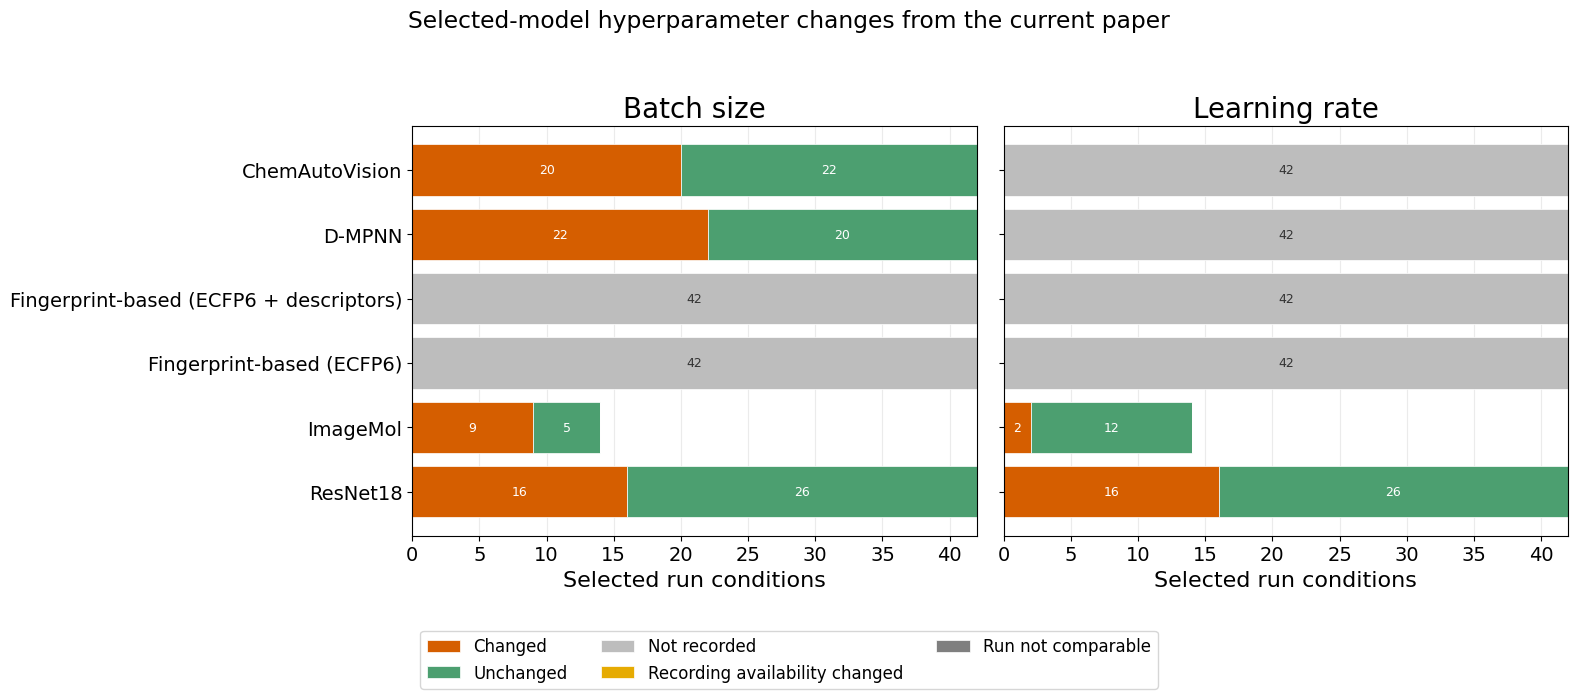

Saved: ../../results/paper_figures/roc_auc_delta_heatmap.png
Saved: ../../results/paper_figures/roc_auc_delta_heatmap.pdf


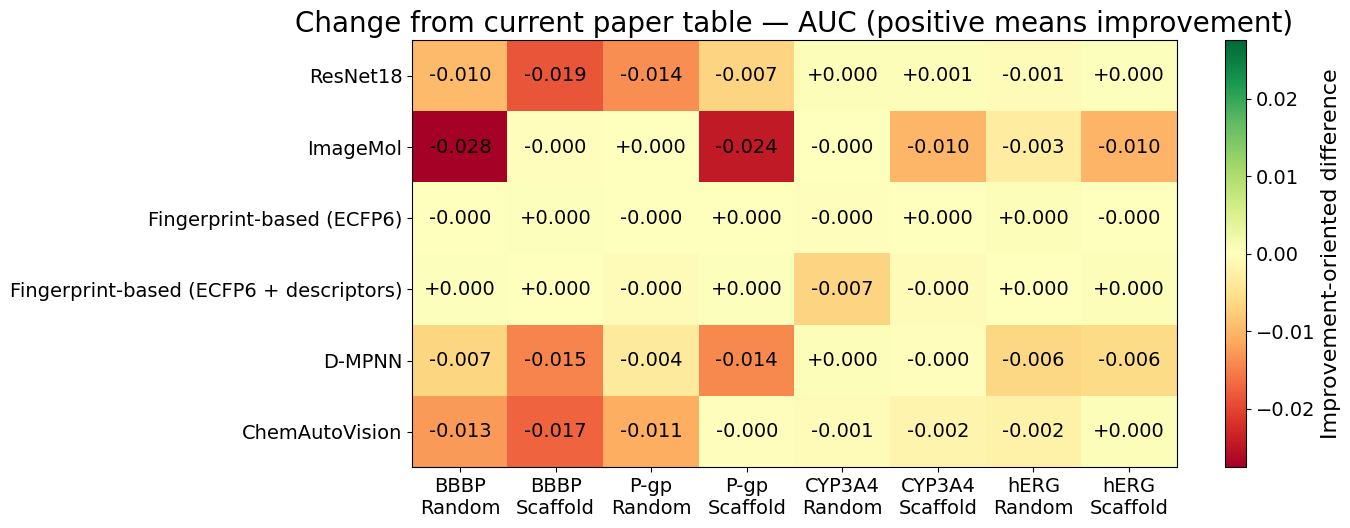

Saved: ../../results/paper_figures/rmse_delta_heatmap.png
Saved: ../../results/paper_figures/rmse_delta_heatmap.pdf


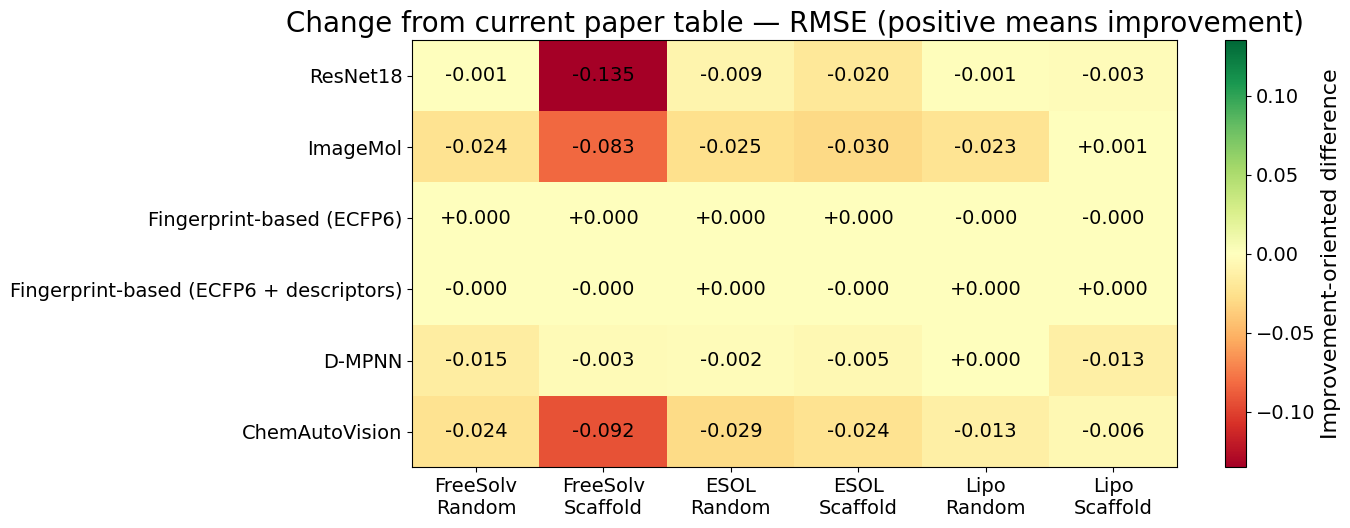

In [194]:
import seed_metric_plots
importlib.reload(seed_metric_plots)

paper_baseline = evaluation_report.load_paper_table_baseline(
    PAPER_METRIC_TABLE_DIR / 'classification_performance.csv',
    PAPER_METRIC_TABLE_DIR / 'regression_performance.csv',
)
paper_performance_delta = evaluation_report.compare_with_paper_baseline(
    paper_baseline, test_metric_summary
)
delta_csv_path = PAPER_METRIC_TABLE_DIR / 'test_performance_delta.csv'
paper_performance_delta.to_csv(delta_csv_path, index=False)

primary_delta = paper_performance_delta.loc[
    paper_performance_delta['metric'].isin(['test_roc_auc', 'test_rmse'])
].copy()
primary_delta.to_csv(
    PAPER_METRIC_TABLE_DIR / 'primary_metric_delta.csv', index=False
)
display(primary_delta[[
    'target', 'split_type', 'model_type', 'metric',
    'old_mean', 'new_mean', 'delta', 'improvement',
    'old_rank', 'new_rank', 'best_model_changed', 'impact_level',
]])

impact_counts = paper_performance_delta['impact_level'].value_counts()
winner_changes = paper_performance_delta.loc[
    paper_performance_delta['best_model_changed']
    & paper_performance_delta['metric'].isin(['test_roc_auc', 'test_rmse']),
    ['task_type', 'target', 'split_type', 'metric'],
].drop_duplicates()
impact_lines = [
    '# Manuscript performance impact summary',
    '',
    'Baseline: results/paper_tables/classification_performance.csv and regression_performance.csv',
    '',
    '## Impact counts',
    *[f'- {level}: {count}' for level, count in impact_counts.items()],
    '',
    '## Primary-metric conditions where the best model changed',
]
if winner_changes.empty:
    impact_lines.append('- None')
else:
    impact_lines.extend(
        f"- {row.target} / {row.split_type} / {row.metric}"
        for row in winner_changes.itertuples()
    )
impact_path = PAPER_METRIC_TABLE_DIR / 'manuscript_impact_summary.md'
impact_path.write_text('\n'.join(impact_lines) + '\n', encoding='utf-8')
print(f'Delta CSV: {delta_csv_path}')
print(f'Impact summary: {impact_path}')

# Compare hyperparameters of the runs behind the old and new paper results.
legacy_performance_runs = seed_metric_plots.select_paper_performance_runs(
    df_cls.copy(),
    df_reg.copy(),
    classification_targets=CLASSIFICATION_TARGETS,
    regression_targets=REGRESSION_TARGETS,
    seeds=PERFORMANCE_SEEDS,
    max_trials=100,
    max_evals=100,
    scaffold_split_seed=42,
    maximum_imagemol_batch_size=64,
)
old_selected_hyperparameters = (
    evaluation_report.flatten_legacy_hyperparameters(legacy_performance_runs)
)
selected_hyperparameter_delta = (
    evaluation_report.compare_selected_hyperparameters(
        old_selected_hyperparameters, all_test_runs
    )
)
hyperparameter_delta_path = (
    PAPER_METRIC_TABLE_DIR / 'selected_hyperparameter_delta.csv'
)
selected_hyperparameter_delta.to_csv(hyperparameter_delta_path, index=False)
display(Markdown('## Selected-run hyperparameter changes'))
display(selected_hyperparameter_delta[[
    'task_type', 'target', 'split_type', 'model_type', 'training_seed',
    'old_batch_size', 'new_batch_size', 'batch_size_status',
    'old_learning_rate', 'new_learning_rate', 'learning_rate_status',
    'old_run_id', 'new_run_id',
]])
batch_changed = int(selected_hyperparameter_delta['batch_size_changed'].sum())
learning_rate_changed = int(
    selected_hyperparameter_delta['learning_rate_changed'].sum()
)
batch_unknown = int(
    selected_hyperparameter_delta['batch_size_status'].eq('not_recorded').sum()
)
learning_rate_unknown = int(
    selected_hyperparameter_delta['learning_rate_status'].eq('not_recorded').sum()
)
batch_recording_changed = int(
    selected_hyperparameter_delta['batch_size_status'].eq('recording_changed').sum()
)
learning_rate_recording_changed = int(
    selected_hyperparameter_delta['learning_rate_status'].eq('recording_changed').sum()
)
hyperparameter_change_summary = (
    selected_hyperparameter_delta.groupby('model_type')
    .agg(
        conditions=('model_type', 'size'),
        batch_size_changed=('batch_size_changed', 'sum'),
        learning_rate_changed=('learning_rate_changed', 'sum'),
    )
    .reset_index()
)
hyperparameter_summary_csv_path = (
    PAPER_METRIC_TABLE_DIR / 'selected_hyperparameter_change_summary.csv'
)
hyperparameter_change_summary.to_csv(
    hyperparameter_summary_csv_path, index=False
)
display(hyperparameter_change_summary)
hyperparameter_impact_lines = [
    '# Selected-run hyperparameter impact summary',
    '',
    f'- Batch size changed: {batch_changed} conditions',
    f'- Learning rate changed: {learning_rate_changed} conditions',
    f'- Batch size not recorded on either side: {batch_unknown} conditions',
    f'- Learning rate not recorded on either side: {learning_rate_unknown} conditions',
    f'- Batch-size recording availability changed: {batch_recording_changed} conditions',
    f'- Learning-rate recording availability changed: {learning_rate_recording_changed} conditions',
    '',
    'See selected_hyperparameter_delta.csv for old/new values and run IDs.',
]
hyperparameter_impact_path = (
    PAPER_METRIC_TABLE_DIR / 'selected_hyperparameter_impact_summary.md'
)
hyperparameter_impact_path.write_text(
    '\n'.join(hyperparameter_impact_lines) + '\n', encoding='utf-8'
)
print(f'Hyperparameter delta: {hyperparameter_delta_path}')
print(f'Hyperparameter summary CSV: {hyperparameter_summary_csv_path}')
print(f'Hyperparameter summary: {hyperparameter_impact_path}')
hyperparameter_figure, hyperparameter_axes = (
    evaluation_report.plot_hyperparameter_change_summary(
        selected_hyperparameter_delta, model_order=PERFORMANCE_MODEL_ORDER
    )
)
for suffix in ('png', 'pdf'):
    hyperparameter_figure_path = (
        PAPER_PERFORMANCE_FIGURE_DIR
        / f'selected_hyperparameter_change_summary.{suffix}'
    )
    hyperparameter_figure.savefig(
        hyperparameter_figure_path, dpi=300, bbox_inches='tight'
    )
    print(f'Saved: {hyperparameter_figure_path}')
display(hyperparameter_figure)
plt.close(hyperparameter_figure)

for metric in ('test_roc_auc', 'test_rmse'):
    figure, axis = evaluation_report.plot_metric_delta_heatmap(
        paper_performance_delta, metric=metric,
        model_order=PERFORMANCE_MODEL_ORDER,
    )
    stem = metric.removeprefix('test_') + '_delta_heatmap'
    for suffix in ('png', 'pdf'):
        output_path = PAPER_PERFORMANCE_FIGURE_DIR / f'{stem}.{suffix}'
        figure.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f'Saved: {output_path}')
    display(figure)
    plt.close(figure)

## 混合行列

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    matthews_corrcoef,
)

In [ ]:
def confusion_matrix_fixed_threshold(
    y_true,
    y_pred_proba,
    threshold=0.5,
    labels=(0, 1),
):
    """
    y_true        : array-like, shape (n_samples,)
    y_pred_proba  : predicted probability for positive class
    threshold     : classification threshold
    """

    y_pred = (y_pred_proba > threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    mcc = matthews_corrcoef(y_true, y_pred)

    return cm, mcc

In [42]:
def plot_confusion_matrix(
    cm,
    ax,
    title="Confusion Matrix",
    class_names=("0", "1"),
    show_xlabel=False,
    show_ylabel=False,
    label_size=20,
    tick_size=20,
    value_size=20,
    title_size=20,
):
    cm = np.array(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_names, fontsize=tick_size)
    ax.set_yticklabels(class_names, fontsize=tick_size)

    # ラベル制御
    if show_xlabel:
        ax.set_xlabel("Prediction", fontsize=label_size)
    else:
        ax.set_xlabel("")

    if show_ylabel:
        ax.set_ylabel("Ground truth", fontsize=label_size)
    else:
        ax.set_ylabel("")

    ax.set_title(title, fontsize=title_size)

    for text in ax.texts:
        text.set_fontsize(value_size)


In [43]:
def parse_array_block_to_1d_floats(block: str) -> np.ndarray:
    """
    "array([[0.], [1.], ...])" の中身から数値だけ抜き出して 1D float にする
    """
    nums = re.findall(r"[-+]?\d*\.\d+|[-+]?\d+", block)
    return np.array([float(x) for x in nums], dtype=float)

def parse_tensor_block_to_1d_floats(block: str) -> np.ndarray:
    """
    "tensor([[3.36e-03], ...], dtype=float32)" の中身から数値だけ抜き出して 1D float にする
    """
    # dtype=float32 などを含むので数値だけ抽出
    nums = re.findall(r"[-+]?\d*\.\d+(?:e[-+]?\d+)?|[-+]?\d+(?:e[-+]?\d+)?", block, flags=re.IGNORECASE)
    return np.array([float(x) for x in nums], dtype=float)

def row_to_df_no_eval(row_str: str) -> pd.DataFrame:
    """
    "{'y_true': array(...), 'y_pred': array(...), 'y_pro': tensor(...)}" 形式の文字列から
    y_true, y_pred, y_pro を DataFrame に変換する（evalなし）
    """
    if not isinstance(row_str, str):
        # もし dict で入っている場合にも対応
        import numpy as np
        d = row_str
        y_true = np.asarray(d["y_true"]).reshape(-1).astype(int)
        y_pred = np.asarray(d["y_pred"]).reshape(-1).astype(int)
        y_pro  = np.asarray(d["y_pro"]).reshape(-1).astype(float)
        return pd.DataFrame({"y_true": y_true, "y_pred": y_pred, "y_pro": y_pro})

    # y_true ブロック抽出
    m_true = re.search(r"'y_true'\s*:\s*array\((\[[\s\S]*?\])\)", row_str)
    if not m_true:
        raise ValueError("Could not find y_true array(...) block.")
    y_true = parse_array_block_to_1d_floats(m_true.group(1)).astype(int)

    # y_pred ブロック抽出
    m_pred = re.search(r"'y_pred'\s*:\s*array\((\[[\s\S]*?\])\s*,\s*dtype=float32\)", row_str)
    if not m_pred:
        # dtypeの表記ゆれ用にフォールバック
        m_pred = re.search(r"'y_pred'\s*:\s*array\((\[[\s\S]*?\])\)", row_str)
    if not m_pred:
        raise ValueError("Could not find y_pred array(...) block.")
    y_pred = parse_array_block_to_1d_floats(m_pred.group(1)).astype(int)

    # y_pro ブロック抽出（tensor部分）
    m_pro = re.search(r"'y_pro'\s*:\s*tensor\((\[[\s\S]*?\])\s*\)", row_str)
    if not m_pro:
        raise ValueError("Could not find y_pro tensor(...) block.")
    y_pro = parse_tensor_block_to_1d_floats(m_pro.group(1))

    # 長さチェック
    n = len(y_true)
    if len(y_pred) != n or len(y_pro) != n:
        raise ValueError(f"Length mismatch: y_true={len(y_true)}, y_pred={len(y_pred)}, y_pro={len(y_pro)}")

    return pd.DataFrame({"y_true": y_true, "y_pred": y_pred, "y_pro": y_pro})



In [44]:
results_resnet_nodaug_bbbp = pd.read_csv(resnet_no_daug_bbbp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_resnet_daug_bbbp = pd.read_csv(resnet_daug_bbbp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_imagemol_bbbp = pd.read_csv(imagemol_bbbp_result.result_csv_path.iloc[0].replace("./results", "../../results"))
results_ak_bbbp = pd.read_csv(ak_bbbp_result.result_csv_path.iloc[0].replace("../results", "../../results"))

results_resnet_nodaug_pgp = pd.read_csv(resnet_no_daug_pgp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_resnet_daug_pgp = pd.read_csv(resnet_daug_pgp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_imagemol_pgp = pd.read_csv(imagemol_pgp_result.result_csv_path.iloc[0].replace("./results", "../../results"))
results_ak_pgp = pd.read_csv(ak_pgp_result.result_csv_path.iloc[0].replace("../results", "../../results"))

results_resnet_nodaug_herg = pd.read_csv(resnet_no_daug_herg_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_resnet_daug_herg = pd.read_csv(resnet_daug_herg_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_imagemol_herg = pd.read_csv(imagemol_herg_result.result_csv_path.iloc[0].replace("./results", "../../results"))
results_ak_herg = pd.read_csv(ak_herg_result.result_csv_path.iloc[0].replace("../results", "../../results"))

results_resnet_nodaug_cyp = pd.read_csv(resnet_no_daug_cyp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_resnet_daug_cyp = pd.read_csv(resnet_daug_cyp_result.result_csv_path.iloc[0].replace("../results", "../../results"))
results_imagemol_cyp = pd.read_csv(imagemol_cyp_result.result_csv_path.iloc[0].replace("./results", "../../results"))
results_ak_cyp = pd.read_csv(ak_cyp_result.result_csv_path.iloc[0].replace("../results", "../../results"))

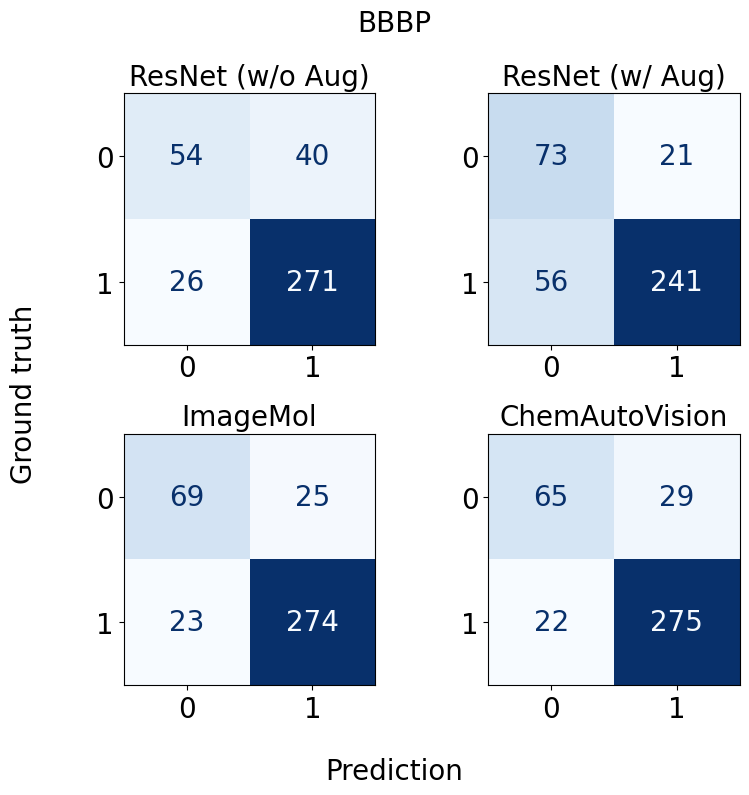

In [45]:
cm_resnet_nodaug_bbbp, _ = confusion_matrix_fixed_threshold(results_resnet_nodaug_bbbp.y_test, results_resnet_nodaug_bbbp.y_preds)
cm_resnet_daug_bbbp, _ = confusion_matrix_fixed_threshold(results_resnet_daug_bbbp.y_test, results_resnet_daug_bbbp.y_preds)
cm_imagemol_daug_bbbp, _ = confusion_matrix_fixed_threshold(results_imagemol_bbbp.y_test, results_imagemol_bbbp.y_preds)
cm_ak_bbbp, _ = confusion_matrix_fixed_threshold(results_ak_bbbp.y_test, results_ak_bbbp.y_preds)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

plot_confusion_matrix(cm_resnet_nodaug_bbbp, axes[0,0], "ResNet (w/o Aug)")
plot_confusion_matrix(cm_resnet_daug_bbbp, axes[0,1], "ResNet (w/ Aug)")
plot_confusion_matrix(cm_imagemol_daug_bbbp, axes[1,0], "ImageMol")
plot_confusion_matrix(cm_ak_bbbp, axes[1,1], "ChemAutoVision")

fig.suptitle("BBBP", fontsize=supxlabel_fontsize)
fig.supxlabel("Prediction", fontsize=supxlabel_fontsize)
fig.supylabel("Ground truth", fontsize=supylabel_fontsize)

plt.tight_layout()
plt.savefig("confusion_matrix_bbbp.png", dpi=150, bbox_inches="tight")
plt.show()

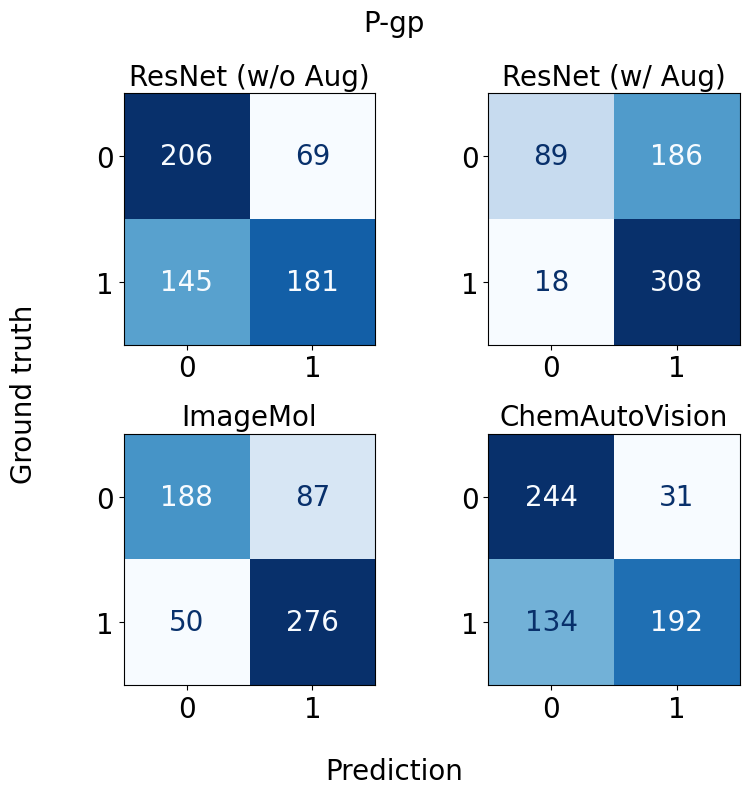

In [46]:
cm_resnet_nodaug_pgp, _ = confusion_matrix_fixed_threshold(results_resnet_nodaug_pgp.y_test, results_resnet_nodaug_pgp.y_preds)
cm_resnet_daug_pgp, _ = confusion_matrix_fixed_threshold(results_resnet_daug_pgp.y_test, results_resnet_daug_pgp.y_preds)
cm_imagemol_daug_pgp, _ = confusion_matrix_fixed_threshold(results_imagemol_pgp.y_test, results_imagemol_pgp.y_preds)
cm_ak_pgp, _ = confusion_matrix_fixed_threshold(results_ak_pgp.y_test, results_ak_pgp.y_preds)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

plot_confusion_matrix(cm_resnet_nodaug_pgp, axes[0,0], "ResNet (w/o Aug)")
plot_confusion_matrix(cm_resnet_daug_pgp, axes[0,1], "ResNet (w/ Aug)")
plot_confusion_matrix(cm_imagemol_daug_pgp, axes[1,0], "ImageMol")
plot_confusion_matrix(cm_ak_pgp, axes[1,1], "ChemAutoVision")

fig.suptitle("P-gp", fontsize=supxlabel_fontsize)
fig.supxlabel("Prediction", fontsize=supxlabel_fontsize)
fig.supylabel("Ground truth", fontsize=supylabel_fontsize)

plt.tight_layout()
plt.savefig("confusion_matrix_pgp.png", dpi=150, bbox_inches="tight")
plt.show()

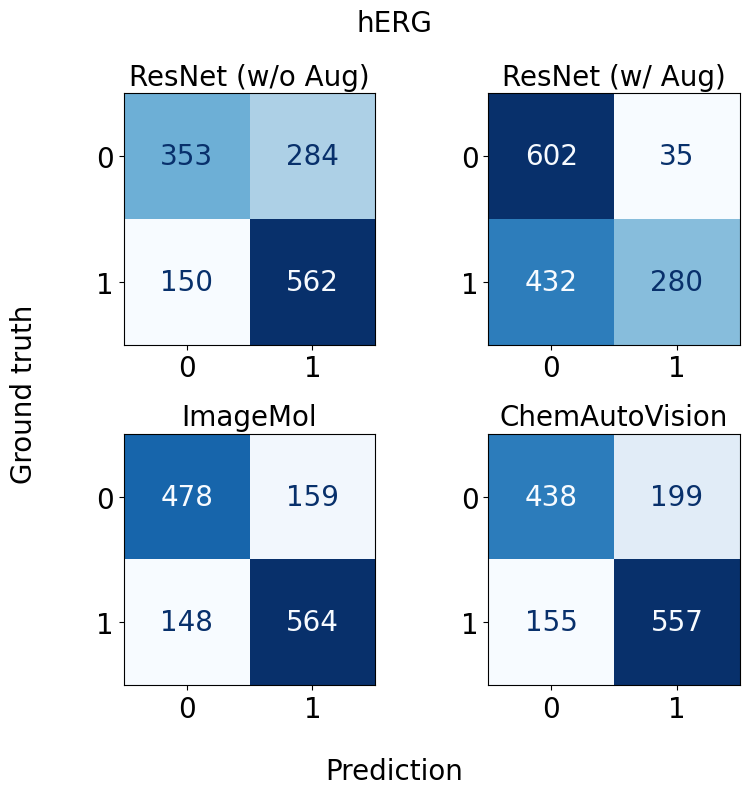

In [47]:
cm_resnet_nodaug_herg, _ = confusion_matrix_fixed_threshold(
    results_resnet_nodaug_herg.y_test,
    results_resnet_nodaug_herg.y_preds
)

cm_resnet_daug_herg, _ = confusion_matrix_fixed_threshold(
    results_resnet_daug_herg.y_test,
    results_resnet_daug_herg.y_preds
)

cm_imagemol_daug_herg, _ = confusion_matrix_fixed_threshold(
    results_imagemol_herg.y_test,
    results_imagemol_herg.y_preds
)

cm_ak_herg, _ = confusion_matrix_fixed_threshold(
    results_ak_herg.y_test,
    results_ak_herg.y_preds
)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

plot_confusion_matrix(cm_resnet_nodaug_herg, axes[0,0], "ResNet (w/o Aug)")
plot_confusion_matrix(cm_resnet_daug_herg, axes[0,1], "ResNet (w/ Aug)")
plot_confusion_matrix(cm_imagemol_daug_herg, axes[1,0], "ImageMol")
plot_confusion_matrix(cm_ak_herg, axes[1,1], "ChemAutoVision")

fig.suptitle("hERG", fontsize=supxlabel_fontsize)
fig.supxlabel("Prediction", fontsize=supxlabel_fontsize)
fig.supylabel("Ground truth", fontsize=supylabel_fontsize)

plt.tight_layout()
plt.savefig("confusion_matrix_herg.png", dpi=150, bbox_inches="tight")
plt.show()


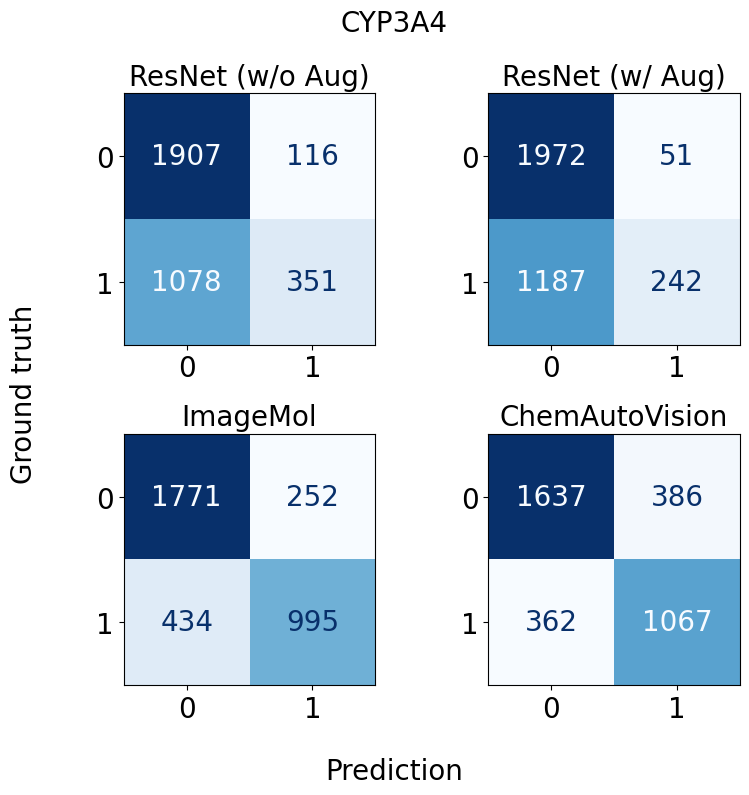

In [48]:
# --- 混合行列作成 ---
cm_resnet_nodaug_cyp, _ = confusion_matrix_fixed_threshold(
    results_resnet_nodaug_cyp.y_test,
    results_resnet_nodaug_cyp.y_preds
)

cm_resnet_daug_cyp, _ = confusion_matrix_fixed_threshold(
    results_resnet_daug_cyp.y_test,
    results_resnet_daug_cyp.y_preds
)

cm_imagemol_daug_cyp, _ = confusion_matrix_fixed_threshold(
    results_imagemol_cyp.y_test,
    results_imagemol_cyp.y_preds
)

cm_ak_cyp, _ = confusion_matrix_fixed_threshold(
    results_ak_cyp.y_test,
    results_ak_cyp.y_preds
)

# --- 描画 ---
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

plot_confusion_matrix(cm_resnet_nodaug_cyp, axes[0,0], "ResNet (w/o Aug)")
plot_confusion_matrix(cm_resnet_daug_cyp, axes[0,1], "ResNet (w/ Aug)")
plot_confusion_matrix(cm_imagemol_daug_cyp, axes[1,0], "ImageMol")
plot_confusion_matrix(cm_ak_cyp, axes[1,1], "ChemAutoVision")

fig.suptitle("CYP3A4", fontsize=supxlabel_fontsize)
fig.supxlabel("Prediction", fontsize=supxlabel_fontsize)
fig.supylabel("Ground truth", fontsize=supylabel_fontsize)

plt.tight_layout()
plt.savefig("confusion_matrix_cyp3a4.png", dpi=150, bbox_inches="tight")
plt.show()

# Histgram

In [49]:
from rdkit import Chem
from rdkit.Chem import BRICS, Descriptors, Draw
from collections import Counter

In [50]:
def decompose_with_brics(smiles):
    """
    BRICSを使ってSMILESを分解し、フラグメントのリストを返す
    
    Args:
        smiles (str): SMILES文字列
    
    Returns:
        list: BRICSで分解されたフラグメントのSMILESリスト、エラーの場合は空リスト
    """
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            raise Error("invalid SMILES is input")
        
        # BRICSで分解
        fragments = BRICS.BRICSDecompose(mol)
        
        if not fragments:
            # BRICS分解できない場合は元の分子を返す
            return [smiles]
        
        # 有効なフラグメントのみをフィルタリング
        valid_fragments = []
        for frag_smiles in fragments:
            try:
                # BRICSの結果には[*]のようなダミー原子が含まれるが、
                # SMILESとしては有効なので、そのまま保持
                # 分子オブジェクトに変換できるかチェック
                clean_smiles = frag_smiles.replace('[*]', '[H]')
                frag_mol = Chem.MolFromSmiles(clean_smiles)
                
                if frag_mol is not None:
                    valid_fragments.append(frag_smiles)
            except:
                continue
        
        return valid_fragments if valid_fragments else [smiles]
        
    except Exception as e:
        raise Error(f"Error processing {smiles}: {e}")

In [51]:
def analyze_all_fragments_diversity(df, smiles_column='smiles', figsize=(12, 8), 
                                   visualize_structures=True, show_diversity_analysis=True, n_top=20):
    """
    DataFrameからすべてのBRICSフラグメントを抽出して多様性分析
    
    Args:
        df (pd.DataFrame): SMILESを含むDataFrame
        smiles_column (str): SMILES列の名前
        figsize (tuple): 図のサイズ
        visualize_structures (bool): fragment構造を可視化するかどうか
        show_diversity_analysis (bool): 多様性分析を表示するかどうか
    
    Returns:
        tuple: (fragment_df, scaffold_counts)
    """
    print("全BRICSフラグメントの抽出を開始します...")
    
    # 各分子からすべてのフラグメントを抽出
    all_fragments = []
    molecule_ids = []
    
    for idx, smiles in enumerate(df[smiles_column]):
        fragments = decompose_with_brics(smiles)
        for fragment in fragments:
            all_fragments.append(fragment)
            molecule_ids.append(idx)
    
    # フラグメントのDataFrameを作成
    fragment_df = pd.DataFrame({
        'molecule_id': molecule_ids,
        'fragment': all_fragments
    })
    
    # 元のDataFrameの情報をマージ
    fragment_df = fragment_df.merge(df.reset_index(drop=True).reset_index().rename(columns={'index': 'molecule_id'}), 
                                   on='molecule_id', how='left')
    
    # Noneの値を除去
    fragment_df_clean = fragment_df.dropna(subset=['fragment'])
    
    print(f"総分子数: {len(df)}")
    print(f"総フラグメント数: {len(fragment_df_clean)}")
    print(f"分子あたり平均フラグメント数: {len(fragment_df_clean)/len(df):.2f}")
    
    # フラグメントの頻度を計算
    fragment_counts = Counter(fragment_df_clean['fragment'])
    
    print(f"ユニークなフラグメント数: {len(fragment_counts)}")
    
    # ヒストグラム用のデータを準備
    # 全fragmentの頻度分布を表示
    frequency_values = list(fragment_counts.values())
    
    # 図を作成
    plt.figure(figsize=figsize)
    
    # ヒストグラムを描画
    n, bins, patches = plt.hist(frequency_values, bins='auto', alpha=0.7, color='lightgreen', edgecolor='darkgreen')
    
    plt.xlabel('Fragment Frequency')
    plt.ylabel('Number of Fragments')
    plt.title(f'Distribution of BRICS Fragment Frequencies (All Fragments)\n(Total: {len(fragment_counts)} unique fragments)')
    plt.grid(axis='y', alpha=0.3)
    
    # 統計情報をプロット上に表示
    mean_freq = np.mean(frequency_values)
    median_freq = np.median(frequency_values)
    plt.axvline(mean_freq, color='red', linestyle='--', alpha=0.8, label=f'Mean: {mean_freq:.2f}')
    plt.axvline(median_freq, color='orange', linestyle='--', alpha=0.8, label=f'Median: {median_freq:.2f}')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 追加でTop fragmentのバープロットも表示
    top_n = min(n_top, len(fragment_counts))
    top_fragments = fragment_counts.most_common(top_n)
    
    if len(fragment_counts) > 1:
        fragments, counts = zip(*top_fragments)
        
        plt.figure(figsize=(figsize[0], figsize[1]*0.6))
        bars = plt.bar(range(len(fragments)), counts, alpha=0.7, color='lightcoral', edgecolor='darkred')
        
        plt.xticks(range(len(fragments)), 
                   [f"{i+1}" for i in range(len(fragments))], 
                   rotation=0)
        
        plt.xlabel('Fragment Rank')
        plt.ylabel('Frequency')
        plt.title(f'Top {top_n} Most Frequent BRICS Fragments (All Fragments)')
        plt.grid(axis='y', alpha=0.3)
        
        # バーの上に頻度を表示
        for i, bar in enumerate(bars):
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                    f'{int(height)}',
                    ha='center', va='bottom', fontsize=8)
        
        plt.tight_layout()
        plt.show()
    
    # 統計情報を表示
    print("\n=== Fragment分布統計 ===")
    print(f"ユニークなフラグメント数: {len(fragment_counts)}")
    print(f"頻度の分布:")
    print(f"  平均: {np.mean(list(fragment_counts.values())):.2f}")
    print(f"  中央値: {np.median(list(fragment_counts.values())):.2f}")
    print(f"  標準偏差: {np.std(list(fragment_counts.values())):.2f}")
    print(f"  最大頻度: {max(fragment_counts.values())}")
    print(f"  最小頻度: {min(fragment_counts.values())}")
    
    # 頻度1のフラグメント数
    unique_fragments = sum(1 for count in fragment_counts.values() if count == 1)
    print(f"  頻度1のフラグメント数: {unique_fragments} ({unique_fragments/len(fragment_counts)*100:.1f}%)")
    
    top_fragments = fragment_counts.most_common(min(20, len(fragment_counts)))
    
    # Top fragmentの詳細を表示
    print(f"\n=== Top {min(10, len(top_fragments))} Fragments ===")
    for i, (fragment, count) in enumerate(top_fragments[:10]):
        print(f"{i+1:2d}. {fragment} (頻度: {count})")
    
    # 構造の可視化
    if visualize_structures:
        print(f"\n=== Top {min(n_top, len(top_fragments))} Fragment Structures ===")
        visualize_scaffold_structures(fragment_counts, top_n=min(n_top, len(fragment_counts)))
    
    # 多様性分析
    if show_diversity_analysis:
        print(f"\n=== Fragment Diversity Analysis ===")
        diversity_metrics = plot_diversity_visualizations(fragment_counts, len(fragment_df_clean))
        
        print(f"\n=== Fragment Diversity Metrics ===")
        print(f"Fragment Diversity Ratio: {diversity_metrics['diversity_ratio']:.3f}")
        print(f"Shannon Entropy: {diversity_metrics['shannon_entropy']:.3f}")
        print(f"Simpson Diversity Index: {diversity_metrics['simpson_index']:.3f}")
        print(f"Gini Coefficient: {diversity_metrics['gini_coefficient']:.3f}")
        print(f"Singleton Ratio: {diversity_metrics['singleton_ratio']:.3f}")
        print(f"Top 10% Concentration: {diversity_metrics['top_10_percent_concentration']:.3f}")
        
        # 多様性の解釈
        print(f"\n=== Fragment Diversity Interpretation ===")
        if diversity_metrics['diversity_ratio'] > 0.7:
            print("✓ Very high fragment diversity (>70% unique fragments)")
        elif diversity_metrics['diversity_ratio'] > 0.5:
            print("✓ High fragment diversity (>50% unique fragments)")
        else:
            print("• Moderate fragment diversity")
            
        if diversity_metrics['singleton_ratio'] > 0.8:
            print("✓ Most fragments are unique (low redundancy)")
        
        if diversity_metrics['gini_coefficient'] < 0.5:
            print("✓ Even distribution of fragment frequencies")
    
    return fragment_df_clean, fragment_counts

In [52]:
def count_brics_fragments(df, smiles_column="smiles", drop_none=True):
    """
    BRICSフラグメントの「総数」と「ユニーク数」だけを高速に集計する

    Returns:
        dict: {
            "n_molecules": int,
            "n_fragments_total": int,   # None除外後
            "n_fragments_unique": int,  # None除外後
            "avg_fragments_per_mol": float
        }
    """
    n_molecules = len(df)

    unique_set = set()
    total = 0

    for smiles in df[smiles_column]:
        fragments = decompose_with_brics(smiles)
        for frag in fragments:
            if drop_none and frag is None:
                continue
            total += 1
            unique_set.add(frag)

    n_unique = len(unique_set)
    avg = total / n_molecules if n_molecules > 0 else 0.0

    return {
        "n_molecules": n_molecules,
        "n_fragments_total": total,
        "n_fragments_unique": n_unique,
        "avg_fragments_per_mol": avg
    }

In [53]:
def plot_fragment_histogram(
    all_fragments,
    n_top=50,
    ax=None,
    title=None,
    is_density=False
):
    """
    単一データセットのBRICSフラグメントヒストグラムを表示

    Args:
        all_fragments (list): すべてのフラグメント
        n_top (int): 表示するTop fragmentの数
        ax (matplotlib.axes): 描画するAxes（Noneの場合は新しいfigureを作成）
        title (str): グラフのタイトル
        is_density (bool): Trueの場合は確率密度表示、Falseの場合は正規化頻度表示

    Returns:
        Counter: フラグメントの頻度カウンタ
    """

    # フラグメントの頻度を計算
    fragment_counts = Counter(all_fragments)

    # Top fragmentを取得
    top_n = min(n_top, len(fragment_counts))
    top_fragments = fragment_counts.most_common(top_n)

    # axが指定されていない場合は新しいfigureを作成
    if ax is None:
        plt.figure(figsize=(12, 6))
        ax = plt.gca()

    if len(fragment_counts) > 0:
        fragments, counts = zip(*top_fragments)
        counts = np.array(counts, dtype=float)

        # 総フラグメント数
        N = counts.sum()

        # ランクヒストグラムなのでビン幅 Δx = 1
        bin_width = 1.0

        if is_density:
            # 確率密度: p_i = n_i / (N * Δx)
            values = counts / (N * bin_width)
            ylabel = "Probability Density"
        else:
            # 正規化頻度（確率）: q_i = n_i / N
            values = counts / N
            ylabel = "Normalized Frequency"

        # バープロットを表示
        ax.bar(
            range(len(fragments)),
            values,
            alpha=0.7,
            color="C0",
            edgecolor="none"
        )

        # X軸の設定（ラベルを間引く）
        step = max(1, len(fragments) // 10)
        ax.set_xticks(range(0, len(fragments), step))
        ax.set_xticklabels(
            [f"{i+1}" for i in range(0, len(fragments), step)],
        )

        ax.tick_params(axis="y")
        ax.set_xlabel("Fragment Rank")
        ax.set_ylabel(ylabel)

        # タイトルを設定
        plot_title = title if title is not None else f"Top {top_n} Most Frequent BRICS Fragments"
        ax.set_title(plot_title)

        ax.grid(axis="y", alpha=0.3)

    else:
        ax.text(
            0.5, 0.5,
            "No fragments available",
            ha="center", va="center",
            transform=ax.transAxes
        )
        ax.set_title(title if title else "Fragment Analysis")

    return fragment_counts

In [54]:
def calculate_diversity_metrics(fragments):
    from collections import Counter
    
    fragment_counts = Counter(fragments)
    total_fragments = len(fragments)
    unique_fragments = len(fragment_counts)
    
    # Top coverages
    top5_coverage = sum(count for _, count in fragment_counts.most_common(5)) / total_fragments
    top10_coverage = sum(count for _, count in fragment_counts.most_common(10)) / total_fragments
    
    return {
        'total_fragments': total_fragments,
        'unique_fragments': unique_fragments,
        'top5_coverage': top5_coverage,
        'top10_coverage': top10_coverage
    }

In [55]:
def get_top_n_fragments(valid_fragments_list, top_n=5):
    """
    有効なフラグメントのリストから頻度上位top_nのSMILESを返す
    
    Args:
        valid_fragments_list (list): decompose_with_brics()の結果のリスト
                                   例: [['fragment1', 'fragment2'], ['fragment3', 'fragment1'], ...]
        top_n (int): 取得する上位フラグメントの数
    
    Returns:
        list: 頻度上位top_nのSMILES文字列のリスト
              例: ['fragment1', 'fragment3', 'fragment2', ...]
    """
    # 全フラグメントを1つのリストに統合
    all_fragments = []
    for fragments in valid_fragments_list:
        if fragments:  # 空のリストでない場合
            all_fragments.extend(fragments)
    
    # フラグメントの頻度をカウント
    fragment_counts = Counter(all_fragments)
    
    # 頻度上位top_nのフラグメントを取得
    top_fragments = fragment_counts.most_common(top_n)
    
    # SMILES文字列のみを抽出（頻度情報は除く）
    top_smiles = [smiles for smiles, count in top_fragments]
    # 
    return top_smiles

In [56]:
def plot_structures_grid(fragments_dict, save_path=None, figsize_per_cell=(2.5, 2.5), 
                        show_smiles=True):
    """
    フラグメント構造をグリッド形式で可視化
    縦軸: データセット名、横軸: ランク
    
    Args:
        fragments_dict (dict): {dataset_name: [fragment_smiles_list]} の辞書
        save_path (str): 保存先パス（Noneの場合は保存しない）
        figsize_per_cell (tuple): 各セルのサイズ
        show_smiles (bool): SMILES文字列を表示するかどうか
    
    Returns:
        matplotlib.figure.Figure: 作成された図
    """
    
    dataset_names = list(fragments_dict.keys())
    n_datasets = len(dataset_names)
    
    # 最大ランク数を取得
    max_rank = max(len(fragments) for fragments in fragments_dict.values())
    
    # 図のサイズを計算
    fig_width = max_rank * figsize_per_cell[0]
    fig_height = n_datasets * figsize_per_cell[1]
    
    # 図を作成
    fig, axes = plt.subplots(n_datasets, max_rank, figsize=(fig_width, fig_height))
    
    # 軸の次元調整
    if n_datasets == 1 and max_rank == 1:
        axes = [[axes]]
    elif n_datasets == 1:
        axes = [axes]
    elif max_rank == 1:
        axes = [[ax] for ax in axes]
    
    # 各データセットについて処理
    for i, dataset_name in enumerate(dataset_names):
        fragments = fragments_dict[dataset_name]
        
        # データセット名をY軸ラベルに表示
        axes[i][0].set_ylabel(dataset_name, fontweight='bold', 
                             rotation=0, ha='right', va='center')
        
        # 各ランクについて処理
        for j in range(max_rank):
            ax = axes[i][j]
            
            if j < len(fragments):
                fragment_smiles = fragments[j]
                
                # 構造を描画
                img = draw_fragment_structure(fragment_smiles)
                ax.imshow(img)
                
                # SMILES文字列を下部に表示
                if show_smiles:
                    # 長いSMILESは省略
                    display_smiles = fragment_smiles
                    if len(fragment_smiles) > 20:
                        display_smiles = fragment_smiles[:20] + '...'
                    
                    ax.text(0.5, -0.1, display_smiles, transform=ax.transAxes, 
                           ha='center', va='top', fontsize=8, fontfamily='monospace')
            else:
                # データが不足している場合
                ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, 
                       ha='center', va='center', fontsize=12, color='gray')
            
            # 軸を非表示
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
    
    # 列のタイトル（ランク）を上部に表示（重複を避けるため条件追加）
    for j in range(max_rank):
        axes[0][j].text(0.5, 1.05, f'Rank {j+1}', transform=axes[0][j].transAxes,
                       ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.9, left=0.15)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Structure grid saved to: {save_path}")
    
    plt.show()
    plt.close(fig)
    return fig

In [57]:
def draw_fragment_structure(smiles, size=(150, 150)):
    """
    フラグメントの構造を描画してPIL Imageを返す
    
    Args:
        smiles (str): SMILES文字列
        size (tuple): 画像サイズ (width, height)
    
    Returns:
        PIL.Image: 描画された構造画像
    """
    # [*]を[H]に置換して描画用の分子を作成
    clean_smiles = smiles.replace('[*]', '[H]')
    mol = Chem.MolFromSmiles(clean_smiles)
    
    if mol is None:
        # 描画できない場合は空の画像を返す
        img = Image.new('RGB', size, 'white')
        return img
    
    # 分子を画像として描画
    img = Draw.MolToImage(mol, size=size, kekulize=True)
    return img

In [58]:
def plot_diversity_visualizations(scaffold_counts, total_molecules, figsize=(15, 10)):
    """
    多様性を表現する複数の可視化を作成
    
    Args:
        scaffold_counts (Counter): scaffoldの頻度カウンター
        total_molecules (int): 総分子数
        figsize (tuple): 図のサイズ
    """
    frequencies = np.array(list(scaffold_counts.values()))
    
    fig, axes = plt.subplots(2, 3, figsize=figsize)
    
    # 1. Cumulative Distribution (累積分布)
    sorted_freq = np.sort(frequencies)[::-1]  # 降順ソート
    cumulative = np.cumsum(sorted_freq) / total_molecules
    
    axes[0, 0].plot(range(1, len(cumulative) + 1), cumulative, 'b-', linewidth=2)
    axes[0, 0].axhline(y=0.5, color='r', linestyle='--', alpha=0.7, label='50% of molecules')
    axes[0, 0].axhline(y=0.8, color='orange', linestyle='--', alpha=0.7, label='80% of molecules')
    axes[0, 0].set_xlabel('Scaffold Rank')
    axes[0, 0].set_ylabel('Cumulative Proportion')
    axes[0, 0].set_title('Cumulative Scaffold Coverage')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Log-Log Plot (べき乗分布の確認)
    rank = np.arange(1, len(sorted_freq) + 1)
    axes[0, 1].loglog(rank, sorted_freq, 'bo-', markersize=3)
    axes[0, 1].set_xlabel('Scaffold Rank (log)')
    axes[0, 1].set_ylabel('Frequency (log)')
    axes[0, 1].set_title('Rank-Frequency Plot (Log-Log)')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Frequency Distribution (頻度の分布)
    freq_counts = Counter(frequencies)
    x_vals = sorted(freq_counts.keys())
    y_vals = [freq_counts[x] for x in x_vals]
    
    axes[0, 2].bar(x_vals, y_vals, alpha=0.7, color='green')
    axes[0, 2].set_xlabel('Scaffold Frequency')
    axes[0, 2].set_ylabel('Number of Scaffolds')
    axes[0, 2].set_title('Frequency Distribution')
    axes[0, 2].set_yscale('log')
    axes[0, 2].grid(True, alpha=0.3)
    
    # 4. Lorenz Curve (ローレンツ曲線)
    sorted_freq_asc = np.sort(frequencies)
    cumulative_freq = np.cumsum(sorted_freq_asc) / np.sum(frequencies)
    cumulative_scaffolds = np.arange(1, len(sorted_freq_asc) + 1) / len(sorted_freq_asc)
    
    axes[1, 0].plot([0, 1], [0, 1], 'k--', alpha=0.7, label='Perfect equality')
    axes[1, 0].plot(cumulative_scaffolds, cumulative_freq, 'r-', linewidth=2, label='Actual distribution')
    axes[1, 0].set_xlabel('Cumulative Proportion of Scaffolds')
    axes[1, 0].set_ylabel('Cumulative Proportion of Molecules')
    axes[1, 0].set_title('Lorenz Curve')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # 5. Diversity Metrics Radar Chart
    metrics = calculate_diversity_metrics(scaffold_counts, total_molecules)
    
    # 指標を0-1の範囲に正規化
    normalized_metrics = {
        'Diversity\nRatio': metrics['diversity_ratio'],
        'Shannon\nEntropy': min(1.0, metrics['shannon_entropy'] / 10),  # 10で正規化
        'Simpson\nIndex': metrics['simpson_index'],
        'Singleton\nRatio': metrics['singleton_ratio'],
        'Low Conc.\n(1-top10%)': 1 - metrics['top_10_percent_concentration'],
        'Low Gini\n(1-gini)': 1 - metrics['gini_coefficient']
    }
    
    labels = list(normalized_metrics.keys())
    values = list(normalized_metrics.values())
    
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    values += values[:1]  # 円を閉じる
    angles += angles[:1]
    
    # Polar plotに変更
    axes[1, 1].remove()
    ax_radar = fig.add_subplot(2, 3, 5, projection='polar')
    ax_radar.plot(angles, values, 'o-', linewidth=2, color='purple')
    ax_radar.fill(angles, values, alpha=0.25, color='purple')
    ax_radar.set_xticks(angles[:-1])
    ax_radar.set_xticklabels(labels)
    ax_radar.set_ylim(0, 1)
    ax_radar.set_title('Diversity Metrics\n(Higher = More Diverse)', pad=20)
    
    # 6. Scaffold Size Distribution
    unique_freq_counts = [freq for freq in frequencies if freq == 1]
    repeated_freq_counts = [freq for freq in frequencies if freq > 1]
    
    categories = ['Unique\nScaffolds', 'Repeated\nScaffolds']
    counts = [len(unique_freq_counts), len(repeated_freq_counts)]
    colors = ['lightblue', 'lightcoral']
    
    wedges, texts, autotexts = axes[1, 2].pie(counts, labels=categories, colors=colors, 
                                              autopct='%1.1f%%', startangle=90)
    axes[1, 2].set_title('Scaffold Uniqueness')
    
    plt.tight_layout()
    plt.show()
    
    return metrics

In [59]:
def visualize_scaffold_structures(scaffold_counts, top_n=20, mols_per_row=4, mol_size=(300, 300)):
    """
    Top scaffoldの構造を可視化
    
    Args:
        scaffold_counts (Counter): scaffoldの頻度カウンター
        top_n (int): 表示するscaffold数
        mols_per_row (int): 1行あたりの分子数
        mol_size (tuple): 各分子の描画サイズ
    """
    try:
        top_scaffolds = scaffold_counts.most_common(top_n)
        
        # 分子オブジェクトのリストを作成
        mols = []
        legends = []
        
        for i, (scaffold_smiles, count) in enumerate(top_scaffolds):
            # [*]を[H]に置換して描画用の分子を作成
            display_smiles = scaffold_smiles.replace('[*]', '[H]')
            mol = Chem.MolFromSmiles(display_smiles)
            
            if mol is not None:
                mols.append(mol)
                legends.append(f"#{i+1} (n={count})\n{scaffold_smiles}")
            else:
                # 分子が作成できない場合はスキップ
                print(f"Could not create molecule for: {scaffold_smiles}")
        
        if not mols:
            print("No valid molecules to display")
            return
        
        # RDKitの描画機能で構造を表示
        img = Draw.MolsToGridImage(
            mols, 
            molsPerRow=mols_per_row,
            subImgSize=mol_size,
            legends=legends,
            useSVG=False
        )
        
        # 画像を表示
        from IPython.display import display
        display(img)
        
    except Exception as e:
        print(f"Error in structure visualization: {e}")
        print("Falling back to SMILES display...")
        
        # 構造描画に失敗した場合はSMILESを表示
        top_scaffolds = scaffold_counts.most_common(top_n)
        print(f"\n=== Top {len(top_scaffolds)} Scaffolds (SMILES) ===")
        for i, (scaffold, count) in enumerate(top_scaffolds):
            print(f"{i+1:2d}. {scaffold} (頻度: {count})")

In [60]:
def plot_brics_histgram(data_path, n_top, title=""):
    df = pd.read_pickle(data_path)
    result = plot_top_fragments(df, smiles_column='smiles', title=title, n_top=n_top, figsize=(12, 6))
    return result

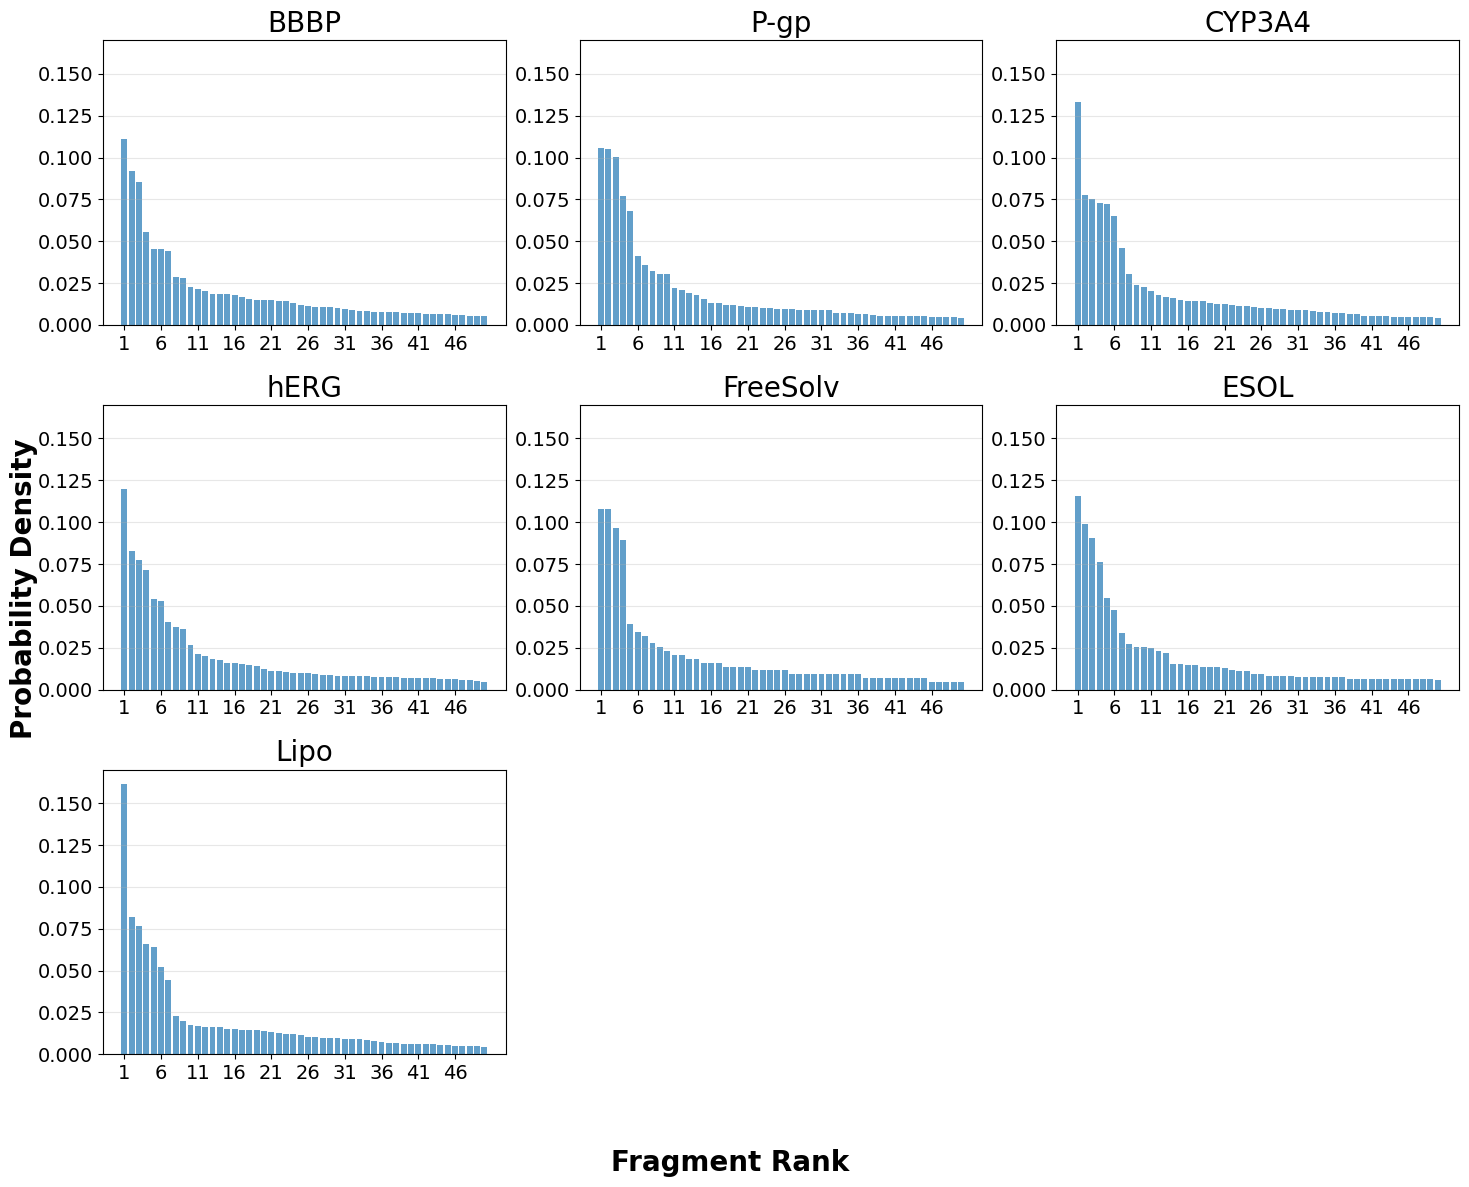

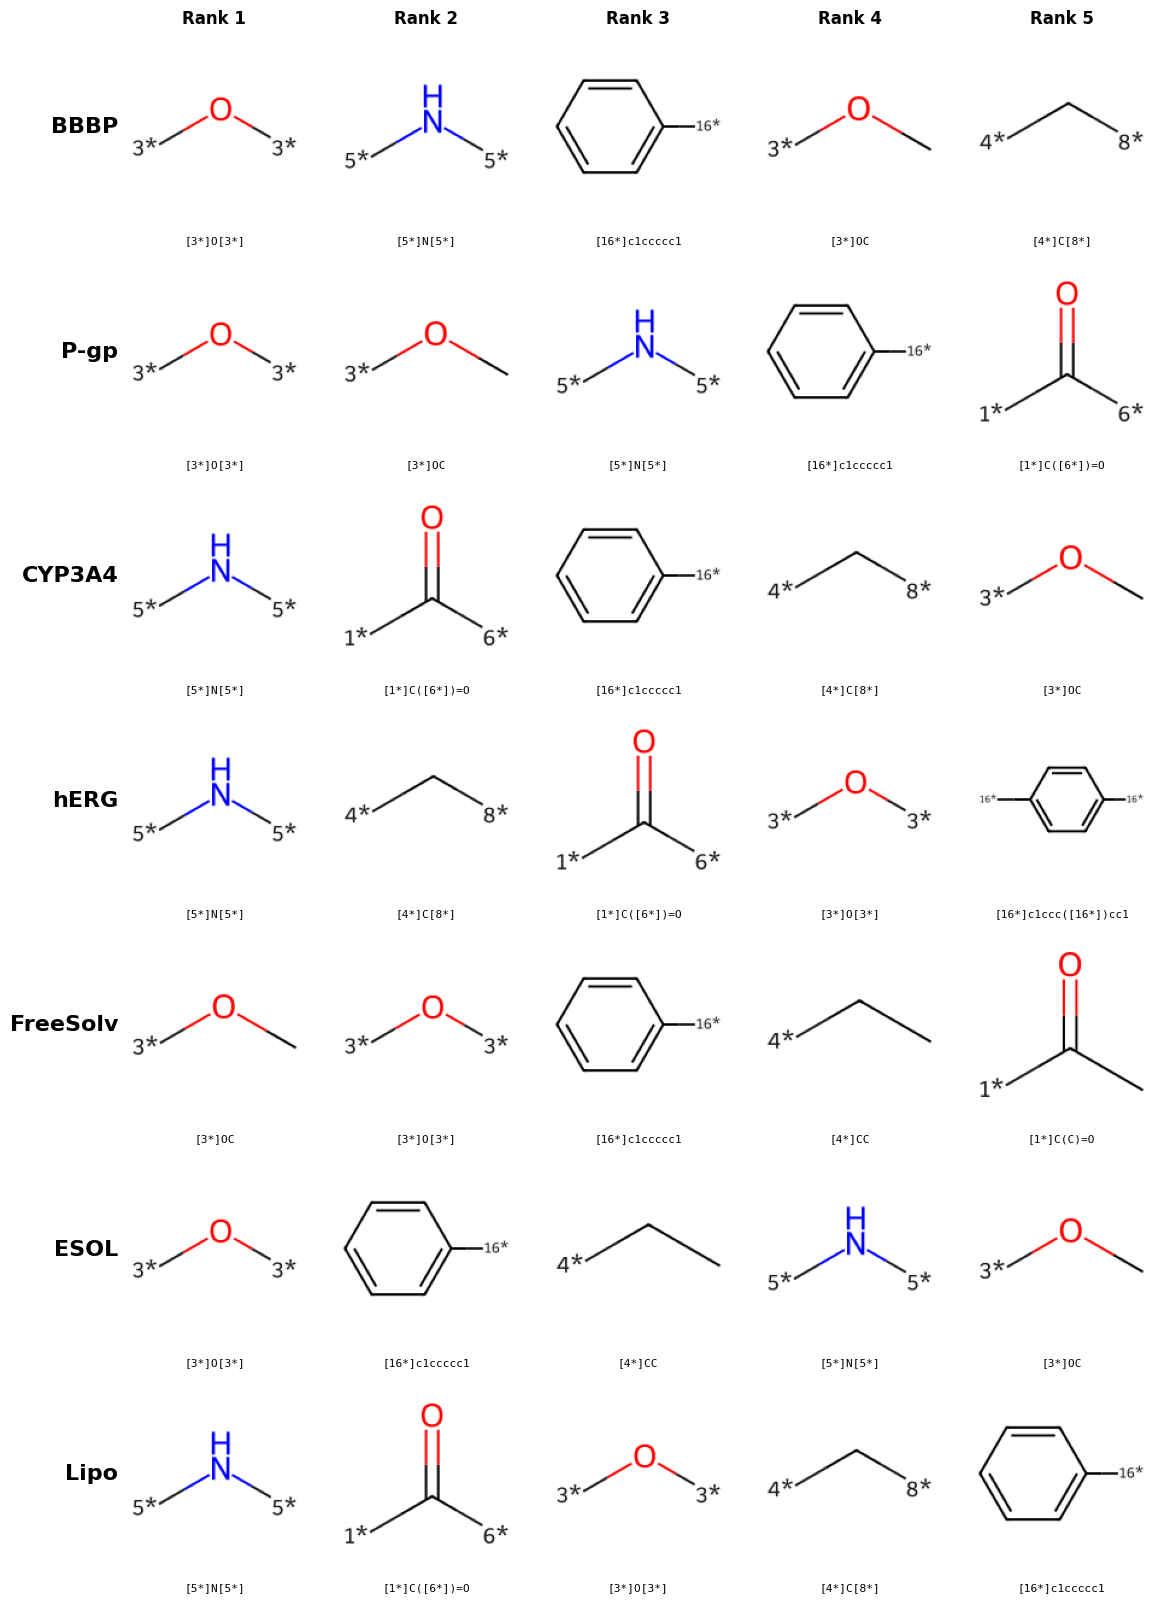

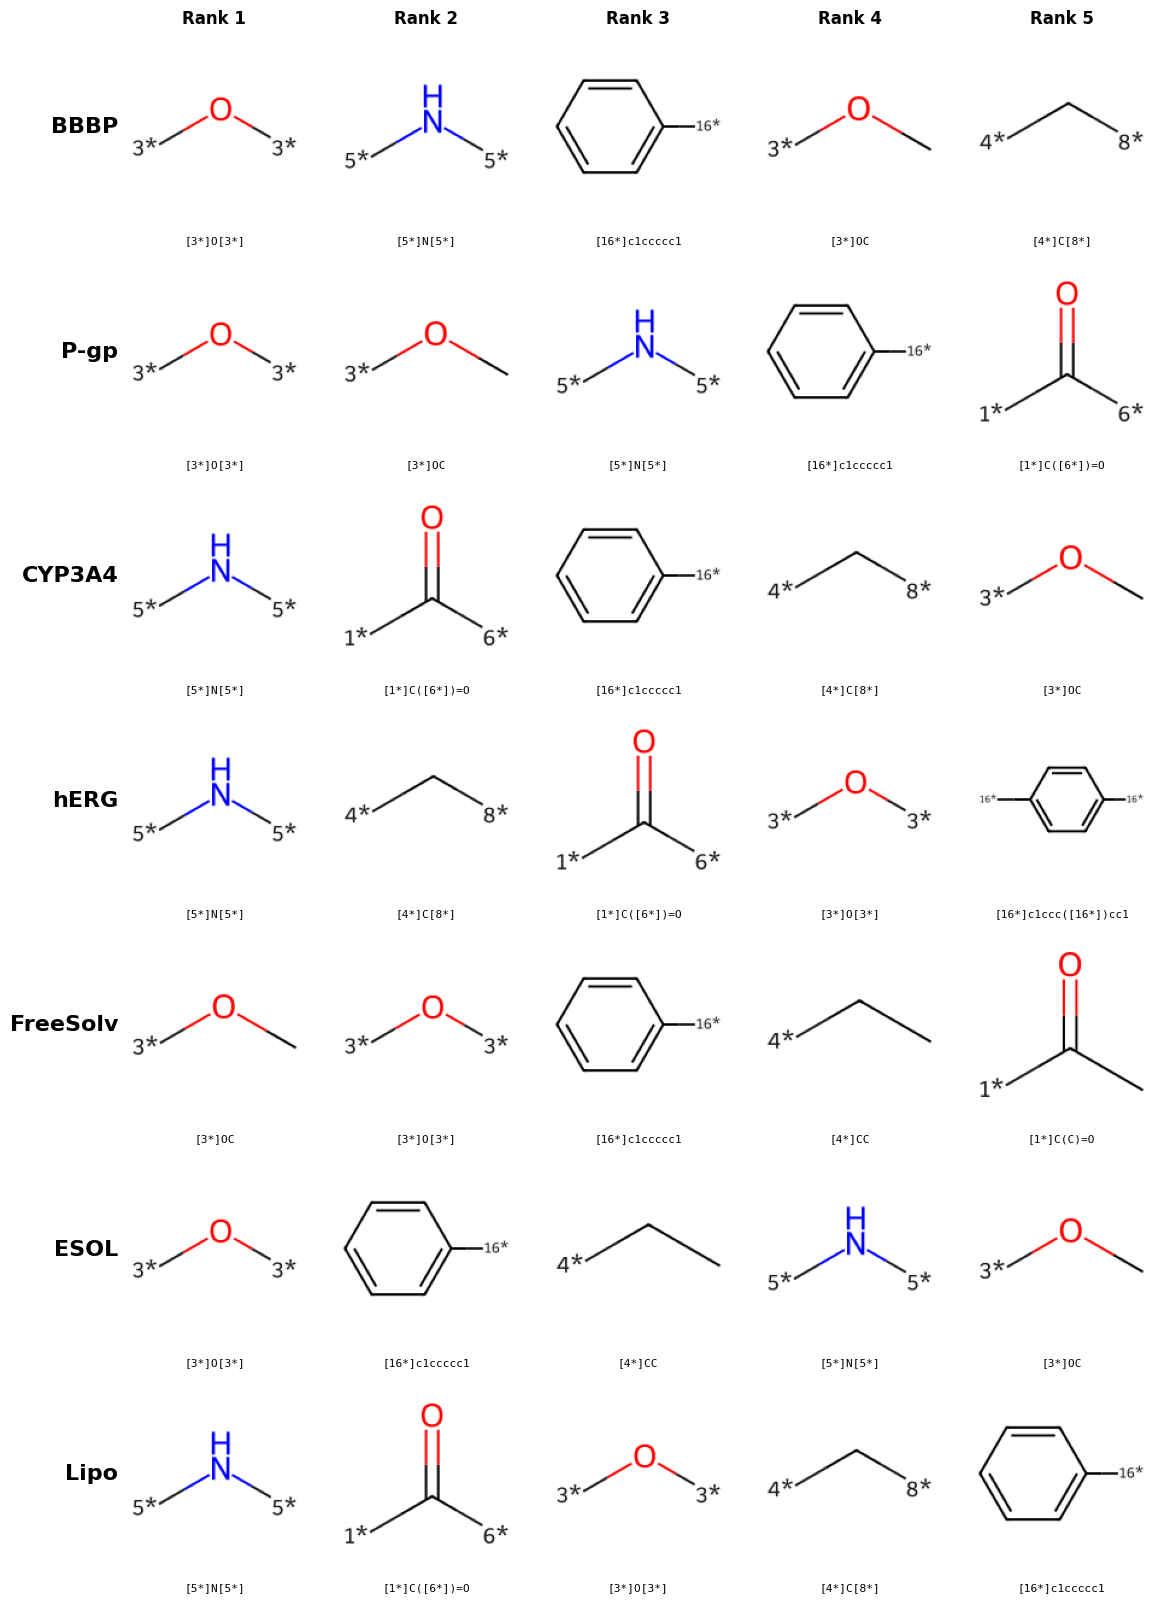

In [61]:
targets = ["BBBP", "P-gp", "CYP3A4", "hERG", "FreeSolv", "ESOL", "Lipo"]
data_path_template = "../../data/{target}_img.pkl"

# 表示名マッピング（ESOL -> ESOL）
display_name = {"ESOL": "ESOL"}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes_flat = axes.flatten()

fragments_dict = {}

for i, target in enumerate(targets):
    if i >= 9:
        break

    with open(data_path_template.format(target=target), "rb") as f:
        df = pd.read_pickle(f)

    title = display_name.get(target, target)

    all_fragments = []
    for smiles in df["smiles"]:
        fragments = decompose_with_brics(smiles)
        for fragment in fragments:
            if fragment is not None:
                all_fragments.append(fragment)

    fragment_counts = plot_fragment_histogram(
        all_fragments,
        ax=axes_flat[i],
        title=title,
        n_top=50,
        is_density=True
    )

    top5_fragments = get_top_n_fragments([all_fragments], top_n=5)
    fragments_dict[title] = top5_fragments

# 余った軸を非表示
for k in range(len(targets), 9):
    axes_flat[k].axis("off")

for ax in axes_flat:
    ax.set_ylabel("")  # 全部消す
    ax.set_ylim(0, 0.17)

for ax in axes_flat:
    ax.set_xlabel("")
fig.supxlabel("Fragment Rank", fontsize=supxlabel_fontsize, fontweight='bold')
fig.supylabel("Probability Density", fontsize=supylabel_fontsize, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("brics_fragment_frequencies.png", dpi=150, bbox_inches="tight")
plt.show()

plot_structures_grid(fragments_dict)


In [62]:
import pandas as pd

# === データセット設定 ===
targets = ["BBBP", "P-gp", "CYP3A4", "hERG", "FreeSolv", "ESOL", "Lipo"]
data_path_template = "../../data/{target}_img.pkl"

# 表示名マッピング（ESOL -> ESOL）
display_name = {"ESOL": "ESOL"}

summary_rows = []

for target in targets:
    # データ読み込み
    with open(data_path_template.format(target=target), "rb") as f:
        df = pd.read_pickle(f)

    title = display_name.get(target, target)

    # ★ 軽量カウント関数を使用
    stats = count_brics_fragments(df, smiles_column="smiles", drop_none=True)

    summary_rows.append({
        "dataset": title,
        "n_molecules": stats["n_molecules"],
        "n_fragments_total": stats["n_fragments_total"],
        "n_fragments_unique": stats["n_fragments_unique"],
        "avg_fragments_per_mol": round(stats["avg_fragments_per_mol"], 3),
        "unique_ratio_percent": round(
            stats["n_fragments_unique"] / max(stats["n_fragments_total"], 1) * 100, 2
        )
    })

# === 結果をDataFrameに ===
summary_df = pd.DataFrame(summary_rows).sort_values(
    "unique_ratio_percent", ascending=False
).reset_index(drop=True)

print("\n=== BRICS Fragment Count Summary (Fast) ===")
print(summary_df.to_string(index=False))



=== BRICS Fragment Count Summary (Fast) ===
 dataset  n_molecules  n_fragments_total  n_fragments_unique  avg_fragments_per_mol  unique_ratio_percent
FreeSolv          642                995                 585                  1.550                 58.79
    ESOL         1111               2281                1022                  2.053                 44.80
    BBBP         1955               7436                2009                  3.804                 27.02
    P-gp         3003              13694                3099                  4.560                 22.63
    Lipo         4200              22436                2645                  5.342                 11.79
  CYP3A4        17259              87170                8379                  5.051                  9.61
    hERG         6744              41130                3382                  6.099                  8.22


In [63]:
def calculate_coverage_curve(fragments, max_rank=20):
    """
    フラグメント頻度からTop N Coverageの累積曲線を計算
    
    Args:
        fragments (list): 全フラグメントのリスト
        max_rank (int): 計算する最大ランク数
    
    Returns:
        tuple: (ranks, coverages) - ランクとカバレッジのリスト
    """
    fragment_counts = Counter(fragments)
    total_fragments = len(fragments)
    
    # 頻度順にソート
    sorted_counts = [count for _, count in fragment_counts.most_common(max_rank)]
    
    # 累積カバレッジを計算
    cumulative_counts = np.cumsum(sorted_counts)
    coverages = cumulative_counts / total_fragments
    
    ranks = list(range(1, len(coverages) + 1))
    
    return ranks, coverages

def plot_single_coverage_curve(fragments, ax, title, max_rank=100):
    # カバレッジ曲線を計算
    ranks, coverages = calculate_coverage_curve(fragments, max_rank)
    
    # 曲線を描画
    ax.plot(ranks, coverages, 
           marker='o', linewidth=2, markersize=4,
           color='darkred', markerfacecolor='lightcoral')
    
    # 軸とタイトルの設定（ヒストグラムと同じサイズに統一）
    ax.set_title(title)  # 18に変更
    ax.set_xlabel('Fragment Rank')          # 14に変更
    ax.set_ylabel('Coverage')               # 14に変更
    
    # メモリのフォントサイズを統一
    ax.tick_params(axis='both', which='major')  # 14に変更
    
    # 以下は同じ
    ax.grid(True, alpha=0.3)
    ax.set_xlim(1, max_rank)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0%}'))
    
    return ranks, coverages

def plot_coverage_curves(datasets_fragments_dict, max_rank=20, save_path=None):
    """
    複数データセットのTop N Coverage曲線を描画
    
    Args:
        datasets_fragments_dict (dict): {dataset_name: fragments_list} の辞書
        max_rank (int): 表示する最大ランク数
        save_path (str): 保存先パス（Noneの場合は保存しない）
    
    Returns:
        matplotlib.figure.Figure: 作成された図
    """
    
    plt.figure(figsize=(10, 6))
    
    # カラーマップを設定
    colors = plt.cm.tab10(np.linspace(0, 1, len(datasets_fragments_dict)))
    
    for i, (dataset_name, fragments) in enumerate(datasets_fragments_dict.items()):
        ranks, coverages = calculate_coverage_curve(fragments, max_rank)
        
        plt.plot(ranks, coverages, 
                marker='o', linewidth=2, markersize=6,
                label=dataset_name, color=colors[i])
    
    plt.xlabel('Fragment Rank')
    plt.ylabel('Coverage', fontweight='bold')
    ax.tick_params(axis='both', which='major') 
    # plt.title('Cumulative Fragment Coverage by Dataset', fontsize=14, fontweight='bold')
    
    # グリッドとレイアウト
    plt.grid(True, alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # 軸の設定
    plt.xlim(1, max_rank)
    plt.ylim(0, 1)
    
    # Y軸を%表示
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0%}'))
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Coverage curve saved to: {save_path}")
    
    plt.show()
    
    return plt.gcf()

In [64]:
diversity_results = {}
for i, target in enumerate(targets):
    if i >= 9:
        break
    
    # データを読み込み
    with open(data_path_template.format(target=target), 'rb') as f:
        df = pd.read_pickle(f)

    all_fragments = []
    for idx, smiles in enumerate(df["smiles"]):
        fragments = decompose_with_brics(smiles) 
        for fragment in fragments:
            if fragment is not None:  # Noneを除外
                all_fragments.append(fragment)

    metrics = calculate_diversity_metrics(all_fragments)
    diversity_results[target] = metrics
    
    print(f"{target}:")
    print(f"  Total Compounds: {len(df['smiles'])}")
    print(f"  Total fragments: {metrics['total_fragments']}")
    print(f"  Unique fragments: {metrics['unique_fragments']}")
    print(f"  Top 5 coverage: {metrics['top5_coverage']:.3f}")
    print(f"  Top 10 coverage: {metrics['top10_coverage']:.3f}")
    # print(f"  Simpson Index: {metrics['simpson_diversity']:.3f}")
    print()

BBBP:
  Total Compounds: 1955
  Total fragments: 7436
  Unique fragments: 2009
  Top 5 coverage: 0.208
  Top 10 coverage: 0.299

P-gp:
  Total Compounds: 3003
  Total fragments: 13694
  Unique fragments: 3099
  Top 5 coverage: 0.249
  Top 10 coverage: 0.342

CYP3A4:
  Total Compounds: 17259
  Total fragments: 87170
  Unique fragments: 8379
  Top 5 coverage: 0.252
  Top 10 coverage: 0.362

hERG:
  Total Compounds: 6744
  Total fragments: 41130
  Unique fragments: 3382
  Top 5 coverage: 0.240
  Top 10 coverage: 0.354

FreeSolv:
  Total Compounds: 642
  Total fragments: 995
  Unique fragments: 585
  Top 5 coverage: 0.193
  Top 10 coverage: 0.255

ESOL:
  Total Compounds: 1111
  Total fragments: 2281
  Unique fragments: 1022
  Top 5 coverage: 0.209
  Top 10 coverage: 0.285

Lipo:
  Total Compounds: 4200
  Total fragments: 22436
  Unique fragments: 2645
  Top 5 coverage: 0.271
  Top 10 coverage: 0.365



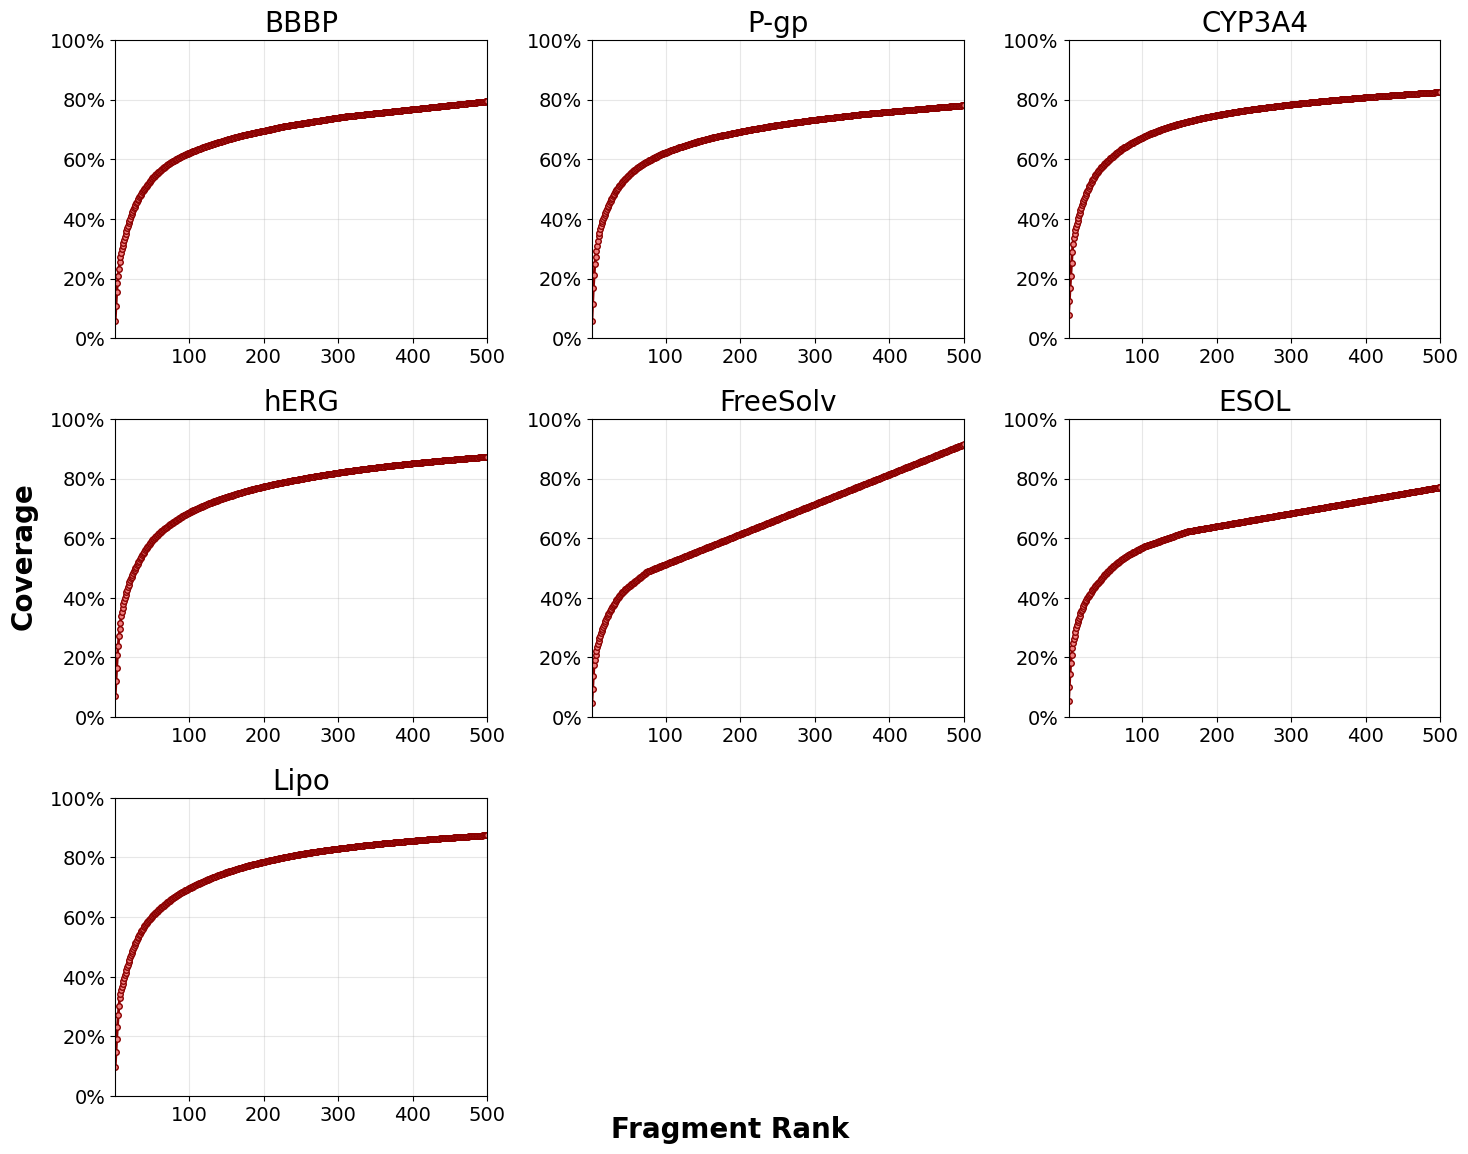

Coverage @ Rank 100 (%)
BBBP      :  62.12%
P-gp      :  62.27%
CYP3A4    :  67.31%
hERG      :  68.60%
FreeSolv  :  51.26%
ESOL      :  56.82%
Lipo      :  69.57%


In [65]:
targets = ["BBBP", "P-gp", "CYP3A4", "hERG", "FreeSolv", "ESOL", "Lipo"]
data_path_template = "../../data/{target}_img.pkl"

# 表示名マッピング（ESOL -> ESOL）
display_name = {"ESOL": "ESOL"}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes_flat = axes.flatten()

coverage_at_100 = {}

for i, target in enumerate(targets):
    if i >= 9:
        break

    # データ読み込み
    with open(data_path_template.format(target=target), "rb") as f:
        df = pd.read_pickle(f)

    # 表示名
    title = display_name.get(target, target)

    all_fragments = []
    for smiles in df["smiles"]:
        fragments = decompose_with_brics(smiles)
        for fragment in fragments:
            if fragment is not None:
                all_fragments.append(fragment)

    # カバレッジ曲線を描画
    ranks, coverages = plot_single_coverage_curve(
        all_fragments,
        ax=axes_flat[i],
        title=title,      # ← 表示だけ ESOL
        max_rank=500
    )

    # Rank 100 のカバレッジを取得（%）
    import numpy as np
    ranks_arr = np.asarray(ranks)

    idx_100 = np.where(ranks_arr == 100)[0]
    cov100 = coverages[idx_100[0]] * 100 if len(idx_100) > 0 else float("nan")

    coverage_at_100[title] = cov100

# 余った軸を非表示
for k in range(len(targets), 9):
    axes_flat[k].axis("off")

# ---- Coverageラベルは左上から2番目（axes_flat[1]）だけ表示 ----
for idx, ax in enumerate(axes_flat):
    ax.set_ylabel("")

# axes_flat[3].set_ylabel("Coverage", labelpad=8)
# plt.suptitle("Fragment Coverage Curves by Dataset", fontsize=16, fontweight="bold")
for idx, ax in enumerate(axes_flat):
    ax.set_xlabel("")
fig.supxlabel("Fragment Rank", fontsize=supxlabel_fontsize, fontweight='bold')
fig.supylabel("Coverage", fontsize=supylabel_fontsize, fontweight='bold')
plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.05)
plt.savefig("brics_coverage_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Rank 100 の結果を出力 ----
print("Coverage @ Rank 100 (%)")
for name, val in coverage_at_100.items():
    print(f"{name:10s}: {val:6.2f}%")


# Dataset split summary for manuscript

分割済みPKLの `group` 列を基準に、random splitとbalanced scaffold splitの件数および分類クラス別件数を集計する。

In [54]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = Path("../../data")
PAPER_TABLE_DIR = Path("../../results/paper_tables")
SCAFFOLD_SPLIT_SEED = 42
GROUP_ORDER = ["train", "val", "test"]
EXPECTED_GROUPS = set(GROUP_ORDER)

DATASET_CONFIG = {
    "BBBP": {"task": "classification", "target": "BBBP"},
    "P-gp": {"task": "classification", "target": "P-gp"},
    "CYP3A4": {"task": "classification", "target": "CYP3A4"},
    "hERG": {"task": "classification", "target": "hERG"},
    "FreeSolv": {"task": "regression", "target": "FreeSolv"},
    "ESOL": {"task": "regression", "target": "ESOL"},
    "Lipo": {"task": "regression", "target": "Lipo"},
}

SPLIT_CONFIG = {
    "Random": "",
    "Balanced scaffold": f"balanced_scaffold_seed{SCAFFOLD_SPLIT_SEED}_",
}

def validate_split_artifact(df, dataset, target, task_type, split_method):
    required_columns = {"group", target}
    missing_columns = required_columns - set(df.columns)
    if missing_columns:
        raise ValueError(
            f"{dataset} ({split_method}) is missing columns: {sorted(missing_columns)}"
        )

    if df["group"].isna().any():
        raise ValueError(f"{dataset} ({split_method}) contains missing group values.")

    actual_groups = set(df["group"].unique())
    if actual_groups != EXPECTED_GROUPS:
        raise ValueError(
            f"{dataset} ({split_method}) has unexpected groups: {sorted(actual_groups)}"
        )

    if df[target].isna().any():
        raise ValueError(f"{dataset} ({split_method}) contains missing target values.")

    if task_type == "classification":
        labels = set(df[target].unique())
        if labels != {0, 1}:
            raise ValueError(
                f"{dataset} ({split_method}) has unexpected labels: {sorted(labels)}"
            )

def summarize_split_artifact(df, dataset, target, task_type, split_method):
    validate_split_artifact(df, dataset, target, task_type, split_method)
    rows = []

    for group in GROUP_ORDER:
        subset = df.loc[df["group"].eq(group)]
        row = {
            "Split method": split_method,
            "Dataset": dataset,
            "Subset": group,
            "N": len(subset),
            "Class 0": pd.NA,
            "Class 1": pd.NA,
            "Majority/minority ratio": pd.NA,
        }

        if task_type == "classification":
            counts = (
                subset[target].value_counts().reindex([0, 1], fill_value=0).astype(int)
            )
            n_class_0 = int(counts.loc[0])
            n_class_1 = int(counts.loc[1])
            if n_class_0 + n_class_1 != len(subset):
                raise AssertionError(
                    f"{dataset} ({split_method}, {group}): class counts do not sum to N."
                )

            minority_count = min(n_class_0, n_class_1)
            row["Class 0"] = n_class_0
            row["Class 1"] = n_class_1
            row["Majority/minority ratio"] = (
                max(n_class_0, n_class_1) / minority_count
                if minority_count > 0
                else np.inf
            )

        rows.append(row)

    if sum(row["N"] for row in rows) != len(df):
        raise AssertionError(f"{dataset} ({split_method}): group counts do not sum to total N.")

    return rows


In [55]:
split_summary_rows = []

for split_method, file_prefix in SPLIT_CONFIG.items():
    for dataset, config in DATASET_CONFIG.items():
        data_path = DATA_DIR / f"{file_prefix}{dataset}_img.pkl"
        if not data_path.exists():
            raise FileNotFoundError(f"Split artifact not found: {data_path}")

        df_split = pd.read_pickle(data_path)
        split_summary_rows.extend(
            summarize_split_artifact(
                df=df_split,
                dataset=dataset,
                target=config["target"],
                task_type=config["task"],
                split_method=split_method,
            )
        )

split_summary_long = pd.DataFrame(split_summary_rows)
split_summary_long["Split method"] = pd.Categorical(
    split_summary_long["Split method"],
    categories=list(SPLIT_CONFIG),
    ordered=True,
)
split_summary_long["Dataset"] = pd.Categorical(
    split_summary_long["Dataset"],
    categories=list(DATASET_CONFIG),
    ordered=True,
)
split_summary_long["Subset"] = pd.Categorical(
    split_summary_long["Subset"],
    categories=GROUP_ORDER,
    ordered=True,
)
split_summary_long = split_summary_long.sort_values(
    ["Split method", "Dataset", "Subset"]
).reset_index(drop=True)

display(split_summary_long)


,Split method,Dataset,Subset,N,Class 0,Class 1,Majority/minority ratio
0,Random,BBBP,train,1251,286,965,3.374126
1,Random,BBBP,val,313,81,232,2.864198
2,Random,BBBP,test,391,94,297,3.159574
3,Random,P-gp,train,1921,893,1028,1.151176
4,Random,P-gp,val,481,237,244,1.029536
5,Random,P-gp,test,601,275,326,1.185455
6,Random,CYP3A4,train,11045,6432,4613,1.39432
7,Random,CYP3A4,val,2762,1575,1187,1.326874
8,Random,CYP3A4,test,3452,2023,1429,1.415675
9,Random,hERG,train,4316,2109,2207,1.046468


In [56]:
sample_count_table = (
    split_summary_long.pivot(
        index=["Split method", "Dataset"],
        columns="Subset",
        values="N",
    )
    .reindex(columns=GROUP_ORDER)
    .rename(columns={"train": "Train", "val": "Validation", "test": "Test"})
    .reset_index()
)

classification_summary = split_summary_long.loc[
    split_summary_long["Class 0"].notna()
].copy()
classification_summary["Class 0 / Class 1"] = (
    classification_summary["Class 0"].astype("Int64").astype(str)
    + " / "
    + classification_summary["Class 1"].astype("Int64").astype(str)
)

class_count_table = (
    classification_summary.pivot(
        index=["Split method", "Dataset"],
        columns="Subset",
        values="Class 0 / Class 1",
    )
    .reindex(columns=GROUP_ORDER)
    .rename(columns={
        "train": "Train (0 / 1)",
        "val": "Validation (0 / 1)",
        "test": "Test (0 / 1)",
    })
    .reset_index()
)

class_ratio_table = (
    classification_summary.pivot(
        index=["Split method", "Dataset"],
        columns="Subset",
        values="Majority/minority ratio",
    )
    .reindex(columns=GROUP_ORDER)
    .rename(columns={
        "train": "Train ratio",
        "val": "Validation ratio",
        "test": "Test ratio",
    })
    .reset_index()
)
numeric_ratio_columns = ["Train ratio", "Validation ratio", "Test ratio"]
class_ratio_table[numeric_ratio_columns] = (
    class_ratio_table[numeric_ratio_columns].apply(pd.to_numeric).round(2)
)

print("Sample counts by split")
display(sample_count_table)
print("Class counts by split (Class 0 / Class 1)")
display(class_count_table)
print("Majority/minority class ratio by split")
display(class_ratio_table)

PAPER_TABLE_DIR.mkdir(parents=True, exist_ok=True)
split_summary_long.to_csv(PAPER_TABLE_DIR / "split_summary_long.csv", index=False)
sample_count_table.to_csv(PAPER_TABLE_DIR / "split_sample_counts.csv", index=False)
class_count_table.to_csv(PAPER_TABLE_DIR / "split_class_counts.csv", index=False)
class_ratio_table.to_csv(PAPER_TABLE_DIR / "split_class_ratios.csv", index=False)


Sample counts by split


Subset,Split method,Dataset,Train,Validation,Test
0,Random,BBBP,1251,313,391
1,Random,P-gp,1921,481,601
2,Random,CYP3A4,11045,2762,3452
3,Random,hERG,4316,1079,1349
4,Random,FreeSolv,410,103,129
5,Random,ESOL,710,178,223
6,Random,Lipo,2688,672,840
7,Balanced scaffold,BBBP,1251,312,392
8,Balanced scaffold,P-gp,1921,480,602
9,Balanced scaffold,CYP3A4,11045,2761,3453


Class counts by split (Class 0 / Class 1)


Subset,Split method,Dataset,Train (0 / 1),Validation (0 / 1),Test (0 / 1)
0,Random,BBBP,286 / 965,81 / 232,94 / 297
1,Random,P-gp,893 / 1028,237 / 244,275 / 326
2,Random,CYP3A4,6432 / 4613,1575 / 1187,2023 / 1429
3,Random,hERG,2109 / 2207,533 / 546,637 / 712
4,Balanced scaffold,BBBP,312 / 939,69 / 243,80 / 312
5,Balanced scaffold,P-gp,878 / 1043,274 / 206,253 / 349
6,Balanced scaffold,CYP3A4,6545 / 4500,1538 / 1223,1947 / 1506
7,Balanced scaffold,hERG,2069 / 2247,533 / 546,677 / 672


Majority/minority class ratio by split


Subset,Split method,Dataset,Train ratio,Validation ratio,Test ratio
0,Random,BBBP,3.37,2.86,3.16
1,Random,P-gp,1.15,1.03,1.19
2,Random,CYP3A4,1.39,1.33,1.42
3,Random,hERG,1.05,1.02,1.12
4,Balanced scaffold,BBBP,3.01,3.52,3.90
5,Balanced scaffold,P-gp,1.19,1.33,1.38
6,Balanced scaffold,CYP3A4,1.45,1.26,1.29
7,Balanced scaffold,hERG,1.09,1.02,1.01


## Dataset size overview

分類データセットは Active / Inactive の積み上げ棒、回帰データセットは単色の棒として、全データ件数を1枚にまとめる。

,Task,Dataset,Total,Active,Inactive
0,Classification,BBBP,1955,1494,461
1,Classification,P-gp,3003,1598,1405
2,Classification,hERG,6744,3465,3279
3,Classification,CYP3A4,17259,7229,10030
4,Regression,FreeSolv,642,0,0
5,Regression,ESOL,1111,0,0
6,Regression,Lipo,4200,0,0


Saved: ../../results/paper_figures/dataset_size_overview.png
Saved: ../../results/paper_figures/dataset_size_overview.pdf


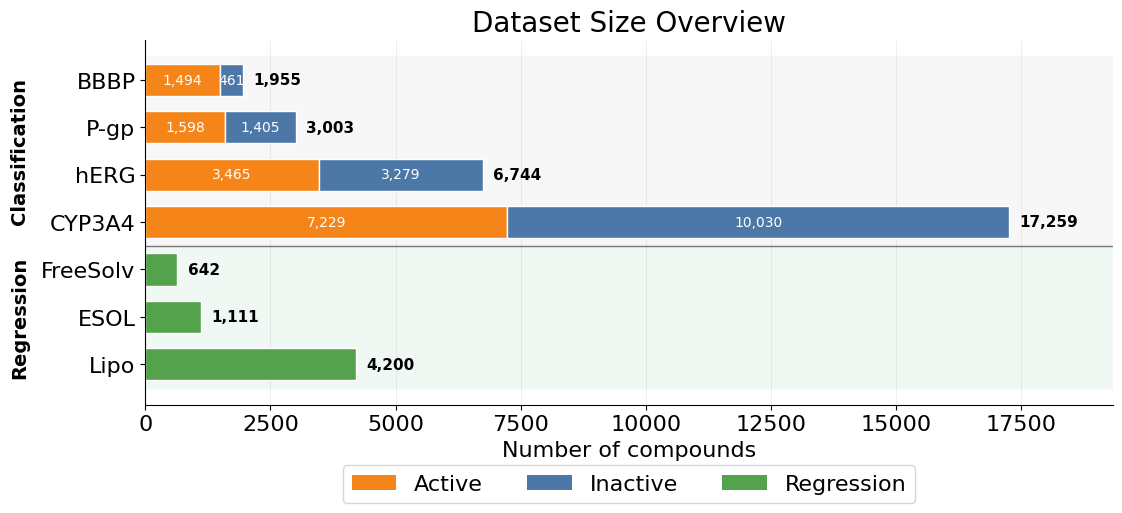

In [60]:
from matplotlib.patches import Patch

DATASET_SIZE_ORDER = [
    "BBBP", "P-gp", "hERG", "CYP3A4",
    "FreeSolv", "ESOL", "Lipo",
]
DATASET_SIZE_COLORS = {
    "Active": "#F58518",
    "Inactive": "#4C78A8",
    "Regression": "#54A24B",
}

# Random split contains every sample exactly once across train/val/test.
random_split_summary = split_summary_long.loc[
    split_summary_long["Split method"].eq("Random")
].copy()
overview_rows = []
for dataset in DATASET_SIZE_ORDER:
    config = DATASET_CONFIG[dataset]
    dataset_rows = random_split_summary.loc[
        random_split_summary["Dataset"].eq(dataset)
    ]
    total = int(pd.to_numeric(dataset_rows["N"]).sum())
    active = 0
    inactive = 0
    if config["task"] == "classification":
        active = int(pd.to_numeric(dataset_rows["Class 1"], errors="coerce").fillna(0).sum())
        inactive = int(pd.to_numeric(dataset_rows["Class 0"], errors="coerce").fillna(0).sum())
        if active + inactive != total:
            raise AssertionError(
                f"{dataset}: Active + Inactive ({active + inactive}) != Total ({total})"
            )
    overview_rows.append({
        "Task": config["task"].title(),
        "Dataset": dataset,
        "Total": total,
        "Active": active,
        "Inactive": inactive,
    })

dataset_size_summary = pd.DataFrame(overview_rows)
display(dataset_size_summary)

figure, axis = plt.subplots(figsize=(12, 7))
y_positions = np.arange(len(dataset_size_summary))
bar_height = 0.68
max_total = int(dataset_size_summary["Total"].max())

# Light task-group backgrounds and a separator keep both tasks in one panel.
axis.axhspan(-0.5, 3.5, color="#F7F7F7", zorder=0)
axis.axhspan(3.5, 6.5, color="#EFF8F2", zorder=0)
axis.axhline(3.5, color="#777777", linewidth=1.0)

for position, row in dataset_size_summary.iterrows():
    if row["Task"] == "Classification":
        axis.barh(
            position, row["Active"], height=bar_height,
            color=DATASET_SIZE_COLORS["Active"], edgecolor="white",
        )
        axis.barh(
            position, row["Inactive"], left=row["Active"],
            height=bar_height, color=DATASET_SIZE_COLORS["Inactive"],
            edgecolor="white",
        )
        axis.text(
            row["Active"] / 2, position, f'{row["Active"]:,}',
            ha="center", va="center", color="white", fontsize=10,
        )
        axis.text(
            row["Active"] + row["Inactive"] / 2, position,
            f'{row["Inactive"]:,}', ha="center", va="center",
            color="white", fontsize=10,
        )
    else:
        axis.barh(
            position, row["Total"], height=bar_height,
            color=DATASET_SIZE_COLORS["Regression"], edgecolor="white",
        )

    axis.text(
        row["Total"] + max_total * 0.012, position, f'{row["Total"]:,}',
        ha="left", va="center", fontweight="bold", fontsize=11,
    )

axis.set_yticks(y_positions, dataset_size_summary["Dataset"])
axis.invert_yaxis()
axis.set_xlim(0, max_total * 1.12)
axis.set_xlabel("Number of compounds")
axis.set_title("Dataset Size Overview")
axis.grid(True, axis="x", alpha=0.25, linewidth=0.6)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)
axis.text(
    -0.13, 1.5, "Classification", transform=axis.get_yaxis_transform(),
    ha="center", va="center", rotation=90, fontweight="bold",
)
axis.text(
    -0.13, 5.0, "Regression", transform=axis.get_yaxis_transform(),
    ha="center", va="center", rotation=90, fontweight="bold",
)
axis.legend(
    handles=[
        Patch(facecolor=DATASET_SIZE_COLORS["Active"], label="Active"),
        Patch(facecolor=DATASET_SIZE_COLORS["Inactive"], label="Inactive"),
        Patch(facecolor=DATASET_SIZE_COLORS["Regression"], label="Regression"),
    ],
    loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=True,
)
figure.tight_layout(rect=(0.05, 0.16, 1, 1))

dataset_figure_dir = Path("../../results/paper_figures")
dataset_figure_dir.mkdir(parents=True, exist_ok=True)
for suffix in ("png", "pdf"):
    output_path = dataset_figure_dir / f"dataset_size_overview.{suffix}"
    figure.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {output_path}")
display(figure)
plt.close(figure)


# Histgram(MW)

In [69]:
import sys, os
sys.path.append(os.path.abspath("..")) 
from utils.utils import calc_mw
import matplotlib.pyplot as plt

In [70]:
fs_data_path = "../../data/FreeSolv_img.pkl"
lipo_data_path = "../../data/Lipo_img.pkl"
esol_data_path = "../../data/ESOL_img.pkl"

In [71]:
df_fs = pd.read_pickle(fs_data_path)
df_lipo = pd.read_pickle(lipo_data_path)
df_esol = pd.read_pickle(esol_data_path)

df_bbbp = pd.read_pickle(bbbp_data_path)
df_herg = pd.read_pickle(herg_data_path)
df_pgp = pd.read_pickle(pgp_data_path)
df_cyp = pd.read_pickle(cyp_data_path)

In [72]:
df_fs["MW"] = df_fs["smiles"].apply(calc_mw)
df_lipo["MW"] = df_lipo["smiles"].apply(calc_mw)
df_esol["MW"] = df_esol["smiles"].apply(calc_mw)

df_bbbp["MW"] = df_bbbp["smiles"].apply(calc_mw)
df_herg["MW"] = df_herg["smiles"].apply(calc_mw)
df_pgp["MW"] = df_pgp["smiles"].apply(calc_mw)
df_cyp["MW"] = df_cyp["smiles"].apply(calc_mw)

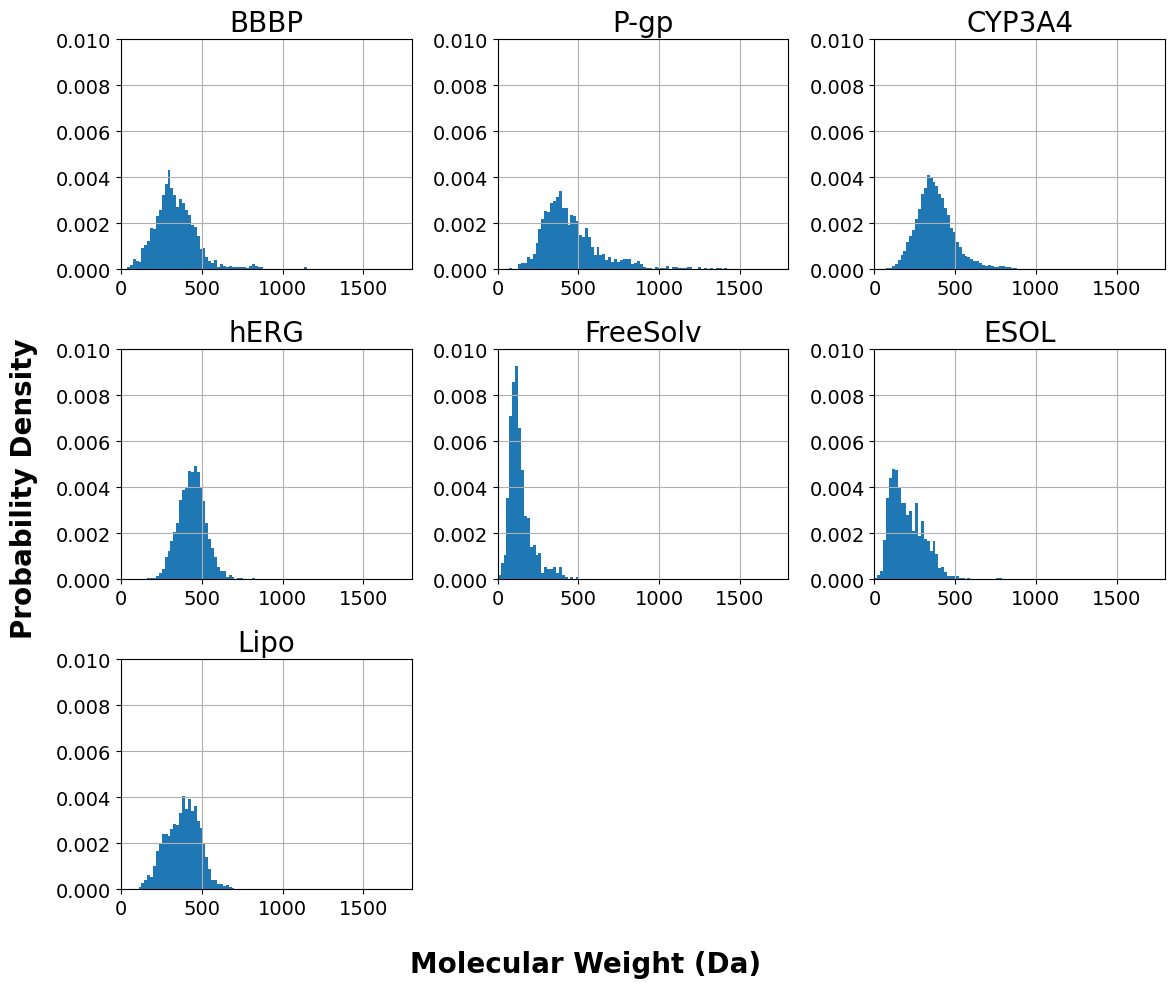

In [73]:
import matplotlib.pyplot as plt

datasets = [
    ("BBBP", df_bbbp),
    ("P-gp", df_pgp),
    ("CYP3A4", df_cyp),
    ("hERG", df_herg),
    ("FreeSolv", df_fs),
    ("ESOL", df_esol),
    ("Lipo", df_lipo),
]

bins = 100
x_range = (0, 1800)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

DENSITY_INDEX = 3   # 1列目2行目
X_LABEL_INDEX = 7   # 2列目3行目（ここは空き枠として使う）

for i, (title, df) in enumerate(datasets):
    ax = axes[i]
    ax.hist(df["MW"], bins=bins, range=x_range, density=True)
    ax.set_title(title)
    ax.set_xlim(*x_range)
    ax.set_ylim(0, 0.01)
    ax.tick_params(axis='both')

    ax.set_xlabel("")
    ax.grid(True)


ax_label = axes[X_LABEL_INDEX]
ax_label.set_xlim(*x_range)
ax_label.set_ylim(0, 0.01)

ax_label.set_xticks([])
ax_label.set_yticks([])
ax_label.grid(False)
for spine in ax_label.spines.values():
    spine.set_visible(False)

for j in range(len(datasets), len(axes)):  # j=7,8
    if j != X_LABEL_INDEX:
        fig.delaxes(axes[j])

fig.supxlabel("Molecular Weight (Da)", fontsize=supxlabel_fontsize, fontweight="bold")
fig.supylabel("Probability Density", fontsize=supylabel_fontsize, fontweight="bold")
plt.savefig("mw_distributions.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [74]:
stats = []
for name, df in datasets:
    mw = df["MW"].dropna().astype(float)

    stats.append({
        "Dataset": name,
        "Number of molecules": len(mw),
        "Mean": mw.mean(),
        "Median": mw.median(),
        "Standard deviation": mw.std(ddof=0),   # ← 普通の標準偏差（分母=N）
    })

mw_stats_df = pd.DataFrame(stats)

# 小数点を揃える
mw_stats_df[["Mean", "Median", "Standard deviation"]] = \
    mw_stats_df[["Mean", "Median", "Standard deviation"]].round(2)

mw_stats_df

,Dataset,Number of molecules,Mean,Median,Standard deviation
0,BBBP,1955,343.07,323.0,147.90
1,P-gp,3003,459.06,414.0,198.47
2,CYP3A4,17259,379.41,366.0,122.72
3,hERG,6744,439.63,439.5,86.49
4,FreeSolv,642,138.70,120.5,72.54
5,ESOL,1111,203.39,182.0,103.00
6,Lipo,4200,382.65,388.0,106.84


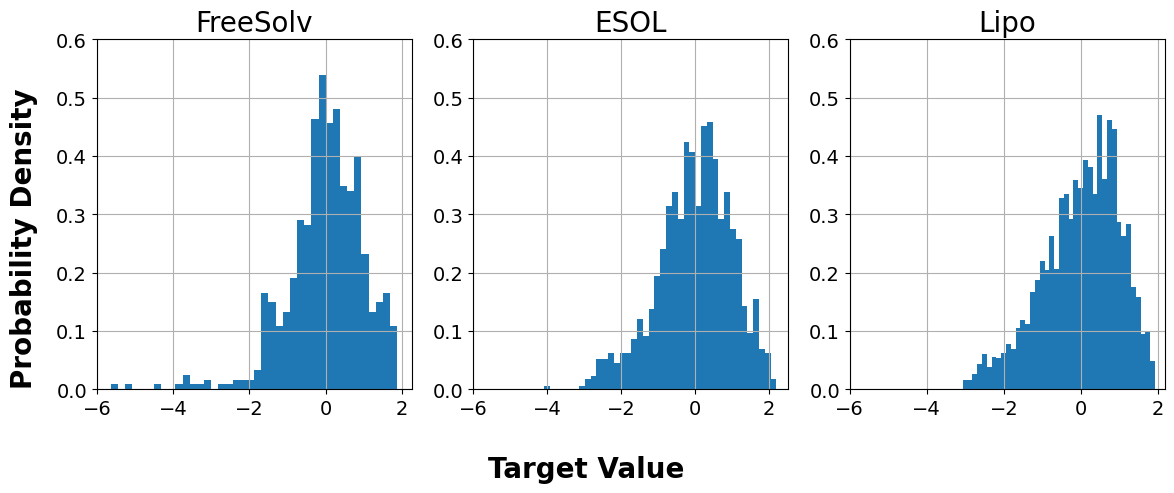

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)

reg_datasets = [
    ("FreeSolv", df_fs, "FreeSolv"),
    ("ESOL", df_esol, "ESOL"),
    ("Lipo", df_lipo, "Lipo"),
]

for i, (ax, (title, df, label_col)) in enumerate(zip(axes, reg_datasets)):
    ax.hist(df[label_col], bins=40, density=True)
    ax.set_title(title)
    ax.set_xticks([-6, -4, -2, 0, 2])
    ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
    ax.tick_params(axis="y", labelleft=True)
    ax.grid(True)

fig.supxlabel("Target Value", fontsize=supxlabel_fontsize, fontweight="bold")
fig.supylabel("Probability Density", fontsize=supylabel_fontsize, fontweight="bold")
plt.tight_layout()
plt.savefig("target_value_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


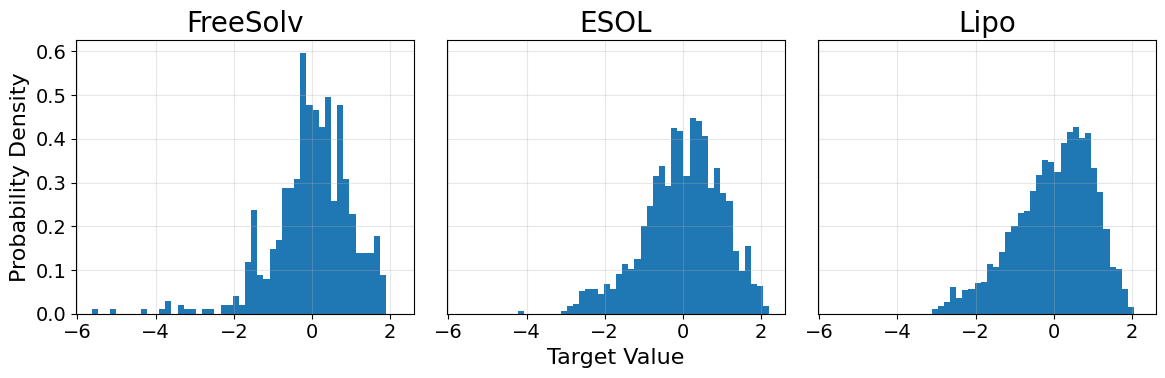

In [76]:
reg_datasets = [
    ("FreeSolv", df_fs, "FreeSolv"),
    ("ESOL", df_esol, "ESOL"),
    ("Lipo", df_lipo, "Lipo"),
]

# 共通ビン範囲
all_values = np.concatenate([
    df[col].dropna().to_numpy()
    for _, df, col in reg_datasets
])

bins = 50
vmin, vmax = all_values.min(), all_values.max()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for i, (ax, (title, df, label_col)) in enumerate(zip(axes, reg_datasets)):
    values = df[label_col].dropna().to_numpy()

    ax.hist(
        values,
        bins=bins,
        range=(vmin, vmax),
        density=True
    )

    # タイトル
    ax.set_title(title)

    # グリッド
    ax.grid(True, alpha=0.3)

    # tickフォントサイズ
    ax.tick_params(axis='both')

    # 左端だけYラベル表示
    if i == 0:
        ax.set_ylabel("Probability Density")
    else:
        ax.set_ylabel("")
        ax.tick_params(axis='y', left=False)

    # 中央だけXラベル表示
    if i == 1:
        ax.set_xlabel("Target Value")
    else:
        ax.set_xlabel("")

plt.tight_layout()
plt.show()

In [77]:
reg_datasets = [
    ("FreeSolv", df_fs, "FreeSolv"),
    ("ESOL", df_esol, "ESOL"),
    ("Lipo", df_lipo, "Lipo"),
]

stats = []

for name, df, col in reg_datasets:
    values = df[col].dropna().to_numpy()
    mean = np.mean(values)
    std = np.std(values, ddof=1)  # ddof=1 → 標本標準偏差（論文向け）
    n = len(values)

    stats.append({
        "Dataset": name,
        "N": n,
        "Mean": mean,
        "Std": std
    })

stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False, float_format="%.4f"))

 Dataset    N    Mean    Std
FreeSolv  642 -0.0000 1.0008
    ESOL 1111 -0.0030 1.0005
    Lipo 4200 -0.0000 1.0001


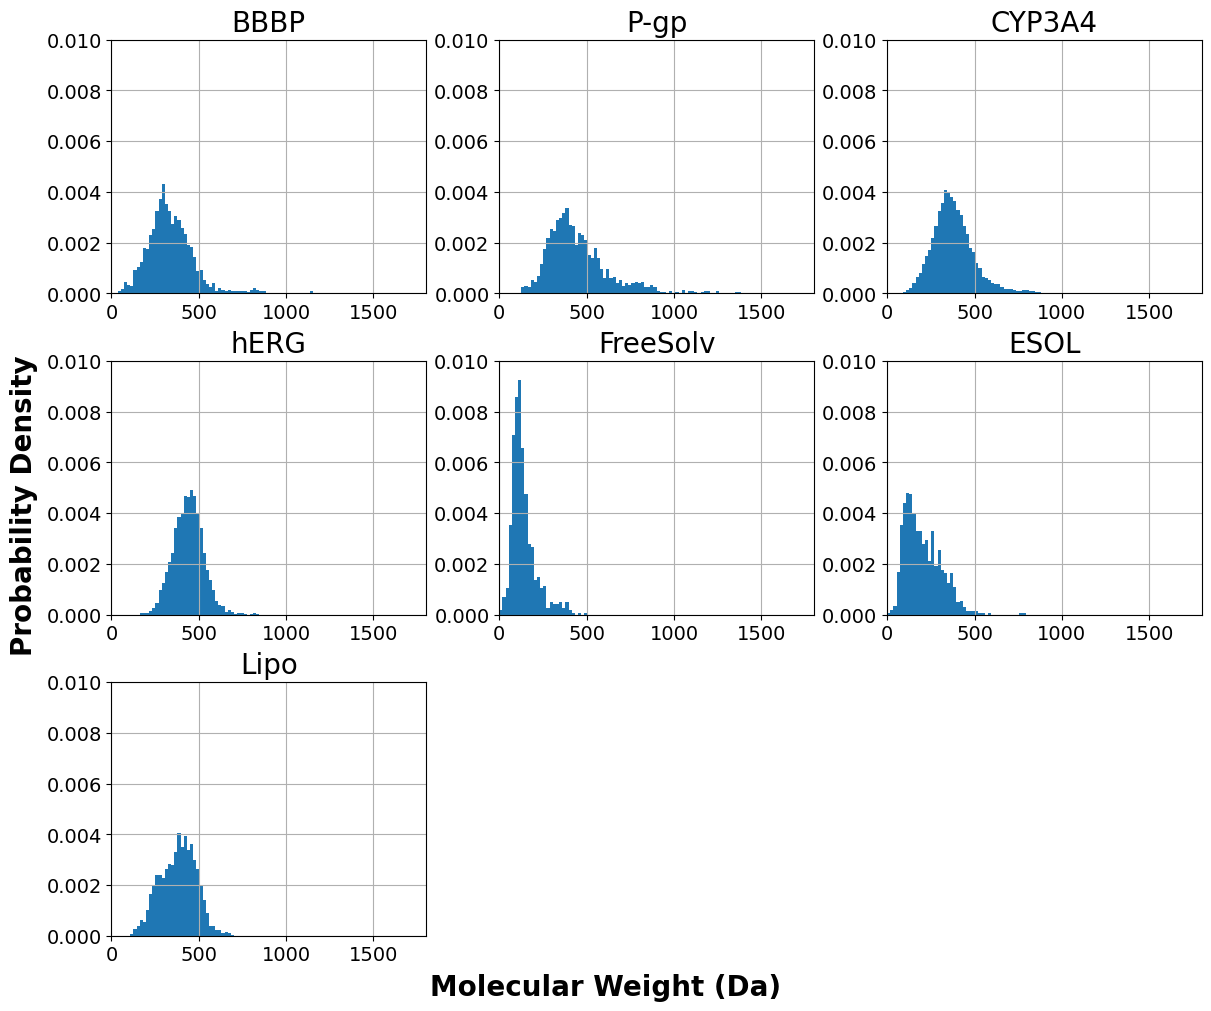

In [78]:
datasets = [
    ("BBBP", df_bbbp),
    ("P-gp", df_pgp),
    ("CYP3A4", df_cyp),
    ("hERG", df_herg),
    ("FreeSolv", df_fs),
    ("ESOL", df_esol),
    ("Lipo", df_lipo),
]

bins = 100
x_range = (0, 1800)

fig, axes = plt.subplots(3, 3, figsize=(12, 10), constrained_layout=True)
axes = axes.flatten()

for i, (title, df) in enumerate(datasets):
    ax = axes[i]
    ax.hist(df["MW"], bins=bins, range=x_range, density=True)
    ax.set_title(title)
    ax.set_xlim(*x_range)
    ax.set_ylim(0, 0.01)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(True)

for j in range(len(datasets), len(axes)):
    fig.delaxes(axes[j])

fig.supxlabel("Molecular Weight (Da)", fontsize=supxlabel_fontsize, fontweight="bold")
fig.supylabel("Probability Density", fontsize=supylabel_fontsize, fontweight="bold")
plt.savefig("mw_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


In [79]:
df_lipo["MW"].describe()

count    4200.000000
mean      382.645238
std       106.851506
min       113.000000
25%       306.000000
50%       388.000000
75%       456.000000
max      1620.000000
Name: MW, dtype: float64

In [80]:
df_esol["MW"].describe()

count    1111.000000
mean      203.386139
std       103.048792
min        16.000000
25%       120.000000
50%       182.000000
75%       270.000000
max       780.000000
Name: MW, dtype: float64